# 4일차 · 근거로 작성하는 생산·품질 업무 보고서

**Let’s Grow with LG Display**

ChatGPT에 요청 → 전체 코드 복사 → Colab 코드 셀에 붙여 실행 → 웹 결과 확인

코드 생성 요청 뒤의 연습 셀에 전체 Python 코드를 붙입니다. 2.3에는 전체 기능을 포함한 기준 코드가 있습니다. 3.6의 문장 개선 답변은 웹의 보고서 본문 칸에 붙입니다. 백업·복원은 필요할 때 실행하므로 전체 셀 일괄 실행은 하지 않습니다.

## 공통 실행 조건

코드 생성·수정 요청마다 아래 조건과 현재 전체 코드를 함께 전달합니다.

```text
Colab Ubuntu의 한 개 Python 코드 셀에서 실행합니다. Flask 설치·서버 실행·Cloudflared 임시 주소 출력을 포함하세요. Three.js 0.170.0과 같은 버전의 OrbitControls를 사용하고 importmap을 설정하세요. 통신은 async/await로 처리합니다. API 키 없이 실행하세요. 셀 재실행 시 이 실습의 서버와 터널만 종료하세요. /content/04_lgd_web/04_reports.json에 보고서 목록·본문·검토 상태·생성 근거를 저장하고 기존 파일이 있으면 읽으세요. 파일명은 04_ 접두의 영어 이름으로 작성하세요. 이미지 base64는 사용하지 않습니다. 부분 교체 없이 생략 없는 전체 Python 코드를 제공하세요.
```

교육용 가상 기록과 모의 설비를 사용합니다. 별도 LLM API 키를 입력하지 않습니다.
Colab Python CPU 런타임과 브라우저 WebGL을 사용합니다. 무료 Colab에서 웹 UI 중심 사용이 제한될 수 있어 교육 환경에서 사전 접속을 확인합니다. ChatGPT 구독은 Colab 이용권을 포함하지 않습니다.

## 1.1 4일차 | 근거로 쓰는 보고서

### 오늘의 업무 상황

생산·품질·설비 현황을 다음 업무 담당자에게 설명합니다. 수치만 나열하면 어느 기간과 라인의 결과인지 알기 어렵습니다. 범위와 근거가 드러나는 보고서를 작성합니다.

### 완성할 서비스

기간·라인별 집계, 일자별 불량률 비교, Three.js 설비 화면, 보고서 초안 생성, 본문 검토·저장과 파일 다운로드를 구현합니다.

### 실습 방법

ChatGPT에 요청하고 전체 코드를 Colab에 붙여 실행합니다. 화면의 결과를 예상 값과 대조하고, 구체적인 수정 요청으로 개선합니다. LG디스플레이 직무 이해를 위한 가상 프로젝트입니다.

## 1.2 오늘의 프로젝트 진행

네 구간을 각 2시간씩 진행합니다. 총 8시간이며 점심은 제외합니다.

| 시간 | 주요 활동 | 남길 결과 |
| --- | --- | --- |
| 08:30–10:30 | 보고 범위와 계산 기준 | 예상 값·요구 사항 |
| 10:30–12:30 | 조회·비교 화면 구현 | 웹 주소와 검증 기록 |
| 12:30–13:30 | 점심 | 교육시간 제외 |
| 13:30–15:30 | 초안 생성과 근거 검토 | 검토한 보고서 |
| 15:30–17:30 | 저장·공유·팀 검증 | 최종 파일과 검증표 |



## 1.3 보고서가 답할 질문

### 생산은 얼마나 진행되었습니까?

조회 기간과 라인의 목표 생산량·생산 실적을 함께 제시합니다. 달성률만 적지 않고 계산에 사용한 수량도 남깁니다.

### 품질에서 무엇을 확인했습니까?

검사 수량과 불량 수량, 불량률을 적습니다. 표본 크기가 다른 기록의 비율을 비교할 때 분모도 함께 확인합니다.

### 설비 사건은 어떻게 처리되었습니까?

해당 기간에 발생한 사건과 기록된 최종 상태를 제시합니다. 현재 모의 상태는 별도 항목으로 적고, 확인하지 않은 원인을 확정하지 않습니다.

## 1.4 집계에 사용할 가상 수치

수량 단위는 개입니다. 9월 9일은 검사 0개인 A13 기록도 포함합니다.

| 범위 | 목표 / 생산 | 검사 / 불량 |
| --- | --- | --- |
| 9월 8일 전체 | 1,800 / 1,450 | 400 / 10 |
| 9월 9일 전체 | 1,900 / 1,700 | 600 / 12 |
| 9월 9일 A | 1,100 / 950 | 350 / 5 |
| 9월 9일 B | 800 / 750 | 250 / 7 |
| 두 날짜 전체 | 3,700 / 3,150 | 1,000 / 22 |

실제 LG디스플레이의 실적이나 공정 기준이 아닌 교육용 데이터입니다.

## 1.5 비율은 합계로 계산합니다

### 전체 불량률

두 날짜 전체는 불량 22개 ÷ 검사 1,000개 × 100 = 2.20%입니다. 먼저 수량을 더한 뒤 비율을 계산합니다.

### 일자별 비율과 차이

9월 8일은 2.50%, 9월 9일은 2.00%입니다. 두 비율의 단순 평균 2.25%는 전체 불량률과 다릅니다. 날짜별 검사 수량이 서로 다르기 때문입니다.

### 생산 달성률

9월 9일 전체는 생산 1,700개 ÷ 목표 1,900개 × 100 = 89.47%입니다. 검사 수량과 목표 생산량을 혼동하지 않습니다.

## 1.6 기간과 상태를 구분합니다

### 기간 조회

시작일과 종료일을 모두 포함합니다. 설비 사건은 발생일로 조회합니다. 조회된 사건의 해제 여부는 가상 이력에 기록된 최종 상태입니다.

### 현재 모의 상태

라인 A는 정상 28°C, 라인 B는 온도 주의 42°C인 예입니다. 과거 날짜를 조회해도 현재 모의 상태는 날짜에 따라 바뀌지 않습니다.

### 보고서에 적는 범위

“조회 기간 발생 사건”과 “현재 모의 상태”를 구분합니다. 이 데이터만으로 당시 가동률이나 정확한 정지 시간을 계산하지 않습니다.

## 1.7 ChatGPT로 보고 항목 정리

아래 요청문으로 업무 질문을 보고서 항목으로 바꿉니다.

```text
LG디스플레이 교육용 생산·품질 업무 보고서를 기획합니다. 완전 비전공자가 사용할 웹 서비스입니다.
조회 기간·라인, 생산량과 목표, 검사·불량 수량, 기간에 발생한 설비 사건, 현재 모의 상태를 구분합니다.
각 항목에 필요한 데이터와 확인할 질문을 표로 정리하세요. 불량률은 수량 합계로 계산합니다. 원인·담당자·완료 시간을 추측해 넣지 마세요.
```

답변에 보고 범위, 단위, 분모, 사건 상태의 기준이 있는지 확인합니다.

## 1.8 구현 전 예상 결과

팀원과 계산을 비교하고 예상 값을 기록합니다.

| 조회 조건 | 확인할 결과 |
| --- | --- |
| 9월 9일 전체 | 생산 1,700 / 목표 1,900 / 불량률 2.00% |
| 9월 9일 A | 생산 950 / 검사 350 / 불량률 1.43% |
| 9월 9일 B | 생산 750 / 검사 250 / 불량률 2.80% |
| 9월 8~9일 전체 | 생산 3,150 / 검사 1,000 / 불량률 2.20% |
| 기록 없는 날짜 | 기록 없음, 비율 —, 초안 생성 거부 |

한 명은 실행하고 다른 한 명은 예상 값과 비교한 뒤 역할을 바꿉니다.

| 조건·작업 | 예상 | 실제 | 판정·보완 |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

## 2.1 Colab에서 실행 준비

### 노트북 열기

04_LGD_Vibe_Coding_Day4.ipynb를 Colab에서 업로드하고 Python 런타임에 연결합니다. 노트북의 공통 실행 조건과 요청문을 함께 ChatGPT에 전달합니다.

### 코드 실행

생성된 전체 Python 코드를 연습 셀에 붙여 실행합니다. 출력된 최신 Cloudflared 주소를 브라우저에서 엽니다. 2.3에는 비교용 기준 코드가 있습니다.

### 화면 확인

Colab Ubuntu에서 웹 서버가 실행되고 브라우저에서 Three.js 화면이 표시됩니다. 런타임이나 터널이 종료되면 다시 실행해 최신 주소를 확인합니다.

## 2.2 ChatGPT로 조회 서비스 요청

노트북의 가상 데이터와 공통 실행 조건을 함께 붙입니다.

```text
패널 검사·이송 업무 보고 웹 서비스를 만들어 주세요.
시작일·종료일·라인을 선택하고 조회 적용을 누르면 생산·목표·검사·불량 합계를 보여 주세요. 달성률과 불량률은 합계로 계산하고 분모 0은 —로 표시하세요.
LOT 기록, 일자별 불량률, 발생일 기준 설비 사건을 표시하세요. 현재 모의 상태는 A 정상 28°C, B 온도 주의 42°C로 따로 보여 주세요.
Three.js로 금속 프레임·유리 커버·롤러·패널·검사 헤드를 표현하세요. 전체 Python 코드를 제공하세요.
```

전체 코드 복사 → Colab 코드 셀 실행 → 최신 주소에서 결과 확인입니다.

### 함께 전달할 가상 데이터

```json
{
  "rows": [
    {
      "date": "2026-09-08",
      "line": "A",
      "lot": "A01",
      "target": 500,
      "produced": 400,
      "inspected": 100,
      "defects": 2
    },
    {
      "date": "2026-09-08",
      "line": "A",
      "lot": "A02",
      "target": 500,
      "produced": 400,
      "inspected": 100,
      "defects": 2
    },
    {
      "date": "2026-09-08",
      "line": "B",
      "lot": "B01",
      "target": 400,
      "produced": 300,
      "inspected": 100,
      "defects": 5
    },
    {
      "date": "2026-09-08",
      "line": "B",
      "lot": "B02",
      "target": 400,
      "produced": 350,
      "inspected": 100,
      "defects": 1
    },
    {
      "date": "2026-09-09",
      "line": "A",
      "lot": "A11",
      "target": 500,
      "produced": 450,
      "inspected": 150,
      "defects": 3
    },
    {
      "date": "2026-09-09",
      "line": "A",
      "lot": "A12",
      "target": 500,
      "produced": 500,
      "inspected": 200,
      "defects": 2
    },
    {
      "date": "2026-09-09",
      "line": "B",
      "lot": "B11",
      "target": 400,
      "produced": 350,
      "inspected": 100,
      "defects": 4
    },
    {
      "date": "2026-09-09",
      "line": "B",
      "lot": "B12",
      "target": 400,
      "produced": 400,
      "inspected": 150,
      "defects": 3
    },
    {
      "date": "2026-09-09",
      "line": "A",
      "lot": "A13",
      "target": 100,
      "produced": 0,
      "inspected": 0,
      "defects": 0
    }
  ],
  "events": [
    {
      "id": "E101",
      "date": "2026-09-08",
      "line": "B",
      "title": "모의 정지",
      "resolved": true,
      "note": "모의 정상 복귀 확인"
    },
    {
      "id": "E102",
      "date": "2026-09-09",
      "line": "A",
      "title": "온도 주의",
      "resolved": true,
      "note": "28°C 복귀 확인"
    },
    {
      "id": "E103",
      "date": "2026-09-09",
      "line": "B",
      "title": "온도 주의",
      "resolved": false,
      "note": "42°C 확인, 추가 확인 예정"
    }
  ]
}
```

In [ ]:
# ChatGPT가 생성한 전체 Python 코드를 붙여 넣고 실행합니다.
# ============================================================
# LG Display 교육용
# 패널 검사·이송 업무 보고 웹 서비스
#
# Google Colab 한 셀 실행용 전체 코드
# - Flask 웹 서버
# - Cloudflared 외부 접속
# - HTML / CSS / JavaScript
# - Three.js 3D 설비
# - 조회 기간 / 라인 필터
# - 생산 / 목표 / 검사 / 불량 합계
# - 합계 기반 달성률 / 불량률
# - LOT 기록
# - 일자별 불량률
# - 발생일 기준 설비 사건
# - 현재 모의 상태
# ============================================================

import os
import json
import time
import re
import subprocess
import threading

# ------------------------------------------------------------
# 1. 필요한 패키지 설치
# ------------------------------------------------------------
subprocess.run(
    ["pip", "install", "-q", "flask"],
    check=False
)

# ------------------------------------------------------------
# 2. Cloudflared 설치
# ------------------------------------------------------------
cloudflared_path = "/usr/local/bin/cloudflared"

if not os.path.exists(cloudflared_path):
    subprocess.run(
        [
            "wget",
            "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O",
            cloudflared_path
        ],
        check=True
    )

    subprocess.run(
        ["chmod", "+x", cloudflared_path],
        check=True
    )

# ------------------------------------------------------------
# 3. Flask
# ------------------------------------------------------------
from flask import Flask, render_template_string, jsonify

app = Flask(__name__)

# ------------------------------------------------------------
# 4. 교육용 샘플 데이터
# ------------------------------------------------------------
DATA = {
    "rows": [
        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A01",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },
        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A02",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },
        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B01",
            "target": 400,
            "produced": 300,
            "inspected": 100,
            "defects": 5
        },
        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B02",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 1
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A11",
            "target": 500,
            "produced": 450,
            "inspected": 150,
            "defects": 3
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A12",
            "target": 500,
            "produced": 500,
            "inspected": 200,
            "defects": 2
        },
        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B11",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 4
        },
        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B12",
            "target": 400,
            "produced": 400,
            "inspected": 150,
            "defects": 3
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A13",
            "target": 100,
            "produced": 0,
            "inspected": 0,
            "defects": 0
        }
    ],

    "events": [
        {
            "id": "E101",
            "date": "2026-09-08",
            "line": "B",
            "title": "모의 정지",
            "resolved": True,
            "note": "모의 정상 복귀 확인"
        },
        {
            "id": "E102",
            "date": "2026-09-09",
            "line": "A",
            "title": "온도 주의",
            "resolved": True,
            "note": "28°C 복귀 확인"
        },
        {
            "id": "E103",
            "date": "2026-09-09",
            "line": "B",
            "title": "온도 주의",
            "resolved": False,
            "note": "42°C 확인, 추가 확인 예정"
        }
    ]
}

# ------------------------------------------------------------
# 5. HTML
# ------------------------------------------------------------
HTML = r'''
<!DOCTYPE html>
<html lang="ko">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>패널 검사·이송 업무 보고</title>

<script src="https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/chart.js"></script>

<style>

* {
    box-sizing: border-box;
}

html {
    scroll-behavior: smooth;
}

body {
    margin: 0;
    background: #f6f7fb;
    color: #20212a;
    font-family:
        Pretendard,
        "Noto Sans KR",
        Arial,
        sans-serif;
}

button,
select,
input {
    font-family: inherit;
}

/* ---------------------------------------------------------
   전체 영역
--------------------------------------------------------- */

.page {
    max-width: 1500px;
    margin: auto;
    padding: 30px;
}

/* ---------------------------------------------------------
   제목
--------------------------------------------------------- */

.header {
    margin-bottom: 24px;
}

.header-title {
    margin: 0;
    font-size: 32px;
    font-weight: 800;
    letter-spacing: -1px;
}

.header-desc {
    margin-top: 8px;
    color: #6b6e7c;
    font-size: 18px;
    line-height: 1.6;
}

/* ---------------------------------------------------------
   카드
--------------------------------------------------------- */

.card {
    background: white;
    border: 1px solid #e6e7ec;
    border-radius: 20px;
    padding: 22px;
    box-shadow: 0 7px 24px rgba(35, 37, 50, 0.045);
}

/* ---------------------------------------------------------
   조회 조건
--------------------------------------------------------- */

.search-panel {
    margin-bottom: 20px;
}

.search-title {
    margin-bottom: 16px;
    font-size: 18px;
    font-weight: 800;
}

.filters {
    display: grid;
    grid-template-columns:
        minmax(170px, 1fr)
        minmax(170px, 1fr)
        minmax(150px, .7fr)
        auto;
    gap: 12px;
    align-items: end;
}

.field label {
    display: block;
    margin-bottom: 7px;
    color: #666a78;
    font-size: 13px;
    font-weight: 700;
}

.field input,
.field select {
    width: 100%;
    height: 46px;

    border: 1px solid #dfe1e7;
    border-radius: 11px;

    background: white;

    color: #272934;
    font-size: 15px;

    padding: 0 12px;

    outline: none;
}

.field input:focus,
.field select:focus {
    border-color: #8a3ffc;
    box-shadow: 0 0 0 3px rgba(138, 63, 252, .1);
}

.search-btn {
    border: 0;
    height: 46px;

    border-radius: 11px;

    padding: 0 28px;

    background: #6d28d9;
    color: white;

    font-size: 15px;
    font-weight: 800;

    cursor: pointer;

    transition: .15s ease;
}

.search-btn:hover {
    background: #5b21b6;
    transform: translateY(-1px);
}

/* ---------------------------------------------------------
   조회 범위
--------------------------------------------------------- */

.scope {
    margin-top: 14px;

    padding: 11px 14px;

    background: #faf8ff;

    border: 1px solid #e8ddff;
    border-radius: 11px;

    color: #6034aa;

    font-size: 14px;
    font-weight: 700;
}

/* ---------------------------------------------------------
   KPI
--------------------------------------------------------- */

.kpi-grid {
    display: grid;
    grid-template-columns: repeat(6, 1fr);

    gap: 14px;

    margin-bottom: 20px;
}

.kpi {
    min-height: 126px;

    background: white;

    border: 1px solid #e7e8ed;
    border-radius: 18px;

    padding: 19px;

    box-shadow: 0 6px 20px rgba(0,0,0,.035);
}

.kpi-label {
    color: #777a88;
    font-size: 13px;
    font-weight: 700;
}

.kpi-value {
    margin-top: 13px;

    font-size: 29px;
    font-weight: 850;
    letter-spacing: -.5px;
}

.kpi-unit {
    margin-left: 4px;

    font-size: 14px;
    color: #7b7f8d;
}

.kpi-highlight {
    background: linear-gradient(
        135deg,
        #f9f5ff,
        #ffffff
    );

    border-color: #e4d6ff;
}

.kpi-danger {
    background: linear-gradient(
        135deg,
        #fff5f7,
        white
    );

    border-color: #ffdbe2;
}

/* ---------------------------------------------------------
   메인 컨텐츠
--------------------------------------------------------- */

.main-grid {
    display: grid;

    grid-template-columns:
        minmax(0, 1.45fr)
        minmax(350px, .75fr);

    gap: 20px;

    margin-bottom: 20px;
}

/* ---------------------------------------------------------
   3D
--------------------------------------------------------- */

.three-header {
    display: flex;

    justify-content: space-between;
    align-items: center;

    margin-bottom: 12px;
}

.section-title {
    font-size: 19px;
    font-weight: 850;
}

.section-desc {
    margin-top: 4px;

    font-size: 13px;
    color: #858896;
}

#three-container {
    width: 100%;
    height: 470px;

    overflow: hidden;

    border-radius: 16px;

    background: linear-gradient(
        #f4f5f9,
        #e8eaf0
    );

    position: relative;
}

.three-help {
    position: absolute;
    left: 14px;
    bottom: 12px;

    z-index: 3;

    padding: 7px 10px;

    border-radius: 8px;

    background: rgba(255,255,255,.9);

    font-size: 12px;
    color: #686b77;
}

/* ---------------------------------------------------------
   현재 상태
--------------------------------------------------------- */

.status-wrap {
    display: flex;
    flex-direction: column;
    gap: 14px;
}

.status-box {
    border-radius: 16px;
    border: 1px solid #e3e5ea;
    padding: 18px;
}

.status-normal {
    background: #f2fbf7;
    border-color: #c9eedb;
}

.status-warning {
    background: #fff8eb;
    border-color: #f6d899;
}

.status-top {
    display: flex;
    justify-content: space-between;
    align-items: center;
}

.status-line {
    font-size: 19px;
    font-weight: 850;
}

.badge {
    padding: 6px 10px;

    border-radius: 999px;

    font-size: 12px;
    font-weight: 800;
}

.badge-normal {
    color: #14744a;
    background: #dff6ea;
}

.badge-warning {
    color: #9a6400;
    background: #ffe9ad;
}

.temperature {
    margin-top: 18px;

    font-size: 34px;
    font-weight: 850;
}

.temperature span {
    font-size: 15px;
    color: #787b86;
}

.status-description {
    margin-top: 7px;

    color: #747783;
    font-size: 13px;

    line-height: 1.5;
}

.info-box {
    margin-top: 2px;

    padding: 14px;

    border-radius: 12px;

    background: #f7f7fa;

    color: #6e707d;

    font-size: 13px;
    line-height: 1.65;
}

/* ---------------------------------------------------------
   2열
--------------------------------------------------------- */

.two-grid {
    display: grid;

    grid-template-columns:
        minmax(0, 1fr)
        minmax(0, 1fr);

    gap: 20px;

    margin-bottom: 20px;
}

/* ---------------------------------------------------------
   차트
--------------------------------------------------------- */

.chart-area {
    position: relative;
    height: 285px;

    margin-top: 12px;
}

/* ---------------------------------------------------------
   테이블
--------------------------------------------------------- */

.table-card {
    margin-bottom: 20px;
}

.table-scroll {
    margin-top: 15px;
    overflow-x: auto;
}

table {
    width: 100%;
    border-collapse: collapse;

    min-width: 780px;
}

th,
td {
    padding: 13px 12px;
    text-align: left;
    white-space: nowrap;
}

th {
    background: #f7f7fa;

    border-top: 1px solid #ececf1;
    border-bottom: 1px solid #e4e5ea;

    color: #6f7280;

    font-size: 12px;
    font-weight: 800;
}

td {
    border-bottom: 1px solid #efeff3;

    font-size: 14px;
}

.rate-good {
    color: #19724e;
    font-weight: 800;
}

.rate-bad {
    color: #c24155;
    font-weight: 800;
}

/* ---------------------------------------------------------
   사건
--------------------------------------------------------- */

.event-list {
    margin-top: 14px;

    display: flex;
    flex-direction: column;

    gap: 10px;
}

.event {
    border: 1px solid #e8e8ed;
    border-radius: 13px;

    padding: 15px;
}

.event-top {
    display: flex;

    justify-content: space-between;
    align-items: center;

    gap: 10px;
}

.event-title {
    font-weight: 800;
}

.event-meta {
    margin-top: 6px;

    color: #80828e;

    font-size: 12px;
}

.event-note {
    margin-top: 9px;

    padding: 10px;

    border-radius: 9px;

    background: #f7f7f9;

    font-size: 13px;
}

.resolved {
    color: #217a52;
}

.open {
    color: #d38300;
}

/* ---------------------------------------------------------
   결과 없음
--------------------------------------------------------- */

.empty {
    padding: 38px 20px;

    text-align: center;

    color: #92949e;
}

/* ---------------------------------------------------------
   반응형
--------------------------------------------------------- */

@media(max-width: 1200px) {

    .kpi-grid {
        grid-template-columns: repeat(3, 1fr);
    }

}

@media(max-width: 950px) {

    .main-grid {
        grid-template-columns: 1fr;
    }

    .two-grid {
        grid-template-columns: 1fr;
    }

}

@media(max-width: 760px) {

    .page {
        padding: 16px;
    }

    .header-title {
        font-size: 26px;
    }

    .header-desc {
        font-size: 15px;
    }

    .filters {
        grid-template-columns: 1fr;
    }

    .search-btn {
        width: 100%;
    }

    .kpi-grid {
        grid-template-columns: repeat(2, 1fr);
    }

    #three-container {
        height: 360px;
    }

}

@media(max-width: 480px) {

    .kpi-grid {
        grid-template-columns: 1fr;
    }

}

</style>
</head>

<body>

<div class="page">

    <!-- 제목 -->
    <header class="header">

        <h1 class="header-title">
            패널 검사·이송 업무 보고
        </h1>

        <div class="header-desc">
            교육용 모의 데이터를 이용해 생산 실적, 품질 결과,
            설비 사건과 현재 설비 상태를 확인합니다.
        </div>

    </header>


    <!-- 조회 조건 -->
    <section class="card search-panel">

        <div class="search-title">
            조회 조건
        </div>

        <div class="filters">

            <div class="field">

                <label>
                    시작일
                </label>

                <input
                    type="date"
                    id="startDate"
                    value="2026-09-08"
                >

            </div>


            <div class="field">

                <label>
                    종료일
                </label>

                <input
                    type="date"
                    id="endDate"
                    value="2026-09-09"
                >

            </div>


            <div class="field">

                <label>
                    생산 라인
                </label>

                <select id="lineSelect">

                    <option value="ALL">
                        전체 라인
                    </option>

                    <option value="A">
                        라인 A
                    </option>

                    <option value="B">
                        라인 B
                    </option>

                </select>

            </div>


            <button
                class="search-btn"
                onclick="applyFilter()"
            >
                조회 적용
            </button>

        </div>


        <div
            class="scope"
            id="scopeText"
        >
            조회 범위
        </div>

    </section>


    <!-- KPI -->
    <section class="kpi-grid">

        <div class="kpi">

            <div class="kpi-label">
                생산량
            </div>

            <div class="kpi-value">
                <span id="producedValue">0</span>
                <span class="kpi-unit">개</span>
            </div>

        </div>


        <div class="kpi">

            <div class="kpi-label">
                목표
            </div>

            <div class="kpi-value">
                <span id="targetValue">0</span>
                <span class="kpi-unit">개</span>
            </div>

        </div>


        <div class="kpi kpi-highlight">

            <div class="kpi-label">
                목표 달성률
            </div>

            <div
                class="kpi-value"
                id="achievementValue"
            >
                —
            </div>

        </div>


        <div class="kpi">

            <div class="kpi-label">
                검사 수량
            </div>

            <div class="kpi-value">
                <span id="inspectedValue">0</span>
                <span class="kpi-unit">개</span>
            </div>

        </div>


        <div class="kpi">

            <div class="kpi-label">
                불량 수량
            </div>

            <div class="kpi-value">
                <span id="defectValue">0</span>
                <span class="kpi-unit">개</span>
            </div>

        </div>


        <div class="kpi kpi-danger">

            <div class="kpi-label">
                불량률
            </div>

            <div
                class="kpi-value"
                id="defectRateValue"
            >
                —
            </div>

        </div>

    </section>


    <!-- 3D + 현재 상태 -->
    <section class="main-grid">

        <div class="card">

            <div class="three-header">

                <div>

                    <div class="section-title">
                        패널 검사·이송 설비
                    </div>

                    <div class="section-desc">
                        Three.js 기반 교육용 3D 설비
                    </div>

                </div>

            </div>


            <div id="three-container">

                <div class="three-help">
                    마우스 드래그 : 회전
                </div>

            </div>

        </div>


        <div class="card">

            <div class="section-title">
                현재 모의 상태
            </div>

            <div class="section-desc">
                조회 기간의 설비 사건과 별개의 현재 상태입니다.
            </div>


            <div
                class="status-wrap"
                style="margin-top:18px;"
            >

                <div class="status-box status-normal">

                    <div class="status-top">

                        <div class="status-line">
                            라인 A
                        </div>

                        <span class="badge badge-normal">
                            정상
                        </span>

                    </div>

                    <div class="temperature">
                        28°C
                    </div>

                    <div class="status-description">
                        교육용 현재 모의 상태
                    </div>

                </div>


                <div class="status-box status-warning">

                    <div class="status-top">

                        <div class="status-line">
                            라인 B
                        </div>

                        <span class="badge badge-warning">
                            온도 주의
                        </span>

                    </div>

                    <div class="temperature">
                        42°C
                    </div>

                    <div class="status-description">
                        교육용 온도 주의 상태
                    </div>

                </div>


                <div class="info-box">

                    현재 모의 상태는
                    조회 기간에 발생했던 과거 설비 사건과
                    별도로 표시됩니다.

                    <br><br>

                    실제 설비의 현재 상태를 의미하지 않습니다.

                </div>

            </div>

        </div>

    </section>


    <!-- 일자별 차트 + 사건 -->
    <section class="two-grid">


        <div class="card">

            <div class="section-title">
                일자별 불량률
            </div>

            <div class="section-desc">
                일자별 불량 수량 합계 ÷ 검사 수량 합계 × 100
            </div>

            <div class="chart-area">

                <canvas id="defectChart"></canvas>

            </div>

        </div>


        <div class="card">

            <div class="section-title">
                설비 사건
            </div>

            <div class="section-desc">
                사건의 발생일을 기준으로 조회합니다.
            </div>

            <div
                class="event-list"
                id="eventList"
            ></div>

        </div>


    </section>


    <!-- LOT 기록 -->
    <section class="card table-card">

        <div class="section-title">
            LOT 기록
        </div>

        <div class="section-desc">
            선택한 조회 기간과 생산 라인에 해당하는 기록입니다.
        </div>


        <div class="table-scroll">

            <table>

                <thead>

                    <tr>

                        <th>일자</th>
                        <th>라인</th>
                        <th>LOT</th>
                        <th>목표</th>
                        <th>생산</th>
                        <th>달성률</th>
                        <th>검사</th>
                        <th>불량</th>
                        <th>불량률</th>

                    </tr>

                </thead>

                <tbody id="lotTable">

                </tbody>

            </table>

        </div>

    </section>


</div>


<script>

/* =========================================================
   데이터
========================================================= */

const rawData = {{ data_json | safe }};

const rows = rawData.rows;
const events = rawData.events;

let chart = null;


/* =========================================================
   공통 함수
========================================================= */

function numberFormat(value) {

    return Number(value).toLocaleString("ko-KR");

}


function rate(numerator, denominator) {

    if (!denominator || denominator === 0) {
        return null;
    }

    return numerator / denominator * 100;

}


function displayRate(value) {

    if (value === null || !Number.isFinite(value)) {
        return "—";
    }

    return value.toFixed(2) + "%";

}


/* =========================================================
   조회
========================================================= */

function applyFilter() {

    const start =
        document.getElementById("startDate").value;

    const end =
        document.getElementById("endDate").value;

    const line =
        document.getElementById("lineSelect").value;


    if (!start || !end) {

        alert("시작일과 종료일을 선택해 주세요.");

        return;

    }


    if (start > end) {

        alert("시작일은 종료일보다 늦을 수 없습니다.");

        return;

    }


    const filteredRows =
        rows.filter(row => {

            const dateMatch =
                row.date >= start &&
                row.date <= end;

            const lineMatch =
                line === "ALL" ||
                row.line === line;

            return dateMatch && lineMatch;

        });


    const filteredEvents =
        events.filter(event => {

            const dateMatch =
                event.date >= start &&
                event.date <= end;

            const lineMatch =
                line === "ALL" ||
                event.line === line;

            return dateMatch && lineMatch;

        });


    renderScope(
        start,
        end,
        line
    );

    renderKPI(filteredRows);

    renderLotTable(filteredRows);

    renderDailyChart(filteredRows);

    renderEvents(filteredEvents);

}


/* =========================================================
   조회 범위
========================================================= */

function renderScope(
    start,
    end,
    line
) {

    const lineText =
        line === "ALL"
        ? "전체 라인"
        : `라인 ${line}`;


    document.getElementById(
        "scopeText"
    ).textContent =
        `조회 범위 · ${start} ~ ${end} · ${lineText}`;

}


/* =========================================================
   KPI
========================================================= */

function renderKPI(data) {

    let target = 0;
    let produced = 0;
    let inspected = 0;
    let defects = 0;


    data.forEach(row => {

        target += row.target;
        produced += row.produced;
        inspected += row.inspected;
        defects += row.defects;

    });


    const achievement =
        rate(
            produced,
            target
        );


    const defectRate =
        rate(
            defects,
            inspected
        );


    document.getElementById(
        "targetValue"
    ).textContent =
        numberFormat(target);


    document.getElementById(
        "producedValue"
    ).textContent =
        numberFormat(produced);


    document.getElementById(
        "inspectedValue"
    ).textContent =
        numberFormat(inspected);


    document.getElementById(
        "defectValue"
    ).textContent =
        numberFormat(defects);


    document.getElementById(
        "achievementValue"
    ).textContent =
        displayRate(achievement);


    document.getElementById(
        "defectRateValue"
    ).textContent =
        displayRate(defectRate);

}


/* =========================================================
   LOT TABLE
========================================================= */

function renderLotTable(data) {

    const tbody =
        document.getElementById("lotTable");

    tbody.innerHTML = "";


    if (data.length === 0) {

        tbody.innerHTML = `

            <tr>

                <td colspan="9">

                    <div class="empty">
                        조회 결과가 없습니다.
                    </div>

                </td>

            </tr>

        `;

        return;

    }


    data.forEach(row => {

        const achievement =
            rate(
                row.produced,
                row.target
            );


        const defectRate =
            rate(
                row.defects,
                row.inspected
            );


        const tr =
            document.createElement("tr");


        tr.innerHTML = `

            <td>${row.date}</td>

            <td>
                라인 ${row.line}
            </td>

            <td>
                <strong>${row.lot}</strong>
            </td>

            <td>
                ${numberFormat(row.target)}
            </td>

            <td>
                ${numberFormat(row.produced)}
            </td>

            <td>
                ${displayRate(achievement)}
            </td>

            <td>
                ${numberFormat(row.inspected)}
            </td>

            <td>
                ${numberFormat(row.defects)}
            </td>

            <td class="${
                defectRate !== null &&
                defectRate >= 3
                ? "rate-bad"
                : "rate-good"
            }">

                ${displayRate(defectRate)}

            </td>

        `;


        tbody.appendChild(tr);

    });

}


/* =========================================================
   일자별 불량률
========================================================= */

function renderDailyChart(data) {

    const daily = {};


    data.forEach(row => {

        if (!daily[row.date]) {

            daily[row.date] = {
                inspected: 0,
                defects: 0
            };

        }


        daily[row.date].inspected +=
            row.inspected;


        daily[row.date].defects +=
            row.defects;

    });


    const dates =
        Object.keys(daily).sort();


    const rates =
        dates.map(date => {

            const value =
                rate(
                    daily[date].defects,
                    daily[date].inspected
                );

            return value === null
                ? null
                : Number(value.toFixed(2));

        });


    if (chart) {

        chart.destroy();

    }


    const ctx =
        document.getElementById(
            "defectChart"
        ).getContext("2d");


    chart =
        new Chart(
            ctx,
            {

                type: "bar",

                data: {

                    labels: dates,

                    datasets: [

                        {

                            label: "불량률 (%)",

                            data: rates,

                            backgroundColor:
                                "rgba(109,40,217,.68)",

                            borderColor:
                                "#6d28d9",

                            borderWidth: 1,

                            borderRadius: 7

                        }

                    ]

                },

                options: {

                    responsive: true,

                    maintainAspectRatio: false,

                    plugins: {

                        legend: {
                            display: false
                        },

                        tooltip: {

                            callbacks: {

                                label: context => {

                                    if (
                                        context.raw === null
                                    ) {

                                        return "불량률: —";

                                    }

                                    return (
                                        "불량률: " +
                                        context.raw +
                                        "%"
                                    );

                                }

                            }

                        }

                    },

                    scales: {

                        y: {

                            beginAtZero: true,

                            ticks: {

                                callback:
                                    value =>
                                    value + "%"

                            }

                        },

                        x: {

                            grid: {
                                display: false
                            }

                        }

                    }

                }

            }

        );

}


/* =========================================================
   사건
========================================================= */

function renderEvents(data) {

    const container =
        document.getElementById(
            "eventList"
        );


    container.innerHTML = "";


    if (data.length === 0) {

        container.innerHTML = `

            <div class="empty">
                조회 기간에 발생한 설비 사건이 없습니다.
            </div>

        `;

        return;

    }


    const sorted =
        [...data].sort(
            (a, b) =>
                a.date.localeCompare(b.date)
        );


    sorted.forEach(event => {

        const item =
            document.createElement("div");


        item.className = "event";


        const statusClass =
            event.resolved
            ? "resolved"
            : "open";


        const statusText =
            event.resolved
            ? "해제"
            : "미해제";


        item.innerHTML = `

            <div class="event-top">

                <div class="event-title">

                    ${escapeHTML(event.title)}

                </div>


                <strong class="${statusClass}">

                    ${statusText}

                </strong>

            </div>


            <div class="event-meta">

                ${escapeHTML(event.id)}

                · ${event.date}

                · 라인 ${escapeHTML(event.line)}

            </div>


            <div class="event-note">

                ${escapeHTML(event.note)}

            </div>

        `;


        container.appendChild(item);

    });

}


/* HTML 실행 방지 */
function escapeHTML(value) {

    return String(value)
        .replaceAll("&", "&amp;")
        .replaceAll("<", "&lt;")
        .replaceAll(">", "&gt;")
        .replaceAll('"', "&quot;")
        .replaceAll("'", "&#039;");

}


/* =========================================================
   Three.js
========================================================= */

let scene;
let camera;
let renderer;

let equipment;

let targetRotationX = -0.25;
let targetRotationY = -0.55;

let dragging = false;

let oldMouseX = 0;
let oldMouseY = 0;


/* ---------------------------------------------------------
   초기화
--------------------------------------------------------- */

function initThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    scene =
        new THREE.Scene();


    scene.background =
        new THREE.Color(
            0xf0f1f5
        );


    camera =
        new THREE.PerspectiveCamera(
            44,
            container.clientWidth /
            container.clientHeight,
            0.1,
            1000
        );


    camera.position.set(
        7.5,
        5.5,
        9.5
    );


    camera.lookAt(
        0,
        0,
        0
    );


    renderer =
        new THREE.WebGLRenderer({
            antialias: true
        });


    renderer.setPixelRatio(
        Math.min(
            window.devicePixelRatio,
            2
        )
    );


    renderer.setSize(
        container.clientWidth,
        container.clientHeight
    );


    renderer.shadowMap.enabled = true;

    renderer.shadowMap.type =
        THREE.PCFSoftShadowMap;


    container.appendChild(
        renderer.domElement
    );


    /* 조명 */

    const hemi =
        new THREE.HemisphereLight(
            0xffffff,
            0x8a8d96,
            1.4
        );

    scene.add(hemi);


    const keyLight =
        new THREE.DirectionalLight(
            0xffffff,
            1.4
        );


    keyLight.position.set(
        6,
        10,
        8
    );


    keyLight.castShadow = true;

    scene.add(keyLight);


    const fill =
        new THREE.DirectionalLight(
            0xa8c5ff,
            .5
        );


    fill.position.set(
        -7,
        4,
        -5
    );


    scene.add(fill);


    createEquipment();

    createFloor();

    setupMouse();

    window.addEventListener(
        "resize",
        resizeThree
    );


    animate();

}


/* ---------------------------------------------------------
   Box 생성
--------------------------------------------------------- */

function makeBox(
    w,
    h,
    d,
    color,
    x,
    y,
    z,
    metalness = .25,
    roughness = .45,
    opacity = 1
) {

    const geometry =
        new THREE.BoxGeometry(
            w,
            h,
            d
        );


    const material =
        new THREE.MeshStandardMaterial({
            color: color,
            metalness: metalness,
            roughness: roughness,
            transparent: opacity < 1,
            opacity: opacity
        });


    const mesh =
        new THREE.Mesh(
            geometry,
            material
        );


    mesh.position.set(
        x,
        y,
        z
    );


    mesh.castShadow = true;

    mesh.receiveShadow = true;


    equipment.add(mesh);


    return mesh;

}


/* ---------------------------------------------------------
   설비 모델
--------------------------------------------------------- */

function createEquipment() {

    equipment =
        new THREE.Group();


    scene.add(equipment);


    const metal =
        0x858b92;


    const darkMetal =
        0x555b63;


    /* 하부 프레임 */

    makeBox(
        7.8,
        .35,
        3.8,
        darkMetal,
        0,
        -.8,
        0,
        .8,
        .28
    );


    /* 다리 */

    [
        [-3.4,-1.75,-1.45],
        [ 3.4,-1.75,-1.45],
        [-3.4,-1.75, 1.45],
        [ 3.4,-1.75, 1.45]
    ].forEach(p => {

        makeBox(
            .35,
            1.6,
            .35,
            metal,
            p[0],
            p[1],
            p[2],
            .75,
            .3
        );

    });


    /* 상단 프레임 기둥 */

    [
        [-3.45,1.2,-1.55],
        [ 3.45,1.2,-1.55],
        [-3.45,1.2, 1.55],
        [ 3.45,1.2, 1.55]
    ].forEach(p => {

        makeBox(
            .22,
            4.0,
            .22,
            metal,
            p[0],
            p[1],
            p[2],
            .75,
            .28
        );

    });


    /* 상단 프레임 */

    makeBox(
        7.15,
        .24,
        .24,
        metal,
        0,
        3.15,
        -1.55,
        .75,
        .28
    );


    makeBox(
        7.15,
        .24,
        .24,
        metal,
        0,
        3.15,
        1.55,
        .75,
        .28
    );


    makeBox(
        .24,
        .24,
        3.35,
        metal,
        -3.45,
        3.15,
        0,
        .75,
        .28
    );


    makeBox(
        .24,
        .24,
        3.35,
        metal,
        3.45,
        3.15,
        0,
        .75,
        .28
    );


    /* 유리 커버 */

    makeBox(
        6.6,
        2.65,
        .06,
        0x9cc8e8,
        0,
        1.55,
        1.48,
        .05,
        .15,
        .20
    );


    makeBox(
        6.6,
        2.65,
        .06,
        0x9cc8e8,
        0,
        1.55,
        -1.48,
        .05,
        .15,
        .11
    );


    /* 컨베이어 몸체 */

    makeBox(
        6.6,
        .38,
        2.1,
        0x424750,
        0,
        -.3,
        0,
        .65,
        .35
    );


    /* 롤러 */

    const rollerMaterial =
        new THREE.MeshStandardMaterial({

            color: 0x737982,
            metalness: .8,
            roughness: .28

        });


    for (
        let x = -2.9;
        x <= 2.9;
        x += .58
    ) {

        const geometry =
            new THREE.CylinderGeometry(
                .13,
                .13,
                1.9,
                24
            );


        const roller =
            new THREE.Mesh(
                geometry,
                rollerMaterial
            );


        roller.rotation.x =
            Math.PI / 2;


        roller.position.set(
            x,
            .02,
            0
        );


        roller.castShadow = true;

        equipment.add(roller);

    }


    /* 패널 */

    const panel =
        makeBox(
            2.3,
            .08,
            1.55,
            0x57a6d8,
            -.8,
            .29,
            0,
            .15,
            .2,
            .78
        );


    /* 패널 테두리 */

    const panelBorder =
        new THREE.LineSegments(

            new THREE.EdgesGeometry(
                new THREE.BoxGeometry(
                    2.3,
                    .08,
                    1.55
                )
            ),

            new THREE.LineBasicMaterial({
                color: 0x275779
            })

        );


    panelBorder.position.copy(
        panel.position
    );


    equipment.add(
        panelBorder
    );


    /* 검사 헤드 지지대 */

    makeBox(
        .32,
        2.4,
        .32,
        metal,
        0,
        1.7,
        -1.15,
        .8,
        .28
    );


    makeBox(
        3,
        .28,
        .28,
        metal,
        0,
        2.75,
        -1.15,
        .8,
        .28
    );


    /* 검사 헤드 */

    makeBox(
        1.05,
        .65,
        .78,
        0x3e4650,
        0,
        2.25,
        0,
        .65,
        .28
    );


    /* 검사 센서 */

    makeBox(
        .48,
        .18,
        .48,
        0x252c35,
        0,
        1.86,
        0,
        .3,
        .25
    );


    /* 검사 광 */

    makeBox(
        1.3,
        .025,
        .7,
        0xa8e1ff,
        0,
        1.7,
        0,
        .05,
        .15,
        .28
    );


    /* 상태등 */

    const pole =
        new THREE.Mesh(
            new THREE.CylinderGeometry(
                .065,
                .065,
                1.2,
                16
            ),

            new THREE.MeshStandardMaterial({
                color: 0x4c5158,
                metalness: .7
            })
        );


    pole.position.set(
        2.8,
        3.75,
        -.95
    );


    equipment.add(pole);


    const lampGeometry =
        new THREE.CylinderGeometry(
            .14,
            .14,
            .24,
            20
        );


    const colors = [
        0xe74c3c,
        0xf4c542,
        0x27ae60
    ];


    colors.forEach(
        (color, i) => {

            const lamp =
                new THREE.Mesh(

                    lampGeometry,

                    new THREE.MeshStandardMaterial({
                        color: color,
                        emissive: color,
                        emissiveIntensity: .25
                    })

                );


            lamp.position.set(
                2.8,
                4.18 + i * .28,
                -.95
            );


            equipment.add(lamp);

        }
    );


    equipment.rotation.x =
        targetRotationX;


    equipment.rotation.y =
        targetRotationY;

}


/* ---------------------------------------------------------
   바닥
--------------------------------------------------------- */

function createFloor() {

    const floor =
        new THREE.Mesh(

            new THREE.PlaneGeometry(
                30,
                30
            ),

            new THREE.MeshStandardMaterial({
                color: 0xdedfe5,
                roughness: .8
            })

        );


    floor.rotation.x =
        -Math.PI / 2;


    floor.position.y =
        -2.58;


    floor.receiveShadow = true;


    scene.add(floor);

}


/* ---------------------------------------------------------
   마우스 회전
--------------------------------------------------------- */

function setupMouse() {

    const canvas =
        renderer.domElement;


    canvas.addEventListener(
        "mousedown",
        e => {

            dragging = true;

            oldMouseX =
                e.clientX;

            oldMouseY =
                e.clientY;

        }
    );


    window.addEventListener(
        "mouseup",
        () => {

            dragging = false;

        }
    );


    window.addEventListener(
        "mousemove",
        e => {

            if (!dragging) {
                return;
            }


            const dx =
                e.clientX -
                oldMouseX;


            const dy =
                e.clientY -
                oldMouseY;


            targetRotationY +=
                dx * .007;


            targetRotationX +=
                dy * .004;


            targetRotationX =
                Math.max(
                    -1,
                    Math.min(
                        .6,
                        targetRotationX
                    )
                );


            oldMouseX =
                e.clientX;


            oldMouseY =
                e.clientY;

        }
    );

}


/* ---------------------------------------------------------
   리사이즈
--------------------------------------------------------- */

function resizeThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    if (!container) {
        return;
    }


    camera.aspect =
        container.clientWidth /
        container.clientHeight;


    camera.updateProjectionMatrix();


    renderer.setSize(
        container.clientWidth,
        container.clientHeight
    );

}


/* ---------------------------------------------------------
   애니메이션
--------------------------------------------------------- */

function animate() {

    requestAnimationFrame(
        animate
    );


    if (equipment) {

        equipment.rotation.x +=
            (
                targetRotationX -
                equipment.rotation.x
            ) * .08;


        equipment.rotation.y +=
            (
                targetRotationY -
                equipment.rotation.y
            ) * .08;

    }


    renderer.render(
        scene,
        camera
    );

}


/* =========================================================
   시작
========================================================= */

window.addEventListener(
    "DOMContentLoaded",
    () => {

        initThree();

        applyFilter();

    }
);

</script>

</body>
</html>
'''

# ------------------------------------------------------------
# 6. Flask 라우트
# ------------------------------------------------------------
@app.route("/")
def index():
    return render_template_string(
        HTML,
        data_json=json.dumps(
            DATA,
            ensure_ascii=False
        )
    )


@app.route("/api/data")
def api_data():
    return jsonify(DATA)


@app.route("/health")
def health():
    return {
        "status": "ok"
    }


# ------------------------------------------------------------
# 7. Flask 서버 실행
# ------------------------------------------------------------
PORT = 8000

def run_flask():
    app.run(
        host="0.0.0.0",
        port=PORT,
        debug=False,
        use_reloader=False
    )

server_thread = threading.Thread(
    target=run_flask,
    daemon=True
)

server_thread.start()

time.sleep(2)

print("=" * 65)
print("웹 서버 실행 완료")
print(f"PORT : {PORT}")
print("=" * 65)

# ------------------------------------------------------------
# 8. Cloudflared 기존 프로세스 종료
# ------------------------------------------------------------
subprocess.run(
    ["pkill", "-f", "cloudflared"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(1)

# ------------------------------------------------------------
# 9. Cloudflared 터널 실행
# ------------------------------------------------------------
log_file = "/tmp/cloudflared.log"

with open(log_file, "w") as f:
    tunnel_process = subprocess.Popen(
        [
            cloudflared_path,
            "tunnel",
            "--url",
            f"http://127.0.0.1:{PORT}",
            "--no-autoupdate"
        ],
        stdout=f,
        stderr=subprocess.STDOUT
    )

# ------------------------------------------------------------
# 10. 공개 URL 검색
# ------------------------------------------------------------
public_url = None

for _ in range(30):

    time.sleep(1)

    if not os.path.exists(log_file):
        continue

    with open(
        log_file,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        log_text = f.read()

    match = re.search(
        r"https://[a-zA-Z0-9\-]+\.trycloudflare\.com",
        log_text
    )

    if match:

        public_url = match.group(0)

        break

# ------------------------------------------------------------
# 11. 링크 출력
# ------------------------------------------------------------
if public_url:

    print()
    print("✅ 외부 접속 주소가 생성되었습니다.")
    print()
    print(public_url)
    print()

    try:
        from IPython.display import display, HTML as IPHTML

        display(
            IPHTML(
                f'''
                <div style="
                    margin-top:18px;
                    padding:20px;
                    border:1px solid #e5e5ea;
                    border-radius:15px;
                    background:#ffffff;
                    font-family:Arial,sans-serif;
                ">

                    <div style="
                        font-size:18px;
                        font-weight:700;
                        margin-bottom:12px;
                    ">
                        패널 검사·이송 업무 보고
                    </div>

                    <a
                        href="{public_url}"
                        target="_blank"
                        style="
                            display:inline-block;
                            padding:13px 22px;
                            background:#6d28d9;
                            color:white;
                            text-decoration:none;
                            border-radius:10px;
                            font-weight:700;
                        "
                    >
                        웹 서비스 열기
                    </a>

                </div>
                '''
            )
        )

    except Exception:
        pass

else:

    print()
    print("⚠️ Cloudflared 주소를 찾지 못했습니다.")
    print()
    print("아래 로그를 확인하세요.")
    print()

    if os.path.exists(log_file):

        with open(
            log_file,
            "r",
            encoding="utf-8",
            errors="ignore"
        ) as f:

            print(f.read())

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:8000
 * Running on http://172.28.0.12:8000
INFO:werkzeug:Press CTRL+C to quit


웹 서버 실행 완료
PORT : 8000

✅ 외부 접속 주소가 생성되었습니다.

https://setup-involves-stuck-occasions.trycloudflare.com



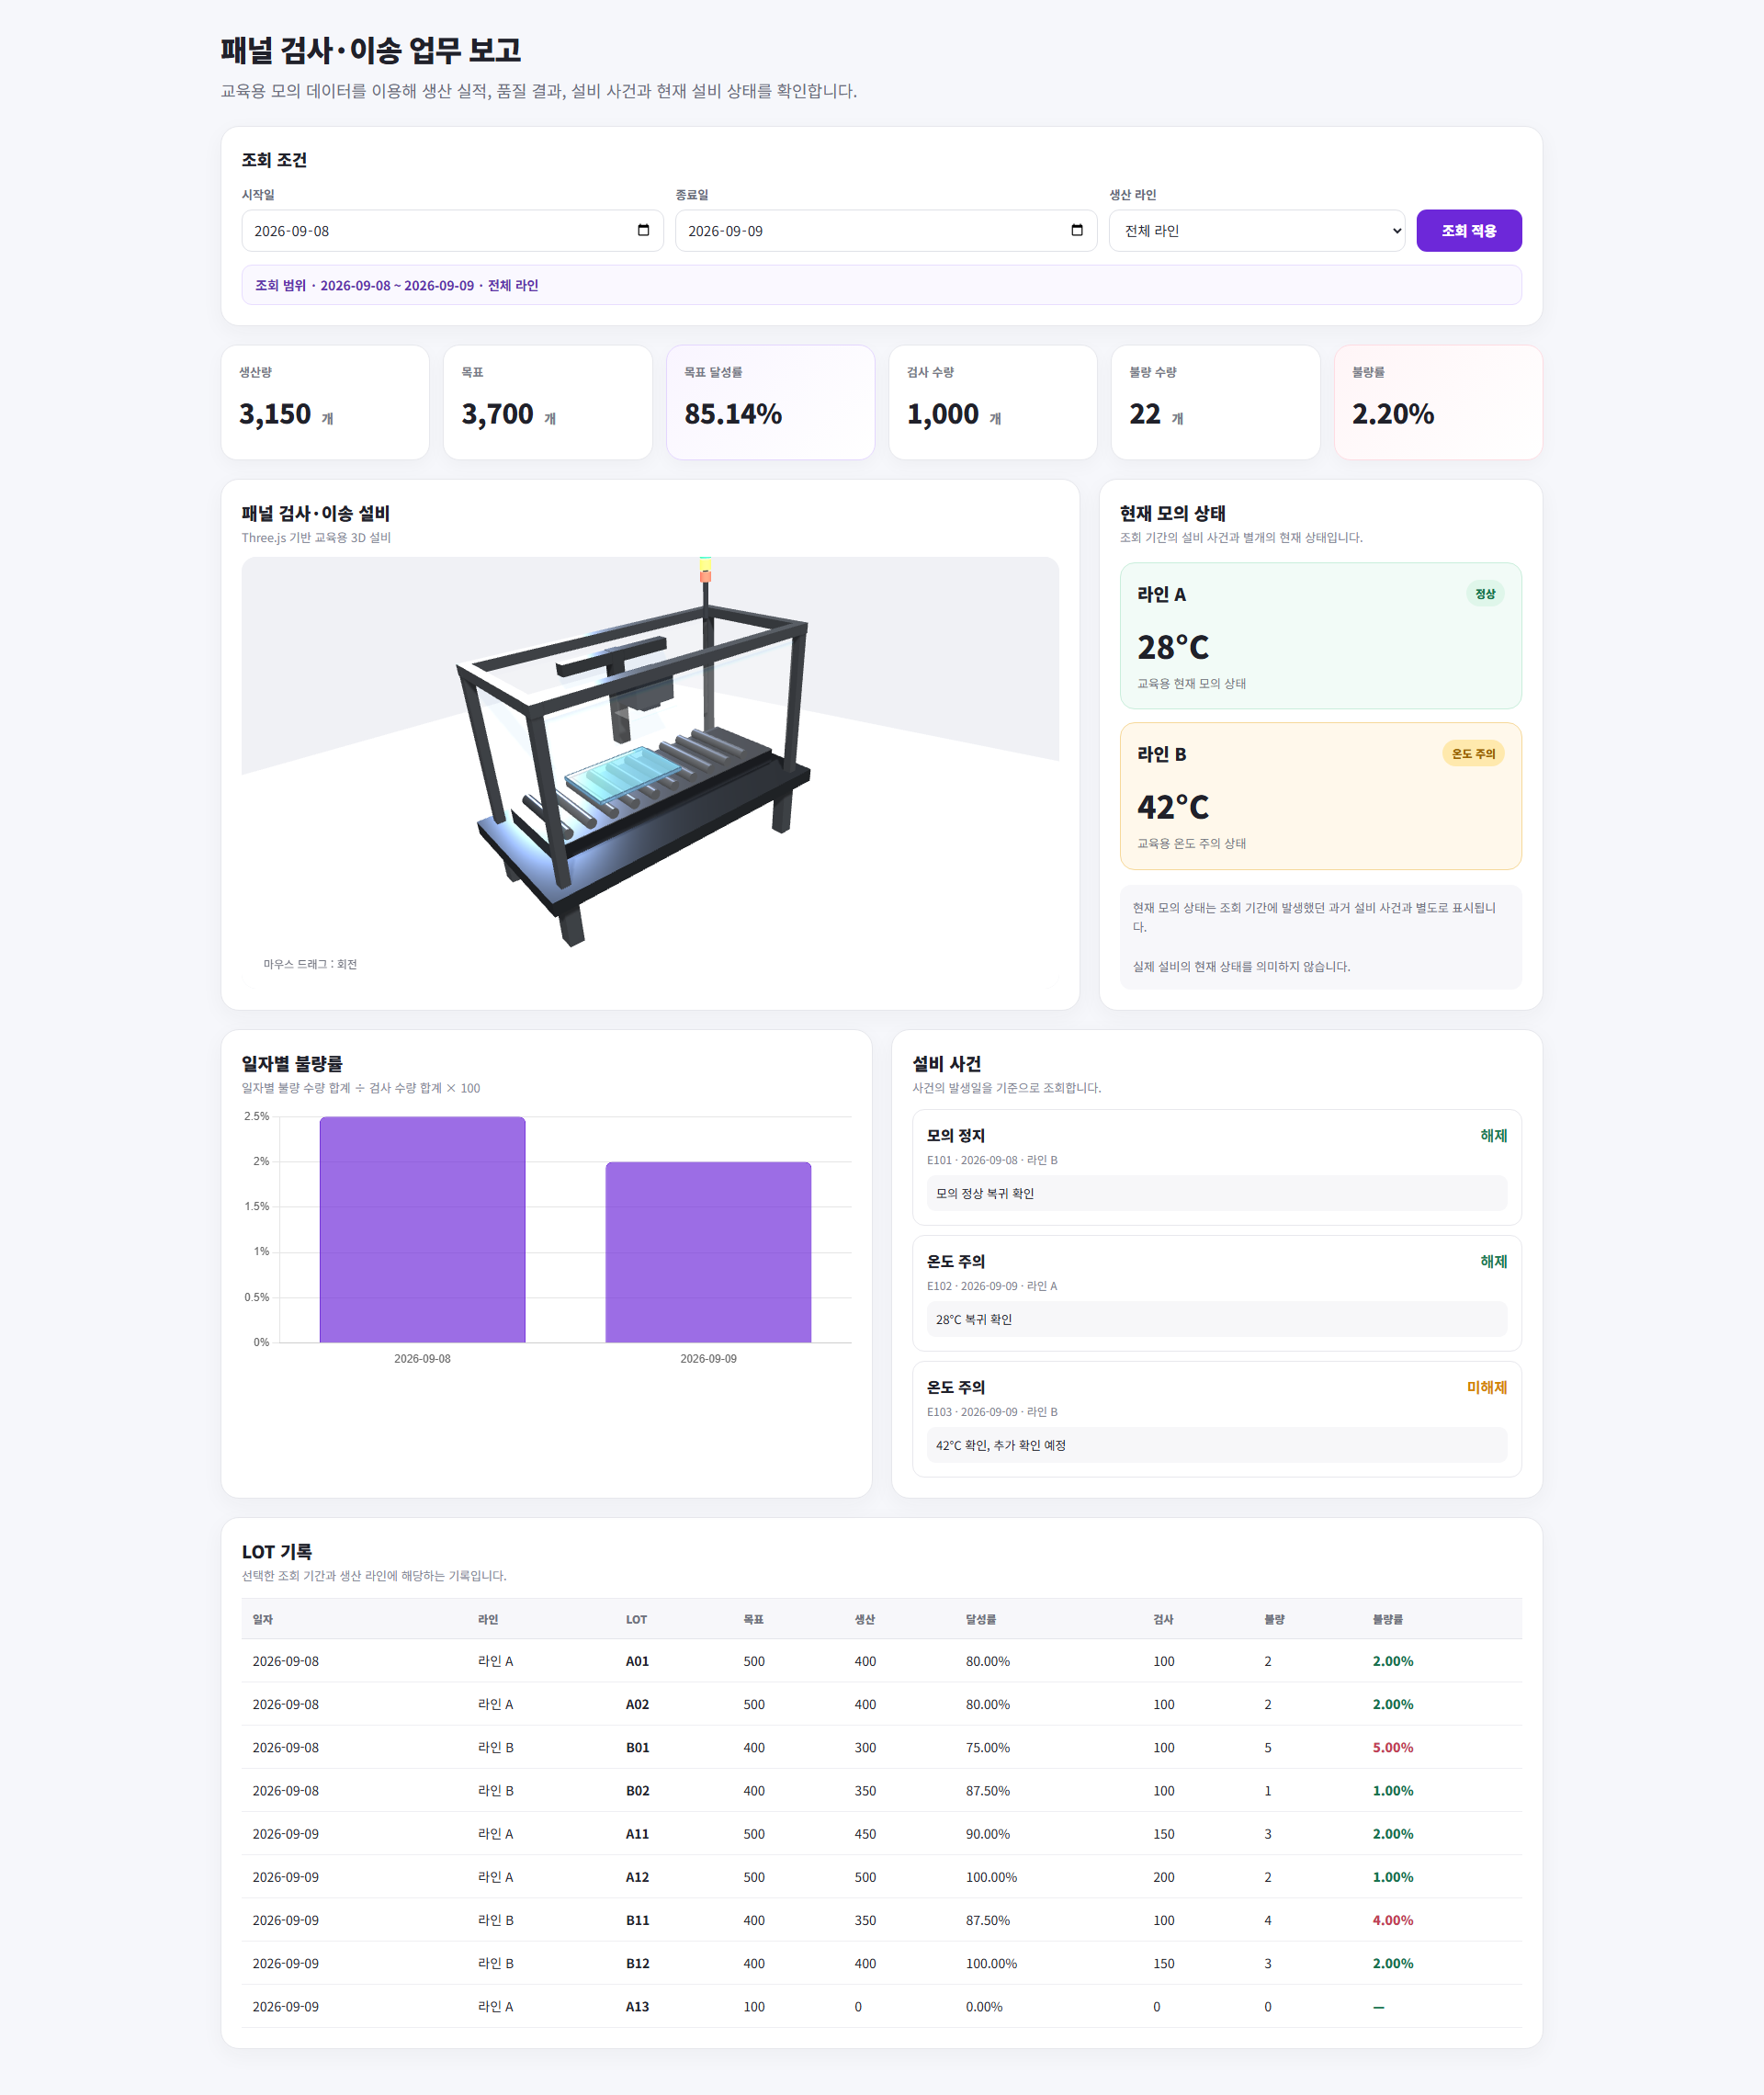

## 2.3 기준 코드로 실행 확인

### 기준 코드 실행

노트북 2.3의 전체 코드 셀을 실행합니다. 준비가 끝나면 출력된 주소를 엽니다. 초기 조회 범위는 2026-09-09, 전체 라인입니다.

### 초기 수치

생산 1,700개 / 목표 1,900개, 달성률 89.47%, 검사 600개 / 불량 12개, 불량률 2.00%를 확인합니다. LOT 기록은 5건입니다.

### 설비 이력과 현재 상태

조회 기간에 발생한 사건은 E102와 E103입니다. E102는 해제, E103은 미해제입니다. 현재 모의 3D 표시는 라인 A 정상입니다.

In [ ]:
import asyncio
import importlib.util
import json
import os
from pathlib import Path
import re
import socket
import subprocess
import sys
import threading
import urllib.request
from IPython.display import display, HTML as DisplayHTML

# ChatGPT 수정 요청 시 HTML_PAGE와 기능을 포함한 셀 전체를 전달합니다.
HTML_PAGE = r'''<!doctype html><html lang="ko"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>LGD 업무 보고서</title><style>*{box-sizing:border-box}body{margin:0;background:#eff2f6;color:#18212e;font:16px system-ui,-apple-system,'Noto Sans CJK KR',sans-serif}main{max-width:1400px;margin:auto;padding:26px}header{display:flex;justify-content:space-between;align-items:center;gap:20px;margin-bottom:22px}h1{font-size:30px;margin:7px 0}h2{font-size:20px;margin:0}small{color:#a50034;font-weight:700;letter-spacing:1px}.muted{color:#5b6573;line-height:1.6;margin:5px 0}.badge{background:#fff;padding:12px 17px;border-radius:8px;white-space:nowrap;font-weight:700}.metrics{display:grid;grid-template-columns:repeat(4,1fr);gap:16px;margin-bottom:20px}.metric{background:#fff;padding:18px 22px;border-top:3px solid #a50034;border-radius:8px}.metric strong{display:block;font-size:32px;margin:9px 0}.metric label{color:#5b6573;font-size:14px}.grid{display:grid;grid-template-columns:minmax(0,2.15fr) minmax(280px,1fr);gap:20px}.panel{background:#fff;border:1px solid #dbe1e8;border-radius:10px;overflow:hidden}.panelHead{padding:18px 20px;border-bottom:1px solid #e4e8ed;display:flex;align-items:center;justify-content:space-between}#viewport{height:475px;position:relative;background:#172331}#viewport canvas{display:block;touch-action:none;width:100%;height:100%}.hint{font-size:13px;line-height:1.5;background:#eef3f7;padding:12px 20px;color:#586575}#webglMessage{position:absolute;top:15px;left:15px;right:15px;color:#fff;background:#29425bdc;padding:12px;border-radius:6px;font-size:14px;pointer-events:none}.controls{padding:20px}button{font:inherit;font-weight:700;cursor:pointer;border:1px solid #ccd4de;background:#fff;color:#203145;border-radius:6px;padding:12px 15px}button:disabled{opacity:.5;cursor:wait}.primary{background:#a50034;color:#fff;border-color:#a50034}.secondary{background:#164c66;color:#fff;border-color:#164c66}.buttons{display:flex;gap:9px;flex-wrap:wrap;margin:16px 0}.status{font-size:24px;font-weight:750;color:#136749;margin:16px 0}.list{display:grid;grid-template-columns:1fr 1fr;gap:12px;border-top:1px solid #eee;padding-top:16px}.list dt{color:#6a7483}.list dd{margin:0;text-align:right;font-weight:700}.log{padding:12px;background:#f3f6f9;border-radius:6px;font-size:14px;line-height:1.7;min-height:72px;margin-top:16px}footer{font-size:13px;color:#687384;margin-top:16px;line-height:1.5}#connection{font-size:13px;color:#536b7b}#reset{padding:7px 10px;font-size:13px}@media(max-width:900px){.grid{grid-template-columns:1fr}.metrics{grid-template-columns:repeat(2,1fr)}h1{font-size:25px}header{align-items:flex-start}.badge{font-size:12px}#viewport{height:390px}}</style><style>
.filters,.reportbox{background:white;border-radius:8px;padding:20px;margin-bottom:20px}.filters{display:flex;gap:18px;align-items:end;flex-wrap:wrap}label{display:block}input,select,textarea{font:inherit;padding:10px;border:1px solid #b7c4d0;border-radius:5px}label input,label select{display:block;margin-top:7px}textarea{width:100%;height:350px;line-height:1.65}table{border-collapse:collapse;width:100%;background:white}td,th{text-align:left;padding:12px;border-bottom:1px solid #ddd}.scroll{overflow:auto}h2{margin-bottom:14px}pre{white-space:pre-wrap;line-height:1.65}.metrics strong{font-size:28px}#viewport{height:320px}.bar{height:18px;background:#a50034;border-radius:3px}.barbg{background:#f4e6eb}.row{display:grid;grid-template-columns:120px 1fr 120px;gap:12px;margin:15px 0}.reviewlabel{display:flex;align-items:center;gap:12px;margin:15px 0}.reviewlabel input{margin:0}#message{color:#a50034;min-height:25px}#reports{max-width:100%}.two{display:grid;grid-template-columns:1fr 1fr;gap:20px}@media(max-width:800px){.two{grid-template-columns:1fr}}
</style><script type="importmap">{"imports":{"three":"/static/vendor/three.module.js","three/addons/":"/static/vendor/"}}</script><body><main>
<header><div><small>LET’S GROW WITH LG DISPLAY · DAY 04</small><h1>근거로 작성하는 생산·품질 보고서</h1><p class="muted">조회 범위를 정하고 수치와 설비 이력을 대조한 뒤 보고서를 보관합니다.</p></div><div class="badge">교육용 가상 데이터</div></header>
<div class="filters"><label>시작일<input id="start" type="date" value="2026-09-09"></label><label>종료일<input id="end" type="date" value="2026-09-09"></label><label>생산라인<select id="line"><option value="all">전체</option><option>A</option><option>B</option></select></label><button id="apply" class="primary">조회 적용</button><button id="make" class="secondary">보고서 초안 만들기</button></div>
<p id="scope"></p><p id="message" role="status"></p>
<section class="metrics"><div class="metric">생산 / 목표<strong id="production">—</strong><label>패널 수 · 개</label></div><div class="metric">생산 달성률<strong id="achievement">—</strong><label>생산 합계 ÷ 목표 합계</label></div><div class="metric">검사 / 불량<strong id="quality">—</strong><label>검사 패널 · 대표 불량 한 가지</label></div><div class="metric">불량률<strong id="rate">—</strong><label>불량 합계 ÷ 검사 합계</label></div></section>
<section class="reportbox" id="evidence"><h2>보고서 근거 · LOT 기록</h2><div class="scroll"><table><thead><tr><th>일자</th><th>라인·LOT</th><th>목표</th><th>생산</th><th>검사</th><th>불량</th></tr></thead><tbody id="rows"></tbody></table></div><div id="bars"></div><h2>조회 기간에 발생한 설비 사건</h2><div id="events"></div><p class="muted">발생일로 조회하며, 상태는 교육용 이력에 기록된 최종 상태입니다. 가동률·고장 원인은 계산하지 않습니다.</p></section>
<section class="grid"><div class="panel"><div class="panelHead"><h2>패널 검사·이송 설비</h2><button id="reset">시점 초기화</button></div><div id="viewport"><div id="webglMessage">3D를 준비합니다.</div></div><div class="hint">마우스 드래그: 회전 · 휠: 확대/축소 · 교육용 모형</div></div><div class="panel controls"><h2>현재 모의 상태</h2><p id="live" class="status"></p><p>과거 조회 기간과 별개인 현재 모의 상태입니다. 전체 선택에서는 라인 A를 표시합니다.</p><p class="muted">A: 정상 28°C / B: 온도 주의 42°C<br>두 라인 모두 모의 이송 중입니다.</p><p>보고서에는 “현재 모의 상태”로 따로 기록합니다.</p></div></section>
<section class="reportbox" style="margin-top:20px" id="editor"><h2>보고서 검토와 저장</h2><label>보관한 보고서<select id="reports"><option value="">선택합니다</option></select></label><p id="reportInfo">조회 후 초안을 만들면 이 영역에 표시합니다.</p><label>보고서 본문<textarea id="body" placeholder="초안을 만든 뒤 사실·추정·추가 확인을 구분해 다듬습니다." maxlength="6000"></textarea></label><label class="reviewlabel"><input id="reviewed" type="checkbox">조회 범위·수치·사건·표현을 근거와 대조했습니다.</label><div class="buttons"><button id="save" class="primary">본문과 검토 상태 저장</button><button id="download">저장본 TXT 내려받기</button><button id="basis">저장본 근거 JSON 내려받기</button></div><p class="muted">다운로드는 마지막 저장본을 사용합니다. 수정 후 저장을 누릅니다. “검토 완료”는 사용자가 점검했다는 기록입니다.</p></section>
<footer>LG디스플레이 직무 이해를 위한 가상 예시입니다. 보고서 초안은 정해진 서식으로 생성되며 별도 LLM API를 호출하지 않습니다.</footer>
</main><script>
const el=id=>document.getElementById(id);window.lgdState={running:false};let scope={start:'2026-09-09',end:'2026-09-09',line:'all'},current=null,busy=false;
const txt=(tag,s)=>{const n=document.createElement(tag);n.textContent=s;return n};
async function request(url,data){const r=await fetch(url,data?{method:'POST',headers:{'Content-Type':'application/json'},body:JSON.stringify(data)}:{cache:'no-store'});const s=await r.json();if(!r.ok)throw Error(s.error||r.status);return s}
async function action(fn){if(busy)return;busy=true;try{await fn()}catch(e){el('message').textContent='확인: '+e.message}finally{busy=false}}
function show(s){el('scope').textContent='적용 범위: '+s.scope.start+' ~ '+s.scope.end+' / '+(s.scope.line==='all'?'전체 라인':'라인 '+s.scope.line);const m=s.metrics;el('production').textContent=m.produced+' / '+m.target;el('achievement').textContent=m.achievement===null?'—':m.achievement.toFixed(2)+'%';el('quality').textContent=m.inspected+' / '+m.defects;el('rate').textContent=m.rate===null?'—':m.rate.toFixed(2)+'%';el('rows').replaceChildren();for(const r of s.rows){const tr=document.createElement('tr');for(const v of [r.date,r.line+'·'+r.lot,r.target,r.produced,r.inspected,r.defects])tr.append(txt('td',v));el('rows').append(tr)}if(!s.rows.length)el('rows').append(txt('tr','조회된 기록이 없습니다.'));
el('bars').replaceChildren(txt('h2','일자별 불량률 · 0~10% 눈금'));for(const r of s.daily){const row=txt('div','');row.className='row';const bg=txt('div','');bg.className='barbg';const b=txt('div','');b.className='bar';b.style.width=Math.min(100,(r.rate||0)*10)+'%';bg.append(b);row.append(txt('span',r.date),bg,txt('span',r.rate===null?'판단 불가':r.rate.toFixed(2)+'%'));el('bars').append(row)}el('events').replaceChildren();for(const e of s.events)el('events').append(txt('p',e.id+' · '+e.date+' · '+e.line+' · '+e.title+' · '+(e.resolved?'해제':'미해제')+' / '+e.note));if(!s.events.length)el('events').append(txt('p','조회 기간에 발생한 사건이 없습니다.'));window.lgdState={running:true,scenario:s.live.line==='A'?'normal':'high'};el('live').textContent='라인 '+s.live.line+' · '+s.live.label+' '+s.live.temperature+'°C';}
async function load(){show(await request('/api/view?'+new URLSearchParams(scope)))}
async function list(){const s=await request('/api/reports');el('reports').replaceChildren(new Option('선택합니다',''));for(const r of s)el('reports').append(new Option(r.id+' · '+r.scope.start+'~'+r.scope.end+' · '+r.scope.line+' · '+(r.reviewed?'검토 완료':'초안'),r.id));if(current)el('reports').value=current.id}
function edit(r){current=r;el('body').value=r.body;el('reviewed').checked=r.reviewed;el('reportInfo').textContent=r.id+' · 생성 '+r.created_at+' · 근거 범위 '+r.scope.start+'~'+r.scope.end+' / '+r.scope.line;}
el('apply').addEventListener('click',()=>action(async()=>{const proposed={start:el('start').value,end:el('end').value,line:el('line').value};const s=await request('/api/view?'+new URLSearchParams(proposed));scope=proposed;show(s);el('message').textContent='조회 범위를 적용했습니다. 기존 보고서의 근거는 유지됩니다.'}));
el('make').addEventListener('click',()=>action(async()=>{edit(await request('/api/report',scope));await list();el('message').textContent='조회 범위의 근거를 고정한 초안을 만들었습니다.';el('editor').scrollIntoView({behavior:'smooth'})}));
el('reports').addEventListener('change',()=>action(async()=>{if(el('reports').value)edit(await request('/api/report/'+el('reports').value))}));
el('save').addEventListener('click',()=>action(async()=>{if(!current)throw Error('먼저 보고서 초안을 만듭니다.');edit(await request('/api/report/'+current.id,{body:el('body').value,reviewed:el('reviewed').checked}));await list();el('message').textContent='본문과 검토 상태를 저장했습니다.'}));
for(const [button,suffix] of [['download','txt'],['basis','json']])el(button).addEventListener('click',()=>{if(!current){el('message').textContent='먼저 보고서를 선택합니다.';return}window.location.href='/api/download/'+current.id+'/'+suffix});
el('body').addEventListener('input',()=>{el('reviewed').checked=false;el('reportInfo').textContent=current?current.id+' · 수정 중: 다시 검토하고 저장합니다.':'먼저 초안을 만듭니다.'});
awaitStart();async function awaitStart(){await action(async()=>{await load();await list()})}
</script><script type="module">
async function init(){try{const THREE=await import('three');const {OrbitControls}=await import('three/addons/OrbitControls.js');const host=document.getElementById('viewport');const scene=new THREE.Scene();scene.background=new THREE.Color(0x172331);scene.fog=new THREE.Fog(0x172331,16,34);const camera=new THREE.PerspectiveCamera(38,1,.1,70);camera.position.set(8.5,6.1,9.2);const renderer=new THREE.WebGLRenderer({antialias:true});renderer.setPixelRatio(Math.min(devicePixelRatio,2));renderer.shadowMap.enabled=true;renderer.shadowMap.type=THREE.PCFSoftShadowMap;renderer.toneMapping=THREE.ACESFilmicToneMapping;renderer.toneMappingExposure=1.25;host.appendChild(renderer.domElement);const controls=new OrbitControls(camera,renderer.domElement);controls.target.set(0,1.5,0);controls.enableDamping=true;controls.minDistance=5;controls.maxDistance=18;controls.maxPolarAngle=Math.PI/2.03;controls.update();document.getElementById('reset').addEventListener('click',async()=>{camera.position.set(8.5,6.1,9.2);controls.target.set(0,1.5,0);controls.update();});
scene.add(new THREE.HemisphereLight(0xdceeff,0x3c424c,2));const key=new THREE.DirectionalLight(0xffffff,3.3);key.position.set(4,10,7);key.castShadow=true;key.shadow.mapSize.set(2048,2048);key.shadow.camera.left=-8;key.shadow.camera.right=8;key.shadow.camera.top=8;key.shadow.camera.bottom=-8;scene.add(key);const fill=new THREE.DirectionalLight(0x72baff,1.7);fill.position.set(-6,4,-5);scene.add(fill);
const mat=(color,metalness=.25,roughness=.4)=>new THREE.MeshStandardMaterial({color,metalness,roughness});const shell=mat(0xdbe2e9,.45,.28),steel=mat(0x8d9ba8,.85,.25),dark=mat(0x182833,.4,.35),blue=mat(0x17647c,.65,.28),belt=mat(0x343d48,.2,.65),black=mat(0x121a22,.6,.25);function box(w,h,d,x,y,z,m,parent=scene){const mesh=new THREE.Mesh(new THREE.BoxGeometry(w,h,d),m);mesh.position.set(x,y,z);mesh.castShadow=true;mesh.receiveShadow=true;parent.add(mesh);return mesh;}function cyl(rad,len,x,y,z,m,rotation=0,parent=scene){const mesh=new THREE.Mesh(new THREE.CylinderGeometry(rad,rad,len,24),m);mesh.position.set(x,y,z);mesh.rotation.x=rotation;mesh.castShadow=true;mesh.receiveShadow=true;parent.add(mesh);return mesh;}
const floor=box(60,.1,60,0,-.15,0,mat(0x263442,.25,.7));const grid=new THREE.GridHelper(40,40,0x52606d,0x374652);grid.position.y=-.09;scene.add(grid);
// Cabinet base, adjustable feet, door seams, vents and fasteners.
box(5.2,.93,2.2,0,.72,0,shell);box(5.35,.16,2.34,0,1.22,0,blue);for(const x of [-2.2,2.2])for(const z of [-.87,.87]){cyl(.11,.38,x,.13,z,steel);cyl(.19,.07,x,-.02,z,dark);}for(const x of [-1.72,0,1.72]){box(1.67,.72,.025,x,.74,1.115,shell);box(.045,.22,.06,x+.58,.8,1.15,steel);}for(let i=0;i<9;i++)box(.32,.021,.025,-2.0,.49+i*.055,1.145,dark);for(const x of [-2.48,2.48])for(const y of [.4,1.05]){const b=cyl(.035,.035,x,y,1.15,steel,Math.PI/2);}
// Long roller conveyor and guide rails.
box(7.0,.13,1.47,0,1.43,0,belt);for(let i=0;i<26;i++)cyl(.065,1.34,-3.28+i*.26,1.53,0,steel,Math.PI/2);for(const z of [-.82,.82]){box(7.1,.17,.11,0,1.6,z,steel);box(7.1,.055,.13,0,1.72,z,blue);}for(const x of [-3.05,3.05])for(const z of [-.68,.68])box(.12,1.2,.12,x,.72,z,steel);
// Inspection enclosure, transparent panels, lintel and inspection camera.
for(const x of [-1.55,1.55])for(const z of [-1,1])box(.13,1.78,.13,x,2.2,z,steel);box(3.28,.22,2.18,0,3.12,0,shell);box(3.28,.12,2.18,0,3.26,0,blue);const glass=new THREE.MeshPhysicalMaterial({color:0x70b9cc,transparent:true,opacity:.17,metalness:.05,roughness:.13,depthWrite:false});box(3.0,1.32,.018,0,2.32,-1,glass);box(3,1.3,.018,0,2.33,1,glass);box(.04,1.32,.035,0,2.32,1.02,steel);box(.05,.3,.065,.16,2.28,1.075,dark);box(2.55,.11,.15,0,2.82,0,steel);box(.7,.3,.48,0,2.58,0,black);cyl(.16,.16,0,2.35,0,black);cyl(.12,.025,0,2.25,0,new THREE.MeshStandardMaterial({color:0x72e7ff,emissive:0x26c8ff,emissiveIntensity:1.5}));const scan=box(.026,.012,1.10,0,1.66,0,new THREE.MeshBasicMaterial({color:0x65e5ff,transparent:true,opacity:.65}));
// Operator station and tower light.
box(.13,.92,.13,2.1,1.72,1.05,steel);box(.73,.51,.12,2.1,2.22,1.03,dark);box(.61,.36,.024,2.1,2.24,1.106,new THREE.MeshStandardMaterial({color:0x177d97,emissive:0x075169,emissiveIntensity:.8}));for(let i=0;i<3;i++)box(.1,.025,.012,1.92+i*.18,2.3,1.123,mat(0x8aeaff));cyl(.045,.42,1.25,3.51,-.75,steel);const green=new THREE.MeshStandardMaterial({color:0x146b48,emissive:0x16c97c,emissiveIntensity:1});const red=new THREE.MeshStandardMaterial({color:0xc72447,emissive:0xf52f51,emissiveIntensity:0});cyl(.09,.15,1.25,3.66,-.75,green);const amber=new THREE.MeshStandardMaterial({color:0xa78420,emissive:0xffb000,emissiveIntensity:0});cyl(.09,.15,1.25,3.83,-.75,amber);cyl(.09,.15,1.25,4,-.75,red);cyl(.1,.04,1.25,4.1,-.75,black);
// Display panels use reflective glass-like surfaces; motion is illustrative.
const panels=[];for(let i=0;i<3;i++){const g=new THREE.Group();box(.98,.055,1.04,0,0,0,dark,g);box(.88,.012,.94,0,.035,0,new THREE.MeshPhysicalMaterial({color:0x163d5a,metalness:.8,roughness:.16,clearcoat:1}),g);box(.018,.014,.9,-.31,.045,0,blue,g);g.position.set(-2.8+i*2.5,1.63,0);scene.add(g);panels.push(g);}const clock=new THREE.Clock();function resize(){const w=host.clientWidth,h=host.clientHeight;renderer.setSize(w,h);camera.aspect=w/h;camera.updateProjectionMatrix();}new ResizeObserver(resize).observe(host);resize();function animate(){requestAnimationFrame(animate);const dt=Math.min(clock.getDelta(),.05);const running=window.lgdState.running;for(const panel of panels){if(running){panel.position.x+=dt*.6;if(panel.position.x>3.6)panel.position.x=-3.6;}}const mode=window.lgdState.scenario;green.emissiveIntensity=mode==="normal"?1.7:0;amber.emissiveIntensity=mode==="high"?1.7:0;red.emissiveIntensity=mode==="stopped"?.9:0;scan.visible=running;controls.update();renderer.render(scene,camera);}animate();document.getElementById('webglMessage').style.display='none';window.lgd3DReady=true;}catch(error){document.getElementById('webglMessage').textContent='3D 표시를 확인해 주세요. 브라우저의 WebGL·하드웨어 가속 또는 새로고침을 확인합니다. '+error.message;window.lgd3DError=String(error);}}await init();
</script></body></html>
'''

async def _lgd_download(url, destination):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 1000:
        return
    def transfer():
        req = urllib.request.Request(url, headers={"User-Agent": "LGD-Education/1.0"})
        with urllib.request.urlopen(req, timeout=60) as response:
            content = response.read()
        if len(content) < 1000:
            raise RuntimeError("다운로드 결과가 너무 작습니다: " + destination.name)
        temporary = destination.with_suffix(destination.suffix + ".tmp")
        temporary.write_bytes(content)
        temporary.replace(destination)
    for attempt in range(3):
        try:
            await asyncio.to_thread(transfer)
            return
        except Exception:
            if attempt == 2:
                raise
            await asyncio.sleep(2)

async def _lgd_start():
    global _LGD_DAY4_SERVER, _LGD_DAY4_TUNNEL, _LGD_DAY4_LOG
    if importlib.util.find_spec("flask") is None:
        print("웹 서버 구성요소를 설치합니다.", flush=True)
        await asyncio.to_thread(subprocess.check_call, [sys.executable, "-m", "pip", "-q", "install", "flask==3.1.2"])
        import site
        site.addsitedir(site.getusersitepackages())
        importlib.invalidate_caches()
    from flask import Flask, jsonify, request, make_response
    from werkzeug.serving import make_server
    import logging
    logging.getLogger("werkzeug").setLevel(logging.ERROR)
    root = Path(os.environ.get("LGD_DAY4_ROOT", "/content/04_lgd_web"))
    vendor = root / "static" / "vendor"
    vendor.mkdir(parents=True, exist_ok=True)
    (root / "04_dashboard.html").write_text(HTML_PAGE, encoding="utf-8")
    print("1/3 Three.js 구성요소를 준비합니다.", flush=True)
    await _lgd_download("https://cdn.jsdelivr.net/npm/three@0.170.0/build/three.module.js", vendor / "three.module.js")
    await _lgd_download("https://cdn.jsdelivr.net/npm/three@0.170.0/examples/jsm/controls/OrbitControls.js", vendor / "OrbitControls.js")
    # 이 셀이 생성한 서버와 터널만 종료한 뒤 재실행합니다.
    old_tunnel = globals().get("_LGD_DAY4_TUNNEL")
    if old_tunnel and old_tunnel.poll() is None:
        old_tunnel.terminate()
        try:
            await asyncio.to_thread(old_tunnel.wait, 5)
        except subprocess.TimeoutExpired:
            old_tunnel.kill()
            await asyncio.to_thread(old_tunnel.wait, 5)
    old_log = globals().get("_LGD_DAY4_LOG")
    if old_log:
        old_log.close()
    old_server = globals().get("_LGD_DAY4_SERVER")
    if old_server:
        await asyncio.to_thread(old_server.shutdown)
        old_server.server_close()
    # 다른 실습이 쓰는 포트는 건드리지 않고 빈 포트를 선택합니다.
    port = None
    for candidate in range(8000, 8021):
        with socket.socket() as probe:
            try:
                probe.bind(("127.0.0.1", candidate))
                port = candidate
                break
            except OSError:
                continue
    if port is None:
        raise RuntimeError("사용 가능한 포트가 없습니다. 현재 런타임의 다른 실습을 확인해 주세요.")
    app = Flask("lgd_day4", static_folder=str(root / "static"))
    import copy, math
    from datetime import datetime, timezone, timedelta, date
    seed = {'rows': [{'date': '2026-09-08', 'line': 'A', 'lot': 'A01', 'target': 500, 'produced': 400, 'inspected': 100, 'defects': 2}, {'date': '2026-09-08', 'line': 'A', 'lot': 'A02', 'target': 500, 'produced': 400, 'inspected': 100, 'defects': 2}, {'date': '2026-09-08', 'line': 'B', 'lot': 'B01', 'target': 400, 'produced': 300, 'inspected': 100, 'defects': 5}, {'date': '2026-09-08', 'line': 'B', 'lot': 'B02', 'target': 400, 'produced': 350, 'inspected': 100, 'defects': 1}, {'date': '2026-09-09', 'line': 'A', 'lot': 'A11', 'target': 500, 'produced': 450, 'inspected': 150, 'defects': 3}, {'date': '2026-09-09', 'line': 'A', 'lot': 'A12', 'target': 500, 'produced': 500, 'inspected': 200, 'defects': 2}, {'date': '2026-09-09', 'line': 'B', 'lot': 'B11', 'target': 400, 'produced': 350, 'inspected': 100, 'defects': 4}, {'date': '2026-09-09', 'line': 'B', 'lot': 'B12', 'target': 400, 'produced': 400, 'inspected': 150, 'defects': 3}, {'date': '2026-09-09', 'line': 'A', 'lot': 'A13', 'target': 100, 'produced': 0, 'inspected': 0, 'defects': 0}], 'events': [{'id': 'E101', 'date': '2026-09-08', 'line': 'B', 'title': '모의 정지', 'resolved': True, 'note': '모의 정상 복귀 확인'}, {'id': 'E102', 'date': '2026-09-09', 'line': 'A', 'title': '온도 주의', 'resolved': True, 'note': '28°C 복귀 확인'}, {'id': 'E103', 'date': '2026-09-09', 'line': 'B', 'title': '온도 주의', 'resolved': False, 'note': '42°C 확인, 추가 확인 예정'}]}
    data_path = root / '04_reports.json'
    state = json.loads(data_path.read_text(encoding='utf-8')) if data_path.exists() else {'reports':[], 'next_id':1}
    lock = threading.Lock()
    def now(): return datetime.now(timezone(timedelta(hours=9))).isoformat(timespec='seconds')
    def commit(proposed):
        temporary=data_path.with_suffix('.tmp');temporary.write_text(json.dumps(proposed,ensure_ascii=False,indent=2),encoding='utf-8');temporary.replace(data_path)
        state.clear();state.update(proposed)
    def summarize(rows):
        m={k:sum(r[k] for r in rows) for k in ['target','produced','inspected','defects']}
        m['rate']=m['defects']/m['inspected']*100 if m['inspected'] else None
        m['achievement']=m['produced']/m['target']*100 if m['target'] else None
        return m
    def view_scope(values):
        scope={k:values.get(k,'') for k in ['start','end','line']}
        start=date.fromisoformat(scope['start']);end=date.fromisoformat(scope['end'])
        if start>end or scope['line'] not in ['all','A','B']:raise ValueError('期間')
        rows=[r for r in seed['rows'] if scope['start']<=r['date']<=scope['end'] and (scope['line']=='all' or scope['line']==r['line'])]
        events=[e for e in seed['events'] if scope['start']<=e['date']<=scope['end'] and (scope['line']=='all' or scope['line']==e['line'])]
        line='A' if scope['line']=='all' else scope['line']
        daily=[dict(date=d,**summarize([r for r in rows if r['date']==d])) for d in sorted({r['date'] for r in rows})]
        return dict(scope=scope,rows=rows,events=events,metrics=summarize(rows),daily=daily,live=dict(line=line,label='정상' if line=='A' else '온도 주의',temperature=28 if line=='A' else 42))
    def text_report(s):
        m=s['metrics'];q=s['scope'];live=s['live']
        pct=lambda v:'판단 불가' if v is None else f'{v:.2f}%'
        lines=['생산·품질 업무 보고서 — 교육용 초안',f"조회 범위: {q['start']} ~ {q['end']} / {q['line']}",'',f"생산: {m['produced']}개 / 목표 {m['target']}개, 달성률 {pct(m['achievement'])}",f"품질: 검사 {m['inspected']}개 / 불량 {m['defects']}개, 불량률 {pct(m['rate'])}",f"조회 LOT 기록: {len(s['rows'])}건",'',f"조회 기간 발생 사건: {len(s['events'])}건 / 최종 미해제 {sum(not e['resolved'] for e in s['events'])}건"]
        lines += [f"{e['id']} / {e['line']} / {e['title']} / {'해제' if e['resolved'] else '미해제'} / {e['note']}" for e in s['events']]
        lines += ['',f"현재 모의 상태(과거 집계와 별도): 라인 {live['line']}, {live['label']}, {live['temperature']}°C",'','추가 확인: 수치의 조회 범위와 사건 기록을 대조합니다. 불량 원인은 확인되지 않았습니다.','검토 메모: [관찰한 근거와 필요한 후속 확인을 작성합니다.]']
        return '\n'.join(lines)
    @app.get('/')
    def index():return HTML_PAGE
    @app.get('/health')
    def health():return jsonify(ok=True)
    @app.get('/api/view')
    def view():
        try:return jsonify(view_scope(request.args))
        except (ValueError,TypeError):return jsonify(error='날짜 범위와 라인을 확인합니다.'),400
    @app.get('/api/reports')
    def reports():
        with lock:return jsonify([dict(id=r['id'],scope=r['scope'],reviewed=r['reviewed']) for r in reversed(state['reports'])])
    @app.post('/api/report')
    def create():
        try:s=view_scope(request.get_json(silent=True) or {})
        except (ValueError,TypeError,AttributeError):return jsonify(error='날짜 범위와 라인을 확인합니다.'),400
        if not s['rows']:return jsonify(error='조회 기록이 없어 보고서를 만들 수 없습니다.'),400
        with lock:
            proposed=copy.deepcopy(state);r=dict(id=f"R{proposed['next_id']:03d}",created_at=now(),updated_at=now(),scope=s['scope'],evidence=s,body=text_report(s),reviewed=False)
            proposed['reports'].append(r);proposed['next_id']+=1
            try:commit(proposed)
            except OSError:return jsonify(error='저장에 실패했습니다.'),500
            return jsonify(r)
    @app.route('/api/report/<rid>',methods=['GET','POST'])
    def report(rid):
        with lock:
            r=next((r for r in state['reports'] if r['id']==rid),None)
            if r is None:return jsonify(error='보고서를 찾을 수 없습니다.'),404
            if request.method=='GET':return jsonify(r)
            d=request.get_json(silent=True)
            if not isinstance(d,dict) or not isinstance(d.get('body'),str) or not 1<=len(d['body'].strip())<=6000 or not isinstance(d.get('reviewed'),bool):return jsonify(error='본문 1~6000자와 검토 상태를 확인합니다.'),400
            proposed=copy.deepcopy(state);r=next(r for r in proposed['reports'] if r['id']==rid);r.update(body=d['body'].strip(),reviewed=d['reviewed'],updated_at=now())
            try:commit(proposed)
            except OSError:return jsonify(error='저장에 실패했습니다.'),500
            return jsonify(r)
    @app.get('/api/download/<rid>/<kind>')
    def download(rid,kind):
        with lock:r=copy.deepcopy(next((r for r in state['reports'] if r['id']==rid),None))
        if r is None or kind not in ['txt','json']:return jsonify(error='저장본을 확인합니다.'),404
        content=json.dumps(r['evidence'],ensure_ascii=False,indent=2) if kind=='json' else f"{r['id']} / {'검토 완료' if r['reviewed'] else '초안'} / 저장 {r['updated_at']}\n\n"+r['body']
        response=make_response(content);response.headers['Content-Type']='application/json; charset=utf-8' if kind=='json' else 'text/plain; charset=utf-8';response.headers['Content-Disposition']=f'attachment; filename="04_LGD_{rid}.{kind}"';return response
    _LGD_DAY4_SERVER = make_server("127.0.0.1", port, app, threaded=True)
    threading.Thread(target=_LGD_DAY4_SERVER.serve_forever, daemon=True).start()
    local_url = f"http://127.0.0.1:{port}"
    def check_health():
        with urllib.request.urlopen(local_url + "/health", timeout=10) as response:
            return json.load(response)
    assert (await asyncio.to_thread(check_health))["ok"]
    print("2/3 웹 서버가 실행되었습니다.", flush=True)
    if os.environ.get("LGD_DAY4_LOCAL_TEST") == "1":
        print(local_url)
        return local_url
    cloudflared = root / "cloudflared"
    await _lgd_download("https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", cloudflared)
    cloudflared.chmod(0o755)
    log_path = root / "04_cloudflared.log"
    _LGD_DAY4_LOG = log_path.open("w", encoding="utf-8")
    _LGD_DAY4_TUNNEL = subprocess.Popen(
        [str(cloudflared), "tunnel", "--url", local_url, "--protocol", "http2", "--no-autoupdate"],
        stdout=_LGD_DAY4_LOG, stderr=subprocess.STDOUT,
    )
    print("3/3 Cloudflared 접속 주소를 생성합니다. 잠시 기다려 주세요.", flush=True)
    public_url = None
    for _ in range(90):
        await asyncio.sleep(1)
        log_text = log_path.read_text(encoding="utf-8", errors="replace")
        match = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", log_text)
        if match:
            public_url = match.group(0)
            break
        if _LGD_DAY4_TUNNEL.poll() is not None:
            break
    if not public_url:
        print(log_path.read_text(encoding="utf-8", errors="replace")[-1800:])
        raise RuntimeError("접속 주소를 만들지 못했습니다. 마지막 오류 문구를 확인한 뒤 셀을 다시 실행해 주세요.")
    print("웹 화면 주소:", public_url)
    display(DisplayHTML(f'<p><a href="{public_url}" target="_blank" rel="noopener noreferrer" style="font-size:20px;font-weight:bold">디스플레이 실습 화면 열기</a></p>'))
    print("주소가 생성되어도 접속 준비에 잠시 시간이 걸릴 수 있습니다. 새 탭으로 열어 확인합니다.")
    print("Colab 런타임을 유지하세요. 다시 실행하면 주소가 바뀔 수 있습니다.")
    return public_url

await _lgd_start()


## 2.4 조회 결과를 읽습니다

기준 코드의 초기 조회 결과입니다. 범위와 수치를 함께 대조합니다.

조회한 수량과 보고서의 수량이 일치해야 합니다.

교안의 화면과 본인 실행 결과를 비교합니다.

**실제 확인한 수치·상태:**

## 2.5 기간·라인을 바꾸어 봅니다

### 기간을 넓힙니다

시작일을 2026-09-08, 종료일을 2026-09-09로 바꾸고 조회 적용을 누릅니다. 전체 검사 1,000개, 불량 22개, 불량률 2.20%를 확인합니다.

### 라인을 좁힙니다

기간을 9월 9일로 되돌리고 라인 B를 적용합니다. 생산 750개, 검사 250개, 불량 7개, 불량률 2.80%입니다. 현재 모의 상태는 B 온도 주의입니다.

### 적용한 범위를 읽습니다

입력값을 바꾸기만 하면 기존 조회 결과가 유지됩니다. 조회 적용을 누른 뒤 상단의 “적용 범위”를 확인합니다. 초안은 이 범위를 사용합니다.

## 2.6 차트로 비교할 때 확인합니다

### 같은 눈금

일자별 막대는 0~10%의 동일한 눈금을 사용합니다. 9월 8일 2.50%, 9월 9일 2.00%의 길이와 표시 숫자를 비교합니다.

### 분모도 함께 봅니다

9월 8일 검사는 400개, 9월 9일은 600개입니다. 수량 차이를 함께 적어야 비율 변화의 의미를 설명할 수 있습니다.

### 변화와 원인

불량률이 0.50%p 낮아진 것은 관찰 사실입니다. 이 변화만으로 특정 조치가 효과를 냈다고 판단하지 않습니다. 원인을 확인하려면 추가 근거가 필요합니다.

## 2.7 현재 모의 설비를 확인합니다

라인 B의 현재 모의 상태와 Three.js 설비 표현을 확인합니다.

현재 모의 상태는 과거 조회 기간의 상태를 재현한 값이 아닙니다.

교안의 화면과 본인 실행 결과를 비교합니다.

**실제 확인한 수치·상태:**

## 2.8 조회 기능 검증표

조건별 실제 결과와 통과 여부를 노트북에 기록합니다.

| 검증 작업 | 통과 기준 |
| --- | --- |
| 두 날짜 전체 적용 | 불량률 2.20%, 사건 3건 |
| 9월 9일 B 적용 | 불량률 2.80%, 사건 E103 |
| 시작일이 종료일보다 뒤 | 범위 안내, 기존 조회 유지 |
| 기록 없는 날짜 적용 | 기록 없음, 비율 — |
| 전체 라인으로 복귀 | 현재 모의 3D는 라인 A |

필터를 바꾼 뒤 예상 값과 다르면 범위와 분모부터 확인합니다.

| 조건·작업 | 예상 | 실제 | 판정·보완 |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

## 3.1 초안을 만드는 순서

### 근거 조회

보고할 기간과 라인을 적용하고 표·합계·사건을 확인합니다. 보고서 제목보다 먼저 보고 범위를 확정합니다.

### 초안 생성

“보고서 초안 만들기”를 누르면 현재 적용한 범위의 수치와 사건을 서식에 넣습니다. 기준 앱은 정해진 서식을 사용하며 별도 LLM API를 호출하지 않습니다.

### 본문 검토

사실·추정·추가 확인을 구분해 문장을 다듬습니다. ChatGPT로 문장을 개선할 때도 제공한 근거 밖의 내용을 추가하지 않도록 요청합니다.

## 3.2 ChatGPT로 초안 기능 요청

현재 전체 코드와 함께 기능 추가를 요청합니다.

```text
현재 조회·Three.js 기능을 유지하고 보고서 초안 만들기 기능을 추가해 주세요.
적용된 기간과 라인의 LOT 기록·합계·사건을 근거로 보관하고, 해당 값만으로 서식형 초안을 작성하세요. 보고서 번호와 생성 시각을 부여하세요.
초안을 만든 뒤 조회 조건을 바꾸어도 그 보고서의 근거는 바꾸지 마세요. 기록이 없으면 생성을 거부하세요. 현재 모의 상태는 별도 항목으로 적으세요.
전체 Python 코드를 제공하세요.
```

노트북 2.3의 기준 코드는 초안 생성과 보관 기능을 포함합니다.

In [ ]:
# ChatGPT가 생성한 전체 Python 코드를 붙여 넣고 실행합니다.
# ============================================================
# LG Display 교육용
# 패널 검사·이송 업무 보고 웹 서비스
#
# Google Colab 한 셀 실행용
#
# 기능
# - 시작일 / 종료일 / 라인 조회
# - 생산 / 목표 / 검사 / 불량 합계
# - 합계 기준 달성률 / 불량률
# - 분모 0 -> —
# - LOT 기록
# - 일자별 불량률
# - 발생일 기준 설비 사건
# - 현재 모의 상태
# - Three.js 3D 검사·이송 설비
# - 보고서 초안 생성
# - 보고서 번호 / 생성 시각
# - 보고서 생성 시 조회 근거 Snapshot 저장
# - 조회 조건 변경 후에도 기존 보고서 데이터 유지
# - Flask + Cloudflared
# ============================================================

import os
import json
import time
import re
import subprocess
import threading

# ------------------------------------------------------------
# 1. 패키지 설치
# ------------------------------------------------------------
subprocess.run(
    ["pip", "install", "-q", "flask"],
    check=False
)

# ------------------------------------------------------------
# 2. Cloudflared 설치
# ------------------------------------------------------------
CLOUDFLARED = "/usr/local/bin/cloudflared"

if not os.path.exists(CLOUDFLARED):
    subprocess.run(
        [
            "wget",
            "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O",
            CLOUDFLARED
        ],
        check=True
    )

    subprocess.run(
        ["chmod", "+x", CLOUDFLARED],
        check=True
    )

# ------------------------------------------------------------
# 3. Flask
# ------------------------------------------------------------
from flask import Flask, render_template_string, jsonify

app = Flask(__name__)

# ------------------------------------------------------------
# 4. 교육용 데이터
# ------------------------------------------------------------
DATA = {
    "rows": [
        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A01",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },
        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A02",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },
        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B01",
            "target": 400,
            "produced": 300,
            "inspected": 100,
            "defects": 5
        },
        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B02",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 1
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A11",
            "target": 500,
            "produced": 450,
            "inspected": 150,
            "defects": 3
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A12",
            "target": 500,
            "produced": 500,
            "inspected": 200,
            "defects": 2
        },
        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B11",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 4
        },
        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B12",
            "target": 400,
            "produced": 400,
            "inspected": 150,
            "defects": 3
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A13",
            "target": 100,
            "produced": 0,
            "inspected": 0,
            "defects": 0
        }
    ],

    "events": [
        {
            "id": "E101",
            "date": "2026-09-08",
            "line": "B",
            "title": "모의 정지",
            "resolved": True,
            "note": "모의 정상 복귀 확인"
        },
        {
            "id": "E102",
            "date": "2026-09-09",
            "line": "A",
            "title": "온도 주의",
            "resolved": True,
            "note": "28°C 복귀 확인"
        },
        {
            "id": "E103",
            "date": "2026-09-09",
            "line": "B",
            "title": "온도 주의",
            "resolved": False,
            "note": "42°C 확인, 추가 확인 예정"
        }
    ]
}

# ------------------------------------------------------------
# 5. HTML
# ------------------------------------------------------------
HTML = r'''
<!DOCTYPE html>
<html lang="ko">

<head>

<meta charset="UTF-8">

<meta
    name="viewport"
    content="width=device-width, initial-scale=1.0"
>

<title>
패널 검사·이송 업무 보고
</title>

<script src="https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js"></script>

<script src="https://cdn.jsdelivr.net/npm/chart.js"></script>


<style>

* {
    box-sizing: border-box;
}

body {

    margin: 0;

    background: #f6f7fb;

    color: #20212a;

    font-family:
        Pretendard,
        "Noto Sans KR",
        Arial,
        sans-serif;

}


button,
input,
select {

    font-family: inherit;

}


.page {

    max-width: 1500px;

    margin: auto;

    padding: 30px;

}


/* =========================================================
   HEADER
========================================================= */

.header {

    margin-bottom: 24px;

}


.header-title {

    margin: 0;

    font-size: 32px;

    font-weight: 850;

}


.header-desc {

    margin-top: 8px;

    font-size: 18px;

    color: #747784;

}


/* =========================================================
   CARD
========================================================= */

.card {

    background: white;

    border: 1px solid #e6e7ec;

    border-radius: 20px;

    padding: 22px;

    box-shadow:
        0 7px 24px
        rgba(35, 37, 50, .045);

}


/* =========================================================
   FILTER
========================================================= */

.search-panel {

    margin-bottom: 20px;

}


.section-title {

    font-size: 19px;

    font-weight: 850;

}


.section-desc {

    margin-top: 5px;

    color: #818491;

    font-size: 13px;

}


.filters {

    display: grid;

    grid-template-columns:
        minmax(160px,1fr)
        minmax(160px,1fr)
        minmax(150px,.7fr)
        auto;

    gap: 12px;

    align-items: end;

    margin-top: 17px;

}


.field label {

    display: block;

    margin-bottom: 7px;

    font-size: 13px;

    color: #676a76;

    font-weight: 700;

}


.field input,
.field select {

    width: 100%;

    height: 46px;

    padding: 0 12px;

    border:

        1px solid #dfe1e7;

    border-radius: 11px;

    background: white;

    font-size: 15px;

}


.primary-btn {

    height: 46px;

    padding: 0 25px;

    border: 0;

    border-radius: 11px;

    background: #6d28d9;

    color: white;

    font-weight: 800;

    cursor: pointer;

}


.primary-btn:hover {

    background: #5b21b6;

}


.scope {

    margin-top: 14px;

    padding: 11px 14px;

    background: #faf8ff;

    border:
        1px solid #eadfff;

    border-radius: 11px;

    color: #6034aa;

    font-size: 14px;

    font-weight: 700;

}


/* =========================================================
   KPI
========================================================= */

.kpi-grid {

    display: grid;

    grid-template-columns:
        repeat(6,1fr);

    gap: 14px;

    margin-bottom: 20px;

}


.kpi {

    min-height: 126px;

    padding: 19px;

    background: white;

    border:
        1px solid #e7e8ed;

    border-radius: 18px;

}


.kpi-label {

    color: #777a88;

    font-size: 13px;

    font-weight: 700;

}


.kpi-value {

    margin-top: 13px;

    font-size: 29px;

    font-weight: 850;

}


.kpi-unit {

    margin-left: 3px;

    color: #7b7f8d;

    font-size: 14px;

}


.purple {

    background:
        linear-gradient(
            135deg,
            #f7f1ff,
            white
        );

}


.red {

    background:
        linear-gradient(
            135deg,
            #fff3f6,
            white
        );

}


/* =========================================================
   MAIN
========================================================= */

.main-grid {

    display: grid;

    grid-template-columns:
        minmax(0,1.4fr)
        minmax(330px,.7fr);

    gap: 20px;

    margin-bottom: 20px;

}


#three-container {

    position: relative;

    width: 100%;

    height: 450px;

    margin-top: 15px;

    overflow: hidden;

    border-radius: 16px;

    background:
        linear-gradient(
            #f4f5f9,
            #e9eaf0
        );

}


.three-help {

    position: absolute;

    z-index: 5;

    bottom: 12px;

    left: 12px;

    padding: 7px 10px;

    background:
        rgba(255,255,255,.9);

    border-radius: 8px;

    color: #666;

    font-size: 12px;

}


/* =========================================================
   STATUS
========================================================= */

.status-box {

    margin-top: 14px;

    padding: 18px;

    border-radius: 15px;

}


.status-normal {

    background: #effaf4;

    border:
        1px solid #c9ebda;

}


.status-warning {

    background: #fff8e9;

    border:
        1px solid #f2d593;

}


.status-top {

    display: flex;

    justify-content: space-between;

    align-items: center;

}


.status-line {

    font-weight: 850;

}


.badge {

    padding: 6px 10px;

    border-radius: 999px;

    font-size: 12px;

    font-weight: 800;

}


.normal-badge {

    color: #16764c;

    background: #d9f3e5;

}


.warning-badge {

    color: #936200;

    background: #ffe9aa;

}


.temp {

    margin-top: 14px;

    font-size: 32px;

    font-weight: 850;

}


/* =========================================================
   TWO COLUMN
========================================================= */

.two-grid {

    display: grid;

    grid-template-columns:
        1fr
        1fr;

    gap: 20px;

    margin-bottom: 20px;

}


.chart-area {

    height: 285px;

    margin-top: 12px;

}


/* =========================================================
   TABLE
========================================================= */

.table-card {

    margin-bottom: 20px;

}


.table-scroll {

    overflow-x: auto;

    margin-top: 14px;

}


table {

    width: 100%;

    min-width: 800px;

    border-collapse: collapse;

}


th,
td {

    padding: 13px 12px;

    text-align: left;

    white-space: nowrap;

}


th {

    background: #f7f7fa;

    color: #6c6f7b;

    font-size: 12px;

    border-bottom:
        1px solid #e3e4e9;

}


td {

    font-size: 14px;

    border-bottom:
        1px solid #efeff3;

}


/* =========================================================
   EVENTS
========================================================= */

.event-list {

    display: flex;

    flex-direction: column;

    gap: 10px;

    margin-top: 14px;

}


.event {

    padding: 15px;

    border:
        1px solid #e8e8ed;

    border-radius: 13px;

}


.event-title {

    font-weight: 850;

}


.event-meta {

    margin-top: 6px;

    color: #81838d;

    font-size: 12px;

}


.event-note {

    margin-top: 9px;

    padding: 10px;

    background: #f7f7f9;

    border-radius: 8px;

    font-size: 13px;

}


/* =========================================================
   REPORT
========================================================= */

.report-control {

    margin-bottom: 20px;

}


.report-toolbar {

    display: flex;

    justify-content: space-between;

    align-items: center;

    gap: 15px;

}


.report-btn {

    padding:
        13px
        22px;

    border: 0;

    border-radius: 11px;

    background: #262833;

    color: white;

    font-weight: 800;

    cursor: pointer;

}


.report-btn:hover {

    background: #101116;

}


.report-btn:disabled {

    opacity: .45;

    cursor: not-allowed;

}


.report-container {

    margin-top: 18px;

}


.report-paper {

    padding: 28px;

    border:
        1px solid #dcdee5;

    border-radius: 16px;

    background: #fff;

}


.report-header {

    padding-bottom: 18px;

    border-bottom:
        2px solid #292b34;

}


.report-name {

    font-size: 27px;

    font-weight: 900;

}


.report-meta {

    margin-top: 10px;

    color: #6f727d;

    font-size: 13px;

    line-height: 1.8;

}


.report-section {

    margin-top: 25px;

}


.report-section h3 {

    margin:
        0
        0
        11px;

    font-size: 17px;

}


.report-summary {

    display: grid;

    grid-template-columns:
        repeat(3,1fr);

    gap: 10px;

}


.report-summary-item {

    padding: 14px;

    background: #f7f7fa;

    border-radius: 11px;

}


.report-summary-label {

    color: #747783;

    font-size: 12px;

}


.report-summary-value {

    margin-top: 5px;

    font-size: 19px;

    font-weight: 850;

}


.report-text {

    line-height: 1.75;

    color: #454753;

}


.snapshot-notice {

    margin-top: 18px;

    padding: 12px 14px;

    border-radius: 10px;

    background: #eef6ff;

    color: #376084;

    font-size: 13px;

}


.report-list {

    margin: 0;

    padding-left: 21px;

    line-height: 1.8;

}


.empty {

    padding: 28px;

    text-align: center;

    color: #92949e;

}


/* =========================================================
   Responsive
========================================================= */

@media(max-width:1200px) {

    .kpi-grid {
        grid-template-columns:
            repeat(3,1fr);
    }

}


@media(max-width:950px) {

    .main-grid,
    .two-grid {

        grid-template-columns: 1fr;

    }

}


@media(max-width:760px) {

    .page {
        padding: 15px;
    }

    .header-title {
        font-size: 26px;
    }

    .filters {

        grid-template-columns: 1fr;

    }

    .primary-btn {

        width: 100%;

    }

    .kpi-grid {

        grid-template-columns:
            repeat(2,1fr);

    }

    .report-toolbar {

        align-items: stretch;

        flex-direction: column;

    }

    .report-summary {

        grid-template-columns:
            1fr
            1fr;

    }

}

</style>

</head>


<body>

<div class="page">


<!-- ======================================================
     HEADER
======================================================= -->

<header class="header">

    <h1 class="header-title">
        패널 검사·이송 업무 보고
    </h1>

    <div class="header-desc">

        교육용 모의 데이터를 기반으로
        생산·품질 실적과 설비 사건을 조회하고
        보고서 초안을 작성합니다.

    </div>

</header>


<!-- ======================================================
     SEARCH
======================================================= -->

<section class="card search-panel">

    <div class="section-title">
        조회 조건
    </div>


    <div class="filters">


        <div class="field">

            <label>
                시작일
            </label>

            <input
                type="date"
                id="startDate"
                value="2026-09-08"
            >

        </div>


        <div class="field">

            <label>
                종료일
            </label>

            <input
                type="date"
                id="endDate"
                value="2026-09-09"
            >

        </div>


        <div class="field">

            <label>
                생산 라인
            </label>

            <select id="lineSelect">

                <option value="ALL">
                    전체 라인
                </option>

                <option value="A">
                    라인 A
                </option>

                <option value="B">
                    라인 B
                </option>

            </select>

        </div>


        <button
            class="primary-btn"
            onclick="applyFilter()"
        >
            조회 적용
        </button>


    </div>


    <div
        class="scope"
        id="scopeText"
    >
    </div>

</section>


<!-- ======================================================
     KPI
======================================================= -->

<section class="kpi-grid">


<div class="kpi">

    <div class="kpi-label">
        생산량
    </div>

    <div class="kpi-value">

        <span id="producedValue">
            0
        </span>

        <span class="kpi-unit">
            개
        </span>

    </div>

</div>


<div class="kpi">

    <div class="kpi-label">
        목표
    </div>

    <div class="kpi-value">

        <span id="targetValue">
            0
        </span>

        <span class="kpi-unit">
            개
        </span>

    </div>

</div>


<div class="kpi purple">

    <div class="kpi-label">
        목표 달성률
    </div>

    <div
        class="kpi-value"
        id="achievementValue"
    >
        —
    </div>

</div>


<div class="kpi">

    <div class="kpi-label">
        검사
    </div>

    <div class="kpi-value">

        <span id="inspectedValue">
            0
        </span>

        <span class="kpi-unit">
            개
        </span>

    </div>

</div>


<div class="kpi">

    <div class="kpi-label">
        불량
    </div>

    <div class="kpi-value">

        <span id="defectValue">
            0
        </span>

        <span class="kpi-unit">
            개
        </span>

    </div>

</div>


<div class="kpi red">

    <div class="kpi-label">
        불량률
    </div>

    <div
        class="kpi-value"
        id="defectRateValue"
    >
        —
    </div>

</div>


</section>


<!-- ======================================================
     THREE + STATUS
======================================================= -->

<section class="main-grid">


<div class="card">

    <div class="section-title">
        패널 검사·이송 설비
    </div>

    <div class="section-desc">
        Three.js 기반 교육용 3D 모델
    </div>


    <div id="three-container">

        <div class="three-help">
            마우스 드래그로 회전
        </div>

    </div>

</div>


<div class="card">

    <div class="section-title">
        현재 모의 상태
    </div>

    <div class="section-desc">
        기간 중 발생한 사건 기록과 별개의 값입니다.
    </div>


    <div class="status-box status-normal">

        <div class="status-top">

            <div class="status-line">
                라인 A
            </div>

            <span
                class="badge normal-badge"
            >
                정상
            </span>

        </div>

        <div class="temp">
            28°C
        </div>

    </div>


    <div class="status-box status-warning">

        <div class="status-top">

            <div class="status-line">
                라인 B
            </div>

            <span
                class="badge warning-badge"
            >
                온도 주의
            </span>

        </div>

        <div class="temp">
            42°C
        </div>

    </div>

</div>


</section>


<!-- ======================================================
     CHART / EVENTS
======================================================= -->

<section class="two-grid">


<div class="card">

    <div class="section-title">
        일자별 불량률
    </div>

    <div class="section-desc">

        일자별 불량 합계 ÷
        검사 합계 × 100

    </div>

    <div class="chart-area">

        <canvas id="defectChart"></canvas>

    </div>

</div>


<div class="card">

    <div class="section-title">
        설비 사건
    </div>

    <div class="section-desc">
        사건 발생일을 기준으로 조회합니다.
    </div>


    <div
        id="eventList"
        class="event-list"
    >
    </div>

</div>


</section>


<!-- ======================================================
     LOT
======================================================= -->

<section class="card table-card">

    <div class="section-title">
        LOT 기록
    </div>


    <div class="table-scroll">

        <table>

        <thead>

        <tr>

            <th>일자</th>
            <th>라인</th>
            <th>LOT</th>
            <th>목표</th>
            <th>생산</th>
            <th>달성률</th>
            <th>검사</th>
            <th>불량</th>
            <th>불량률</th>

        </tr>

        </thead>


        <tbody id="lotTable">
        </tbody>


        </table>

    </div>

</section>


<!-- ======================================================
     REPORT
======================================================= -->

<section class="card report-control">

    <div class="report-toolbar">

        <div>

            <div class="section-title">
                보고서 초안
            </div>

            <div class="section-desc">

                현재 적용된 조회 결과를
                보고서 근거로 고정하여 보관합니다.

            </div>

        </div>


        <button
            id="createReportBtn"
            class="report-btn"
            onclick="createReport()"
        >
            보고서 초안 만들기
        </button>

    </div>


    <div
        id="reportContainer"
        class="report-container"
    >

        <div class="empty">

            조회를 적용한 뒤
            보고서 초안을 만들 수 있습니다.

        </div>

    </div>

</section>


</div>



<script>

/* =========================================================
   RAW DATA
========================================================= */

const rawData =
    {{ data_json | safe }};


const rows =
    rawData.rows;


const events =
    rawData.events;


/* =========================================================
   CURRENT APPLIED QUERY
========================================================= */

/*
중요:
input에 현재 적혀 있는 값이 아니라
"조회 적용"을 마지막으로 눌렀을 때의 결과를 저장한다.
*/

let appliedQuery = null;

let appliedRows = [];

let appliedEvents = [];

let appliedSummary = null;


/* =========================================================
   REPORT STORAGE
========================================================= */

/*
페이지가 살아 있는 동안 생성된 보고서를 저장한다.

각 보고서는 생성 시점에
조회 조건 / LOT / 사건 / 합계를 깊은 복사하여 보관한다.

따라서 이후 조회 조건을 변경해도 바뀌지 않는다.
*/

const reports = [];

let reportSequence = 1;


/* =========================================================
   UTIL
========================================================= */

function numberFormat(value) {

    return Number(value)
        .toLocaleString("ko-KR");

}


function rate(
    numerator,
    denominator
) {

    if (
        denominator === 0 ||
        !denominator
    ) {

        return null;

    }

    return (
        numerator /
        denominator *
        100
    );

}


function displayRate(value) {

    if (
        value === null ||
        !Number.isFinite(value)
    ) {

        return "—";

    }


    return (
        value.toFixed(2) +
        "%"
    );

}


function escapeHTML(value) {

    return String(value)

        .replaceAll("&", "&amp;")
        .replaceAll("<", "&lt;")
        .replaceAll(">", "&gt;")
        .replaceAll('"', "&quot;")
        .replaceAll("'", "&#039;");

}


function deepCopy(value) {

    return JSON.parse(
        JSON.stringify(value)
    );

}


/* =========================================================
   SUMMARY
========================================================= */

function calculateSummary(data) {

    const summary = {

        target: 0,

        produced: 0,

        inspected: 0,

        defects: 0,

        achievementRate: null,

        defectRate: null

    };


    data.forEach(row => {

        summary.target +=
            row.target;

        summary.produced +=
            row.produced;

        summary.inspected +=
            row.inspected;

        summary.defects +=
            row.defects;

    });


    summary.achievementRate =
        rate(
            summary.produced,
            summary.target
        );


    summary.defectRate =
        rate(
            summary.defects,
            summary.inspected
        );


    return summary;

}


/* =========================================================
   FILTER
========================================================= */

function applyFilter() {

    const start =
        document.getElementById(
            "startDate"
        ).value;


    const end =
        document.getElementById(
            "endDate"
        ).value;


    const line =
        document.getElementById(
            "lineSelect"
        ).value;


    if (
        !start ||
        !end
    ) {

        alert(
            "시작일과 종료일을 선택해 주세요."
        );

        return;

    }


    if (
        start > end
    ) {

        alert(
            "시작일은 종료일보다 늦을 수 없습니다."
        );

        return;

    }


    const filteredRows =
        rows.filter(row => {

            const dateMatch =
                row.date >= start &&
                row.date <= end;


            const lineMatch =
                line === "ALL" ||
                row.line === line;


            return (
                dateMatch &&
                lineMatch
            );

        });


    const filteredEvents =
        events.filter(event => {

            const dateMatch =
                event.date >= start &&
                event.date <= end;


            const lineMatch =
                line === "ALL" ||
                event.line === line;


            return (
                dateMatch &&
                lineMatch
            );

        });


    /*
    실제 적용된 조회 상태 저장
    */

    appliedQuery = {

        start: start,

        end: end,

        line: line

    };


    appliedRows =
        deepCopy(filteredRows);


    appliedEvents =
        deepCopy(filteredEvents);


    appliedSummary =
        calculateSummary(
            appliedRows
        );


    renderScope();

    renderKPI();

    renderLotTable();

    renderDailyChart();

    renderEvents();

}


/* =========================================================
   SCOPE
========================================================= */

function renderScope() {

    const lineText =

        appliedQuery.line === "ALL"

        ? "전체 라인"

        : `라인 ${appliedQuery.line}`;


    document.getElementById(
        "scopeText"
    ).textContent =

        `적용된 조회 범위 · ` +

        `${appliedQuery.start} ~ ` +

        `${appliedQuery.end} · ` +

        `${lineText}`;

}


/* =========================================================
   KPI
========================================================= */

function renderKPI() {

    const s =
        appliedSummary;


    document.getElementById(
        "targetValue"
    ).textContent =
        numberFormat(s.target);


    document.getElementById(
        "producedValue"
    ).textContent =
        numberFormat(s.produced);


    document.getElementById(
        "inspectedValue"
    ).textContent =
        numberFormat(s.inspected);


    document.getElementById(
        "defectValue"
    ).textContent =
        numberFormat(s.defects);


    document.getElementById(
        "achievementValue"
    ).textContent =
        displayRate(
            s.achievementRate
        );


    document.getElementById(
        "defectRateValue"
    ).textContent =
        displayRate(
            s.defectRate
        );

}


/* =========================================================
   LOT
========================================================= */

function renderLotTable() {

    const tbody =
        document.getElementById(
            "lotTable"
        );


    tbody.innerHTML = "";


    if (
        appliedRows.length === 0
    ) {

        tbody.innerHTML = `

        <tr>

            <td colspan="9">

                <div class="empty">

                    조회 결과가 없습니다.

                </div>

            </td>

        </tr>

        `;

        return;

    }


    appliedRows.forEach(row => {

        const achievement =
            rate(
                row.produced,
                row.target
            );


        const defectRate =
            rate(
                row.defects,
                row.inspected
            );


        const tr =
            document.createElement(
                "tr"
            );


        tr.innerHTML = `

            <td>
                ${escapeHTML(row.date)}
            </td>

            <td>
                라인 ${escapeHTML(row.line)}
            </td>

            <td>
                <strong>
                    ${escapeHTML(row.lot)}
                </strong>
            </td>

            <td>
                ${numberFormat(row.target)}
            </td>

            <td>
                ${numberFormat(row.produced)}
            </td>

            <td>
                ${displayRate(achievement)}
            </td>

            <td>
                ${numberFormat(row.inspected)}
            </td>

            <td>
                ${numberFormat(row.defects)}
            </td>

            <td>
                ${displayRate(defectRate)}
            </td>

        `;


        tbody.appendChild(tr);

    });

}


/* =========================================================
   EVENTS
========================================================= */

function renderEvents() {

    const container =
        document.getElementById(
            "eventList"
        );


    container.innerHTML = "";


    if (
        appliedEvents.length === 0
    ) {

        container.innerHTML = `

        <div class="empty">

            조회 기간에 발생한
            설비 사건이 없습니다.

        </div>

        `;

        return;

    }


    appliedEvents
        .slice()
        .sort(
            (a,b) =>
                a.date.localeCompare(
                    b.date
                )
        )
        .forEach(event => {


        const item =
            document.createElement(
                "div"
            );


        item.className =
            "event";


        item.innerHTML = `

            <div class="event-title">

                ${escapeHTML(
                    event.title
                )}

            </div>


            <div class="event-meta">

                ${escapeHTML(
                    event.id
                )}

                ·

                ${escapeHTML(
                    event.date
                )}

                ·

                라인
                ${escapeHTML(
                    event.line
                )}

                ·

                ${
                    event.resolved
                    ? "해제"
                    : "미해제"
                }

            </div>


            <div class="event-note">

                ${escapeHTML(
                    event.note
                )}

            </div>

        `;


        container.appendChild(
            item
        );

    });

}


/* =========================================================
   CHART
========================================================= */

let chart = null;


function renderDailyChart() {

    const daily = {};


    appliedRows.forEach(row => {

        if (
            !daily[row.date]
        ) {

            daily[row.date] = {

                inspected: 0,

                defects: 0

            };

        }


        daily[row.date].inspected +=
            row.inspected;


        daily[row.date].defects +=
            row.defects;

    });


    const dates =
        Object.keys(daily)
            .sort();


    const values =
        dates.map(date => {

            const value =
                rate(

                    daily[date].defects,

                    daily[date].inspected

                );


            if (
                value === null
            ) {

                return null;

            }


            return Number(
                value.toFixed(2)
            );

        });


    if (chart) {

        chart.destroy();

    }


    const ctx =
        document
        .getElementById(
            "defectChart"
        )
        .getContext("2d");


    chart =
        new Chart(

            ctx,

            {

                type: "bar",

                data: {

                    labels: dates,

                    datasets: [

                        {

                            data: values,

                            label:
                                "불량률 (%)",

                            backgroundColor:
                                "rgba(109,40,217,.65)",

                            borderRadius:
                                7

                        }

                    ]

                },


                options: {

                    responsive: true,

                    maintainAspectRatio:
                        false,

                    plugins: {

                        legend: {
                            display: false
                        }

                    },

                    scales: {

                        y: {

                            beginAtZero: true,

                            ticks: {

                                callback:
                                    value =>
                                    value + "%"

                            }

                        },

                        x: {

                            grid: {
                                display: false
                            }

                        }

                    }

                }

            }

        );

}


/* =========================================================
   REPORT NUMBER
========================================================= */

function makeReportNumber() {

    const now =
        new Date();


    const year =
        now.getFullYear();


    const month =
        String(
            now.getMonth() + 1
        ).padStart(
            2,
            "0"
        );


    const day =
        String(
            now.getDate()
        ).padStart(
            2,
            "0"
        );


    const seq =
        String(
            reportSequence
        ).padStart(
            3,
            "0"
        );


    reportSequence++;


    return (
        `RPT-${year}${month}${day}-${seq}`
    );

}


/* =========================================================
   CURRENT MOCK STATUS
========================================================= */

function getCurrentMockStatus() {

    return [

        {

            line: "A",

            status: "정상",

            temperature: "28°C"

        },

        {

            line: "B",

            status: "온도 주의",

            temperature: "42°C"

        }

    ];

}


/* =========================================================
   CREATE REPORT
========================================================= */

function createReport() {

    /*
    조회 적용 자체가 아직 없으면 거부
    */

    if (
        !appliedQuery
    ) {

        alert(
            "먼저 조회 조건을 적용해 주세요."
        );

        return;

    }


    /*
    LOT 기록이 없으면 보고서 생성 거부
    */

    if (
        appliedRows.length === 0
    ) {

        alert(
            "조회된 LOT 기록이 없어 보고서 초안을 만들 수 없습니다."
        );

        return;

    }


    /*
    보고서 생성 시점의 Snapshot 생성

    이후 조회 조건을 바꾸더라도
    이 객체는 절대 수정하지 않는다.
    */

    const createdAt =
        new Date();


    const report = {

        reportNumber:
            makeReportNumber(),

        createdAt:
            createdAt.toLocaleString(
                "ko-KR"
            ),

        evidence: {

            query:
                deepCopy(
                    appliedQuery
                ),

            rows:
                deepCopy(
                    appliedRows
                ),

            events:
                deepCopy(
                    appliedEvents
                ),

            summary:
                deepCopy(
                    appliedSummary
                )

        },

        currentMockStatus:
            deepCopy(
                getCurrentMockStatus()
            )

    };


    /*
    Snapshot을 reports에 보관
    */

    reports.unshift(
        report
    );


    renderReport(
        report
    );

}


/* =========================================================
   REPORT RENDER
========================================================= */

function renderReport(
    report
) {

    const container =
        document.getElementById(
            "reportContainer"
        );


    const q =
        report.evidence.query;


    const s =
        report.evidence.summary;


    const reportRows =
        report.evidence.rows;


    const reportEvents =
        report.evidence.events;


    const lineText =

        q.line === "ALL"

        ? "전체 라인"

        : `라인 ${q.line}`;


    /*
    LOT 문장
    */

    const lotText =
        reportRows

        .map(row => {

            return (

                `${row.date} / ` +

                `라인 ${row.line} / ` +

                `${row.lot} / ` +

                `목표 ${numberFormat(row.target)}개 / ` +

                `생산 ${numberFormat(row.produced)}개 / ` +

                `검사 ${numberFormat(row.inspected)}개 / ` +

                `불량 ${numberFormat(row.defects)}개`

            );

        })


        .map(text => `

            <li>
                ${escapeHTML(text)}
            </li>

        `)

        .join("");


    /*
    사건 문장
    */

    let eventText = "";


    if (
        reportEvents.length === 0
    ) {

        eventText = `

            <p class="report-text">

                적용된 조회 기간과 라인에
                기록된 설비 사건이 없습니다.

            </p>

        `;

    } else {

        eventText = `

        <ul class="report-list">

        ${
            reportEvents

            .map(event => {

                const text =

                    `${event.date} / ` +

                    `라인 ${event.line} / ` +

                    `${event.id} / ` +

                    `${event.title} / ` +

                    `${
                        event.resolved
                        ? "해제"
                        : "미해제"
                    } / ` +

                    `${event.note}`;


                return `

                    <li>

                        ${escapeHTML(text)}

                    </li>

                `;

            })

            .join("")

        }

        </ul>

        `;

    }


    /*
    현재 모의 상태

    보고 근거와 명확하게 별도 표시
    */

    const statusText =
        report.currentMockStatus

        .map(status => `

            <li>

                라인
                ${escapeHTML(
                    status.line
                )}
                :
                ${escapeHTML(
                    status.status
                )}
                /
                ${escapeHTML(
                    status.temperature
                )}

            </li>

        `)

        .join("");


    /*
    서식형 초안
    */

    container.innerHTML = `

    <article class="report-paper">


        <div class="report-header">


            <div class="report-name">

                패널 검사·이송 업무 보고서
                <span style="
                    font-size:15px;
                    color:#777;
                    font-weight:700;
                ">
                    초안
                </span>

            </div>


            <div class="report-meta">

                보고서 번호 :
                <strong>
                    ${escapeHTML(
                        report.reportNumber
                    )}
                </strong>

                <br>

                생성 시각 :
                ${escapeHTML(
                    report.createdAt
                )}

                <br>

                조회 기간 :
                ${escapeHTML(q.start)}
                ~
                ${escapeHTML(q.end)}

                <br>

                조회 라인 :
                ${escapeHTML(
                    lineText
                )}

            </div>


        </div>



        <section class="report-section">

            <h3>
                1. 조회 개요
            </h3>


            <p class="report-text">

                본 초안은

                ${escapeHTML(q.start)}
                부터
                ${escapeHTML(q.end)}
                까지의

                ${escapeHTML(lineText)}

                LOT 기록 및
                해당 기간에 발생한
                설비 사건 기록을 기준으로 작성되었습니다.

            </p>

        </section>



        <section class="report-section">

            <h3>
                2. 생산·품질 합계
            </h3>


            <div class="report-summary">


                <div class="report-summary-item">

                    <div class="report-summary-label">
                        목표
                    </div>

                    <div class="report-summary-value">

                        ${numberFormat(
                            s.target
                        )}개

                    </div>

                </div>


                <div class="report-summary-item">

                    <div class="report-summary-label">
                        생산
                    </div>

                    <div class="report-summary-value">

                        ${numberFormat(
                            s.produced
                        )}개

                    </div>

                </div>


                <div class="report-summary-item">

                    <div class="report-summary-label">
                        달성률
                    </div>

                    <div class="report-summary-value">

                        ${displayRate(
                            s.achievementRate
                        )}

                    </div>

                </div>


                <div class="report-summary-item">

                    <div class="report-summary-label">
                        검사
                    </div>

                    <div class="report-summary-value">

                        ${numberFormat(
                            s.inspected
                        )}개

                    </div>

                </div>


                <div class="report-summary-item">

                    <div class="report-summary-label">
                        불량
                    </div>

                    <div class="report-summary-value">

                        ${numberFormat(
                            s.defects
                        )}개

                    </div>

                </div>


                <div class="report-summary-item">

                    <div class="report-summary-label">
                        불량률
                    </div>

                    <div class="report-summary-value">

                        ${displayRate(
                            s.defectRate
                        )}

                    </div>

                </div>


            </div>


            <p class="report-text">

                목표 달성률은
                생산 수량 합계를
                목표 수량 합계로 나누어 계산하였으며,

                불량률은
                불량 수량 합계를
                검사 수량 합계로 나누어 계산하였습니다.

                분모가 0인 경우
                비율은 —로 표시합니다.

            </p>

        </section>



        <section class="report-section">

            <h3>
                3. LOT 기록
            </h3>


            <ul class="report-list">

                ${lotText}

            </ul>

        </section>



        <section class="report-section">

            <h3>
                4. 기간 중 설비 사건
            </h3>


            ${eventText}

        </section>



        <section class="report-section">

            <h3>
                5. 현재 모의 상태
            </h3>


            <p class="report-text">

                아래 값은
                위 조회 기간의 사건 기록과 별개의
                교육용 현재 모의 상태입니다.

            </p>


            <ul class="report-list">

                ${statusText}

            </ul>

        </section>



        <section class="report-section">

            <h3>
                6. 보고 초안
            </h3>


            <p class="report-text">

                조회 기간

                ${escapeHTML(q.start)}
                ~

                ${escapeHTML(q.end)}

                의

                ${escapeHTML(lineText)}

                생산·품질 기록을 확인한 결과,

                목표 수량은

                ${numberFormat(s.target)}개,

                생산 수량은

                ${numberFormat(s.produced)}개이며,

                합계 기준 목표 달성률은

                ${displayRate(
                    s.achievementRate
                )}

                입니다.

                검사 수량은

                ${numberFormat(
                    s.inspected
                )}개,

                불량 수량은

                ${numberFormat(
                    s.defects
                )}개이며,

                합계 기준 불량률은

                ${displayRate(
                    s.defectRate
                )}

                입니다.

                조회 조건에 포함된 LOT 기록은

                ${reportRows.length}건이며,

                발생일 기준 설비 사건은

                ${reportEvents.length}건

                확인되었습니다.

                원인, 담당자,
                조치 완료 시간 등
                제공되지 않은 정보는
                임의로 작성하지 않았습니다.

            </p>

        </section>



        <div class="snapshot-notice">

            이 보고서는 생성 시점의 조회 결과를
            근거 데이터로 고정한 Snapshot입니다.

            이후 조회 기간 또는 라인을 변경해도
            이 보고서의 LOT 기록·합계·설비 사건은
            변경되지 않습니다.

        </div>


    </article>

    `;

}


/* =========================================================
   THREE JS
========================================================= */

let scene;

let camera;

let renderer;

let equipment;


let targetRotationX =
    -0.25;


let targetRotationY =
    -0.55;


let dragging =
    false;


let oldMouseX =
    0;


let oldMouseY =
    0;


/* =========================================================
   INIT THREE
========================================================= */

function initThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    scene =
        new THREE.Scene();


    scene.background =
        new THREE.Color(
            0xf0f1f5
        );


    camera =
        new THREE.PerspectiveCamera(

            44,

            container.clientWidth /
            container.clientHeight,

            .1,

            1000

        );


    camera.position.set(

        7.5,

        5.5,

        9.5

    );


    camera.lookAt(

        0,

        0,

        0

    );


    renderer =
        new THREE.WebGLRenderer({

            antialias: true

        });


    renderer.setPixelRatio(

        Math.min(

            window.devicePixelRatio,

            2

        )

    );


    renderer.setSize(

        container.clientWidth,

        container.clientHeight

    );


    renderer.shadowMap.enabled =
        true;


    container.appendChild(
        renderer.domElement
    );


    const hemi =
        new THREE.HemisphereLight(

            0xffffff,

            0x888b94,

            1.4

        );


    scene.add(
        hemi
    );


    const light =
        new THREE.DirectionalLight(

            0xffffff,

            1.4

        );


    light.position.set(

        6,

        10,

        8

    );


    light.castShadow =
        true;


    scene.add(
        light
    );


    createEquipment();

    createFloor();

    setupMouse();

    window.addEventListener(

        "resize",

        resizeThree

    );


    animate();

}


/* =========================================================
   BOX
========================================================= */

function makeBox(

    w,

    h,

    d,

    color,

    x,

    y,

    z,

    metalness=.3,

    roughness=.4,

    opacity=1

) {

    const geometry =
        new THREE.BoxGeometry(

            w,

            h,

            d

        );


    const material =
        new THREE.MeshStandardMaterial({

            color: color,

            metalness:
                metalness,

            roughness:
                roughness,

            transparent:
                opacity < 1,

            opacity:
                opacity

        });


    const mesh =
        new THREE.Mesh(

            geometry,

            material

        );


    mesh.position.set(

        x,

        y,

        z

    );


    mesh.castShadow =
        true;


    mesh.receiveShadow =
        true;


    equipment.add(
        mesh
    );


    return mesh;

}


/* =========================================================
   EQUIPMENT
========================================================= */

function createEquipment() {

    equipment =
        new THREE.Group();


    scene.add(
        equipment
    );


    const metal =
        0x858b92;


    const darkMetal =
        0x555b63;


    /* base */

    makeBox(

        7.8,

        .35,

        3.8,

        darkMetal,

        0,

        -.8,

        0,

        .8,

        .28

    );


    /* legs */

    [

        [-3.4,-1.75,-1.45],

        [3.4,-1.75,-1.45],

        [-3.4,-1.75,1.45],

        [3.4,-1.75,1.45]

    ].forEach(p => {

        makeBox(

            .35,

            1.6,

            .35,

            metal,

            p[0],

            p[1],

            p[2],

            .75,

            .3

        );

    });


    /* frame columns */

    [

        [-3.45,1.2,-1.55],

        [3.45,1.2,-1.55],

        [-3.45,1.2,1.55],

        [3.45,1.2,1.55]

    ].forEach(p => {

        makeBox(

            .22,

            4,

            .22,

            metal,

            p[0],

            p[1],

            p[2],

            .75,

            .28

        );

    });


    /* upper frame */

    makeBox(
        7.15,.24,.24,
        metal,
        0,3.15,-1.55,
        .75,.28
    );

    makeBox(
        7.15,.24,.24,
        metal,
        0,3.15,1.55,
        .75,.28
    );

    makeBox(
        .24,.24,3.35,
        metal,
        -3.45,3.15,0,
        .75,.28
    );

    makeBox(
        .24,.24,3.35,
        metal,
        3.45,3.15,0,
        .75,.28
    );


    /* glass cover */

    makeBox(
        6.6,
        2.65,
        .06,
        0x9cc8e8,
        0,
        1.55,
        1.48,
        .05,
        .15,
        .2
    );


    makeBox(
        6.6,
        2.65,
        .06,
        0x9cc8e8,
        0,
        1.55,
        -1.48,
        .05,
        .15,
        .1
    );


    /* conveyor */

    makeBox(

        6.6,

        .38,

        2.1,

        0x424750,

        0,

        -.3,

        0,

        .65,

        .35

    );


    /* rollers */

    const rollerMaterial =
        new THREE.MeshStandardMaterial({

            color:
                0x747a83,

            metalness:
                .8,

            roughness:
                .28

        });


    for (

        let x = -2.9;

        x <= 2.9;

        x += .58

    ) {

        const roller =
            new THREE.Mesh(

                new THREE
                .CylinderGeometry(
                    .13,
                    .13,
                    1.9,
                    24
                ),

                rollerMaterial

            );


        roller.rotation.x =
            Math.PI / 2;


        roller.position.set(

            x,

            .02,

            0

        );


        roller.castShadow =
            true;


        equipment.add(
            roller
        );

    }


    /* panel */

    makeBox(

        2.3,

        .08,

        1.55,

        0x55a4d7,

        -.8,

        .29,

        0,

        .15,

        .2,

        .78

    );


    /* inspection support */

    makeBox(

        .32,

        2.4,

        .32,

        metal,

        0,

        1.7,

        -1.15,

        .8,

        .28

    );


    makeBox(

        3,

        .28,

        .28,

        metal,

        0,

        2.75,

        -1.15,

        .8,

        .28

    );


    /* inspection head */

    makeBox(

        1.05,

        .65,

        .78,

        0x3e4650,

        0,

        2.25,

        0,

        .65,

        .28

    );


    /* sensor */

    makeBox(

        .48,

        .18,

        .48,

        0x252c35,

        0,

        1.86,

        0,

        .3,

        .25

    );


    /* inspection light */

    makeBox(

        1.3,

        .025,

        .7,

        0xa8e1ff,

        0,

        1.7,

        0,

        .05,

        .15,

        .28

    );


    equipment.rotation.x =
        targetRotationX;


    equipment.rotation.y =
        targetRotationY;

}


/* =========================================================
   FLOOR
========================================================= */

function createFloor() {

    const floor =
        new THREE.Mesh(

            new THREE.PlaneGeometry(

                30,

                30

            ),

            new THREE.MeshStandardMaterial({

                color:
                    0xdedfe5,

                roughness:
                    .8

            })

        );


    floor.rotation.x =
        -Math.PI / 2;


    floor.position.y =
        -2.58;


    floor.receiveShadow =
        true;


    scene.add(
        floor
    );

}


/* =========================================================
   MOUSE
========================================================= */

function setupMouse() {

    const canvas =
        renderer.domElement;


    canvas.addEventListener(

        "mousedown",

        e => {

            dragging = true;

            oldMouseX =
                e.clientX;

            oldMouseY =
                e.clientY;

        }

    );


    window.addEventListener(

        "mouseup",

        () => {

            dragging = false;

        }

    );


    window.addEventListener(

        "mousemove",

        e => {

            if (!dragging) {
                return;
            }


            const dx =
                e.clientX -
                oldMouseX;


            const dy =
                e.clientY -
                oldMouseY;


            targetRotationY +=
                dx * .007;


            targetRotationX +=
                dy * .004;


            targetRotationX =
                Math.max(

                    -1,

                    Math.min(

                        .6,

                        targetRotationX

                    )

                );


            oldMouseX =
                e.clientX;


            oldMouseY =
                e.clientY;

        }

    );

}


/* =========================================================
   RESIZE
========================================================= */

function resizeThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    camera.aspect =

        container.clientWidth /

        container.clientHeight;


    camera.updateProjectionMatrix();


    renderer.setSize(

        container.clientWidth,

        container.clientHeight

    );

}


/* =========================================================
   ANIMATE
========================================================= */

function animate() {

    requestAnimationFrame(
        animate
    );


    if (equipment) {

        equipment.rotation.x +=

            (
                targetRotationX -

                equipment.rotation.x
            ) * .08;


        equipment.rotation.y +=

            (
                targetRotationY -

                equipment.rotation.y
            ) * .08;

    }


    renderer.render(

        scene,

        camera

    );

}


/* =========================================================
   START
========================================================= */

window.addEventListener(

    "DOMContentLoaded",

    () => {

        initThree();

        applyFilter();

    }

);

</script>

</body>

</html>
'''

# ------------------------------------------------------------
# 6. Flask Routes
# ------------------------------------------------------------
@app.route("/")
def index():

    return render_template_string(
        HTML,
        data_json=json.dumps(
            DATA,
            ensure_ascii=False
        )
    )


@app.route("/api/data")
def api_data():

    return jsonify(DATA)


@app.route("/health")
def health():

    return jsonify({
        "status": "ok"
    })


# ------------------------------------------------------------
# 7. Flask 실행
# ------------------------------------------------------------
PORT = 8000

def run_server():

    app.run(
        host="0.0.0.0",
        port=PORT,
        debug=False,
        use_reloader=False
    )


thread = threading.Thread(
    target=run_server,
    daemon=True
)

thread.start()

time.sleep(2)

print("=" * 65)
print("웹 서버 실행 완료")
print("PORT :", PORT)
print("=" * 65)

# ------------------------------------------------------------
# 8. 기존 cloudflared 종료
# ------------------------------------------------------------
subprocess.run(
    ["pkill", "-f", "cloudflared"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(1)

# ------------------------------------------------------------
# 9. Cloudflared 실행
# ------------------------------------------------------------
LOG_FILE = "/tmp/cloudflared.log"

with open(LOG_FILE, "w") as log:

    tunnel = subprocess.Popen(
        [
            CLOUDFLARED,
            "tunnel",
            "--url",
            f"http://127.0.0.1:{PORT}",
            "--no-autoupdate"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

# ------------------------------------------------------------
# 10. URL 추출
# ------------------------------------------------------------
public_url = None

for _ in range(30):

    time.sleep(1)

    if not os.path.exists(LOG_FILE):
        continue

    with open(
        LOG_FILE,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        text = f.read()

    match = re.search(
        r"https://[a-zA-Z0-9\-]+\.trycloudflare\.com",
        text
    )

    if match:

        public_url = match.group(0)

        break

# ------------------------------------------------------------
# 11. 링크 표시
# ------------------------------------------------------------
if public_url:

    print()
    print("✅ 외부 접속 주소")
    print(public_url)
    print()

    try:

        from IPython.display import (
            display,
            HTML as IPHTML
        )

        display(
            IPHTML(
                f'''
                <div style="
                    margin-top:18px;
                    padding:20px;
                    background:white;
                    border:1px solid #e5e5ea;
                    border-radius:15px;
                    font-family:Arial,sans-serif;
                ">

                    <div style="
                        margin-bottom:12px;
                        font-size:18px;
                        font-weight:700;
                    ">
                        패널 검사·이송 업무 보고
                    </div>

                    <a
                        href="{public_url}"
                        target="_blank"
                        style="
                            display:inline-block;
                            padding:13px 22px;
                            background:#6d28d9;
                            color:white;
                            text-decoration:none;
                            border-radius:10px;
                            font-weight:700;
                        "
                    >
                        웹 서비스 열기
                    </a>

                </div>
                '''
            )
        )

    except Exception:
        pass

else:

    print()
    print("⚠️ Cloudflared 공개 URL을 찾지 못했습니다.")
    print()

    if os.path.exists(LOG_FILE):

        with open(
            LOG_FILE,
            "r",
            encoding="utf-8",
            errors="ignore"
        ) as f:

            print(f.read())

 * Serving Flask app '__main__'
 * Debug mode: off


Address already in use
Port 8000 is in use by another program. Either identify and stop that program, or start the server with a different port.


웹 서버 실행 완료
PORT : 8000

✅ 외부 접속 주소
https://wives-venture-sacrifice-dancing.trycloudflare.com



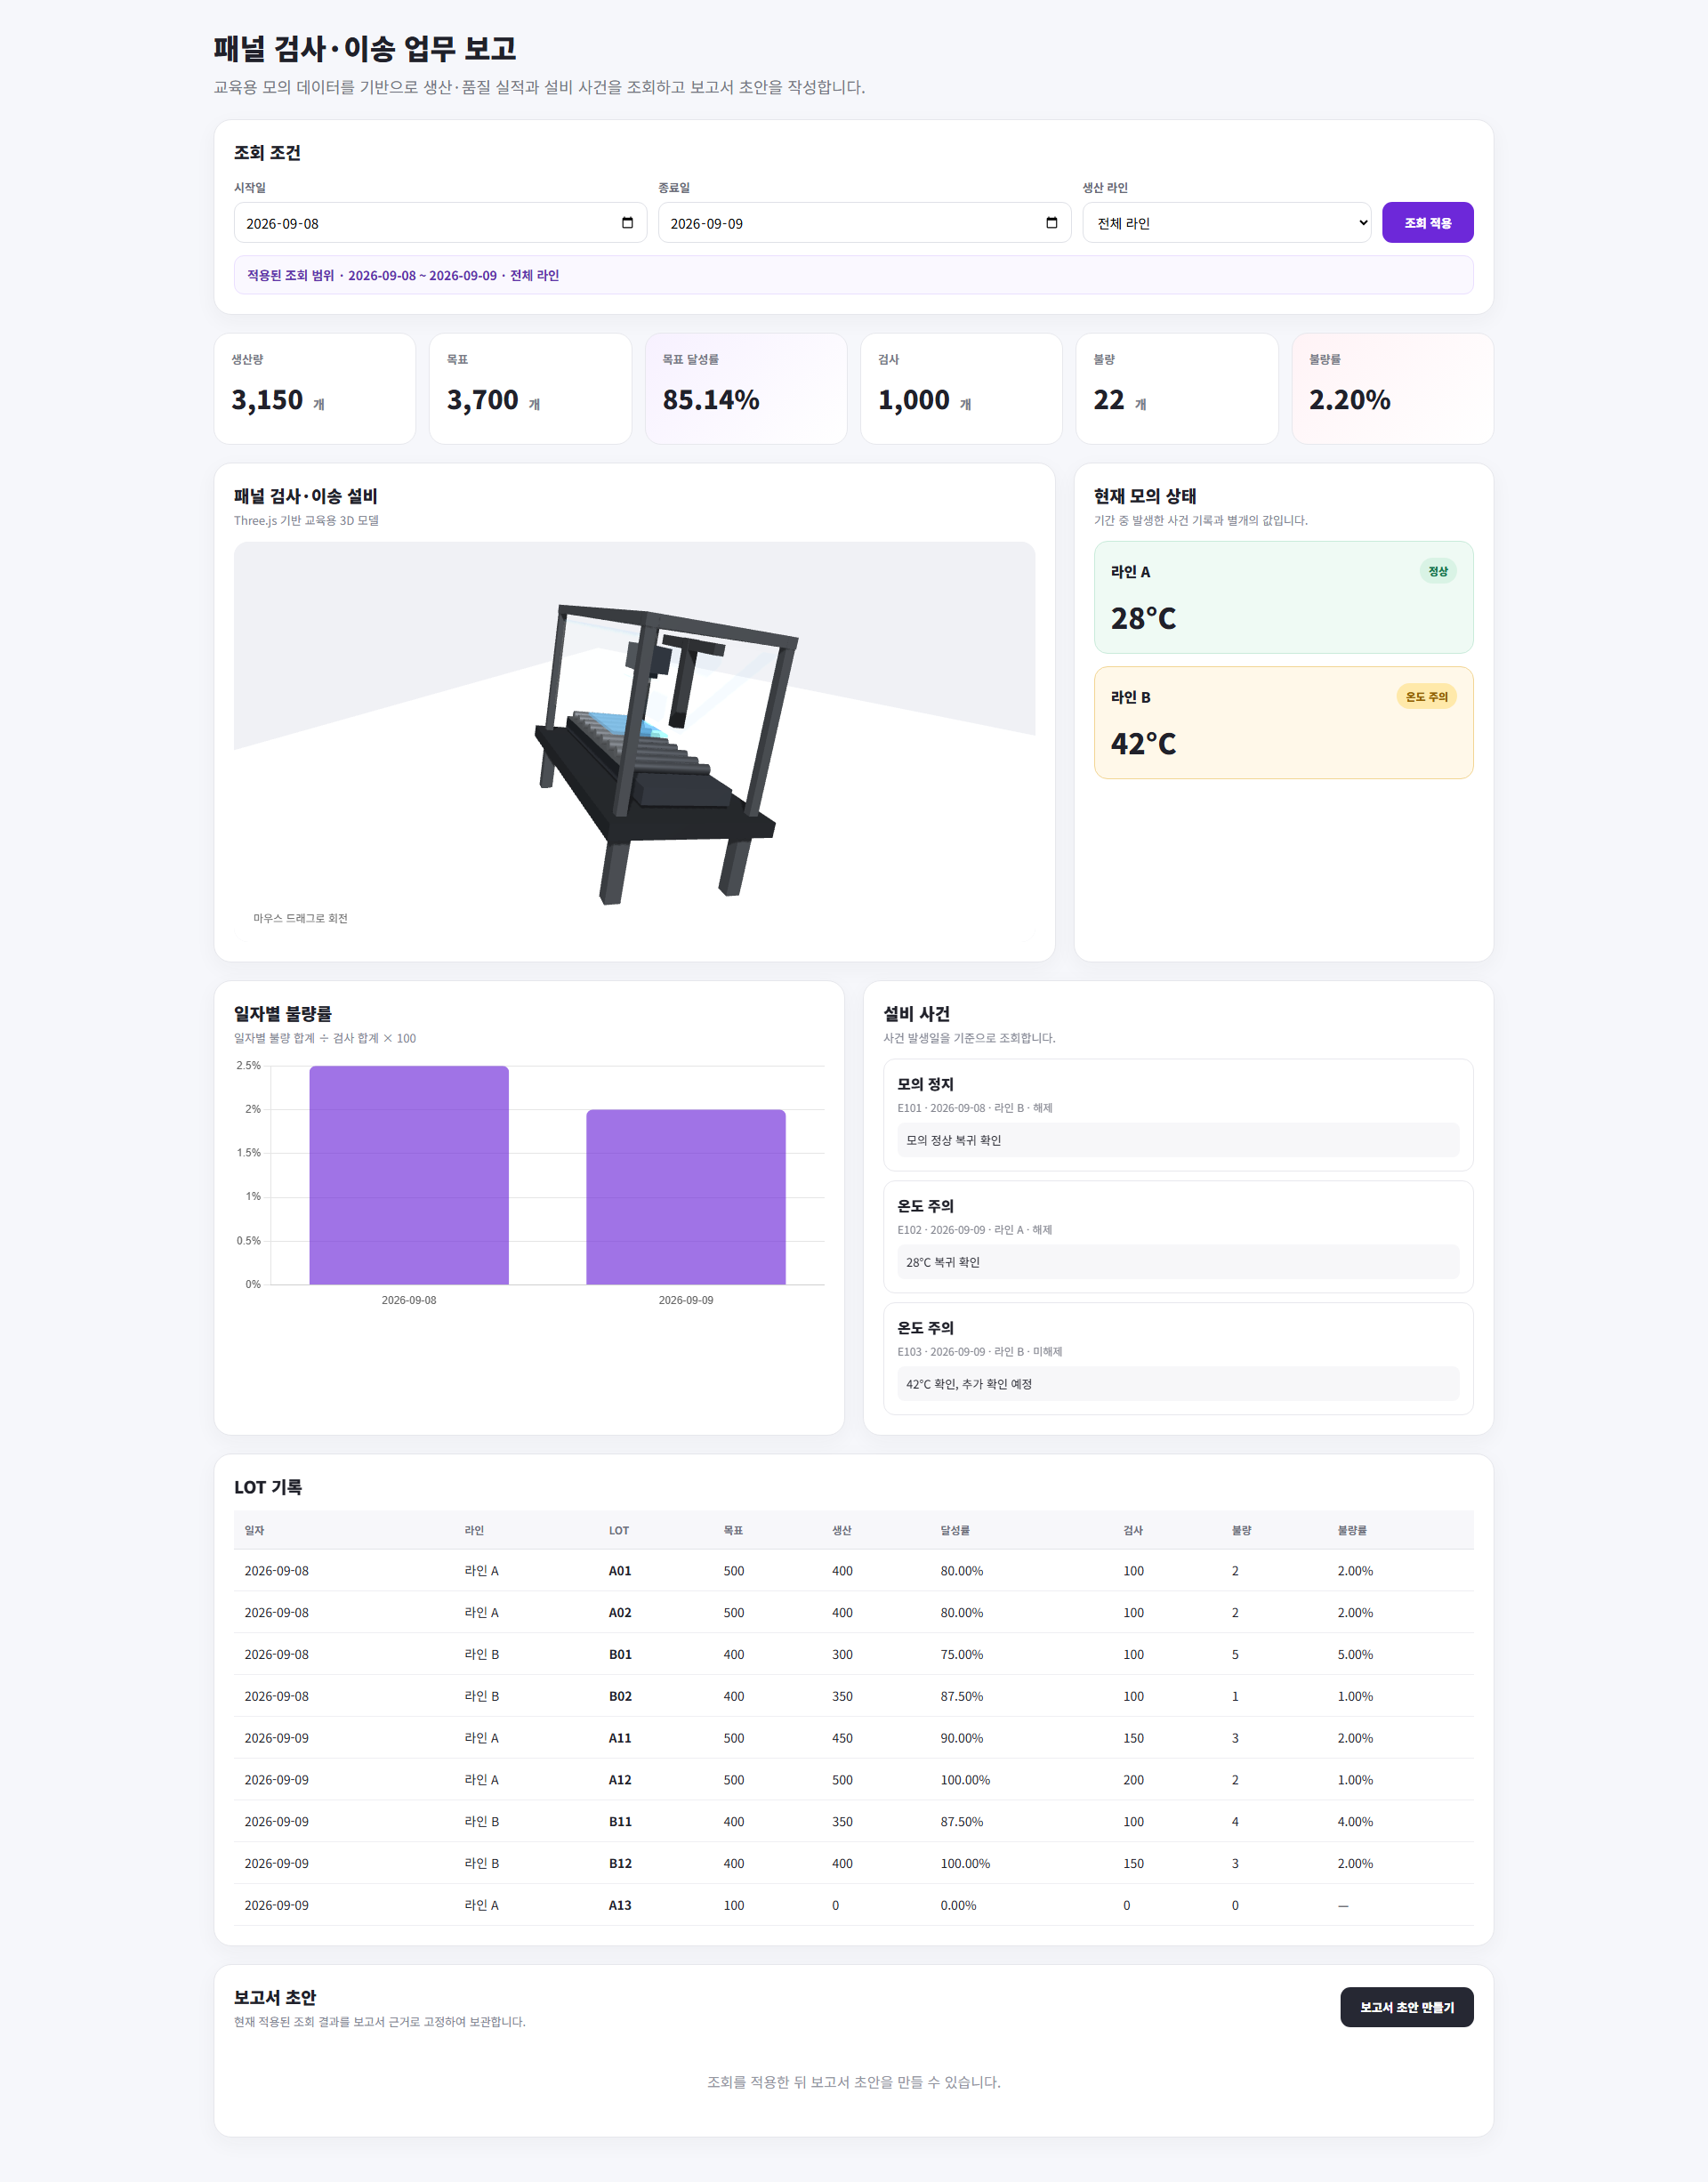

## 3.3 초안과 근거를 연결합니다

### 초안을 만듭니다

9월 9일 전체를 적용하고 초안을 만듭니다. 첫 생성이라면 R001이 만들어지며 본문에 생산 1,700개와 불량률 2.00%가 표시됩니다.

### 조회 범위를 바꿉니다

상단에서 라인 B를 적용하면 조회 화면은 B의 값으로 바뀝니다. 기존 R001의 본문과 근거는 전체 라인 값으로 유지됩니다.

### 다른 보고서를 만듭니다

B 범위로 새 초안을 만들면 새 번호가 생깁니다. 보관 목록에서 번호와 기간·라인을 확인하여 검토할 보고서를 선택합니다.

## 3.4 보고서 초안을 읽습니다

조회 범위·생산·품질·사건·현재 모의 상태가 분리된 초안입니다.

수치와 사건 번호를 근거 표에 대조한 뒤 본문을 수정합니다.

교안의 화면과 본인 실행 결과를 비교합니다.

**실제 확인한 수치·상태:**

## 3.5 사실·추정·확인을 구분합니다

### 사실

“9월 9일 라인 B의 검사 250개 중 불량은 7개로 불량률은 2.80%입니다.”는 데이터로 확인할 수 있는 문장입니다.

### 추정

“온도 상승 때문에 불량이 발생했습니다.”는 이 데이터만으로 확인되지 않은 원인 설명입니다. 보고서에서는 확정 표현을 피하고 근거가 필요한 추정으로 구분합니다.

### 추가 확인

“불량 발생 시각과 온도 이력을 대조할 필요가 있습니다.”처럼 다음 확인 항목을 적습니다. 실제로 수행하지 않은 조치를 완료했다고 적지 않습니다.

## 3.6 ChatGPT로 보고 문장 개선

초안 본문과 근거를 복사해 아래 요청문과 함께 전달합니다.

```text
다음 교육용 보고서의 문장을 다듬어 주세요.
[현재 보고서 본문과 근거 수치를 붙입니다.]
기간·라인·수량·비율·사건 번호는 그대로 유지하세요. 사실, 확인되지 않은 원인, 추가 확인 항목을 구분하세요. 담당자나 완료 시각을 지어내지 마세요.
생산·품질 현황, 설비 사건, 추가 확인 순서로 간결한 업무 보고문을 작성하세요. 수정 후 원문과 대조할 항목도 알려 주세요.
```

문장 개선 결과는 웹 보고서 본문 칸에 붙입니다. 코드 생성 답변과 구분합니다.

In [ ]:
# ============================================================
# LG Display 교육용 패널 검사·이송 업무 보고 웹 서비스
# Google Colab 한 셀 실행용 전체 코드
#
# 기능
# - 기간 / 라인 조회
# - 생산 / 목표 / 검사 / 불량 합계
# - 합계 기준 달성률 / 불량률
# - 분모 0이면 —
# - LOT 기록
# - 일자별 불량률
# - 발생일 기준 설비 사건
# - 현재 모의 상태
# - Three.js 검사·이송 설비
# - 보고서 초안 생성
# - 보고서 생성 시 Snapshot 고정
# - 사실 / 확인되지 않은 원인 / 추가 확인 분리
# - Flask
# - Cloudflared 외부 접속
# ============================================================

import os
import json
import time
import re
import subprocess
import threading


# ============================================================
# 1. Flask 설치
# ============================================================

subprocess.run(
    ["pip", "install", "-q", "flask"],
    check=False
)


# ============================================================
# 2. Cloudflared 설치
# ============================================================

CLOUDFLARED = "/usr/local/bin/cloudflared"

if not os.path.exists(CLOUDFLARED):
    subprocess.run(
        [
            "wget",
            "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O",
            CLOUDFLARED
        ],
        check=True
    )

    subprocess.run(
        ["chmod", "+x", CLOUDFLARED],
        check=True
    )


# ============================================================
# 3. Flask
# ============================================================

from flask import Flask, render_template_string, jsonify

app = Flask(__name__)


# ============================================================
# 4. 교육용 샘플 데이터
# ============================================================

DATA = {
    "rows": [
        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A01",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },
        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A02",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },
        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B01",
            "target": 400,
            "produced": 300,
            "inspected": 100,
            "defects": 5
        },
        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B02",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 1
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A11",
            "target": 500,
            "produced": 450,
            "inspected": 150,
            "defects": 3
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A12",
            "target": 500,
            "produced": 500,
            "inspected": 200,
            "defects": 2
        },
        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B11",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 4
        },
        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B12",
            "target": 400,
            "produced": 400,
            "inspected": 150,
            "defects": 3
        },
        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A13",
            "target": 100,
            "produced": 0,
            "inspected": 0,
            "defects": 0
        }
    ],

    "events": [
        {
            "id": "E101",
            "date": "2026-09-08",
            "line": "B",
            "title": "모의 정지",
            "resolved": True,
            "note": "모의 정상 복귀 확인"
        },
        {
            "id": "E102",
            "date": "2026-09-09",
            "line": "A",
            "title": "온도 주의",
            "resolved": True,
            "note": "28°C 복귀 확인"
        },
        {
            "id": "E103",
            "date": "2026-09-09",
            "line": "B",
            "title": "온도 주의",
            "resolved": False,
            "note": "42°C 확인, 추가 확인 예정"
        }
    ]
}


# ============================================================
# 5. HTML / CSS / JavaScript
# ============================================================

HTML = r'''
<!DOCTYPE html>
<html lang="ko">

<head>

<meta charset="UTF-8">

<meta
    name="viewport"
    content="width=device-width, initial-scale=1.0"
>

<title>패널 검사·이송 업무 보고</title>

<script src="https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/chart.js"></script>

<style>

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    background: #f5f6fa;
    color: #181b25;

    font-family:
        Pretendard,
        "Noto Sans KR",
        Arial,
        sans-serif;
}

button,
input,
select {
    font-family: inherit;
}

.page {
    width: min(1500px, calc(100% - 30px));
    margin: auto;
    padding: 30px 0 50px;
}


/* =========================================================
   HEADER
========================================================= */

.header {
    margin-bottom: 24px;
}

.header h1 {
    margin: 0;
    font-size: 32px;
    font-weight: 900;
    letter-spacing: -1px;
}

.header p {
    margin: 8px 0 0;
    color: #747887;
    font-size: 18px;
    line-height: 1.6;
}


/* =========================================================
   CARD
========================================================= */

.card {
    background: #ffffff;
    border: 1px solid #e3e5eb;
    border-radius: 20px;
    padding: 22px;

    box-shadow:
        0 7px 25px
        rgba(30, 35, 60, 0.045);
}

.section-title {
    font-size: 19px;
    font-weight: 900;
}

.section-desc {
    margin-top: 5px;
    color: #818593;
    font-size: 13px;
    line-height: 1.6;
}


/* =========================================================
   SEARCH
========================================================= */

.search-card {
    margin-bottom: 20px;
}

.filters {
    display: grid;

    grid-template-columns:
        minmax(160px, 1fr)
        minmax(160px, 1fr)
        minmax(150px, 0.7fr)
        auto;

    gap: 12px;
    align-items: end;

    margin-top: 18px;
}

.field label {
    display: block;
    margin-bottom: 7px;

    color: #676b78;
    font-size: 13px;
    font-weight: 800;
}

.field input,
.field select {
    width: 100%;
    height: 46px;

    padding: 0 12px;

    background: white;

    border: 1px solid #dcdfe6;
    border-radius: 11px;

    color: #242733;
    font-size: 14px;
}

.field input:focus,
.field select:focus {
    outline: none;
    border-color: #6d28d9;

    box-shadow:
        0 0 0 3px
        rgba(109, 40, 217, 0.08);
}

.primary-btn {
    height: 46px;

    padding: 0 27px;

    border: 0;
    border-radius: 11px;

    background: #6d28d9;
    color: white;

    font-weight: 900;
    cursor: pointer;
}

.primary-btn:hover {
    background: #5b21b6;
}

.scope {
    margin-top: 14px;

    padding: 11px 14px;

    background: #faf8ff;

    border: 1px solid #e8ddff;
    border-radius: 10px;

    color: #6034aa;

    font-size: 14px;
    font-weight: 800;
}


/* =========================================================
   KPI
========================================================= */

.kpi-grid {
    display: grid;
    grid-template-columns: repeat(6, 1fr);

    gap: 14px;
    margin-bottom: 20px;
}

.kpi {
    min-height: 120px;

    padding: 18px;

    background: white;

    border: 1px solid #e5e7ec;
    border-radius: 17px;
}

.kpi-label {
    color: #777b89;
    font-size: 13px;
    font-weight: 800;
}

.kpi-value {
    margin-top: 14px;

    font-size: 29px;
    font-weight: 900;

    letter-spacing: -0.6px;
}

.kpi-unit {
    margin-left: 3px;

    font-size: 14px;
    color: #777b87;
}

.purple {
    background:
        linear-gradient(
            135deg,
            #f8f3ff,
            white
        );
}

.red {
    background:
        linear-gradient(
            135deg,
            #fff3f5,
            white
        );
}


/* =========================================================
   3D + STATUS
========================================================= */

.main-grid {
    display: grid;

    grid-template-columns:
        minmax(0, 1.35fr)
        minmax(340px, 0.65fr);

    gap: 20px;

    margin-bottom: 20px;
}

#three-container {
    position: relative;

    width: 100%;
    height: 455px;

    margin-top: 15px;

    border-radius: 16px;
    overflow: hidden;

    background:
        linear-gradient(
            #f1f2f6,
            #e8eaf0
        );
}

.three-help {
    position: absolute;

    z-index: 5;

    left: 13px;
    bottom: 13px;

    padding: 7px 10px;

    background:
        rgba(255, 255, 255, 0.92);

    border-radius: 8px;

    color: #636774;

    font-size: 12px;
}

.status {
    margin-top: 14px;

    padding: 18px;

    border-radius: 15px;
}

.status-normal {
    background: #eefaf4;
    border: 1px solid #c9edda;
}

.status-warning {
    background: #fff8e9;
    border: 1px solid #f4d89d;
}

.status-top {
    display: flex;

    align-items: center;
    justify-content: space-between;
}

.status-line {
    font-weight: 900;
}

.badge {
    padding: 6px 10px;

    border-radius: 999px;

    font-size: 12px;
    font-weight: 900;
}

.badge-normal {
    background: #d7f3e4;
    color: #16734b;
}

.badge-warning {
    background: #ffe9aa;
    color: #956200;
}

.temp {
    margin-top: 15px;

    font-size: 32px;
    font-weight: 900;
}

.status-info {
    margin-top: 15px;

    padding: 13px;

    background: #f6f7fa;

    border-radius: 11px;

    color: #6c707e;

    font-size: 13px;
    line-height: 1.7;
}


/* =========================================================
   CHART / EVENT
========================================================= */

.two-grid {
    display: grid;

    grid-template-columns:
        minmax(0, 1fr)
        minmax(0, 1fr);

    gap: 20px;

    margin-bottom: 20px;
}

.chart-area {
    height: 280px;
    margin-top: 15px;
}

.event-list {
    display: flex;
    flex-direction: column;

    gap: 10px;

    margin-top: 14px;
}

.event {
    padding: 15px;

    border: 1px solid #e7e8ed;
    border-radius: 13px;
}

.event-top {
    display: flex;

    align-items: center;
    justify-content: space-between;

    gap: 10px;
}

.event-title {
    font-weight: 900;
}

.event-status {
    padding: 5px 9px;

    border-radius: 999px;

    font-size: 11px;
    font-weight: 900;
}

.event-resolved {
    background: #e4f7ed;
    color: #187149;
}

.event-open {
    background: #fff0c8;
    color: #956200;
}

.event-meta {
    margin-top: 6px;

    color: #7d818e;
    font-size: 12px;
}

.event-note {
    margin-top: 9px;

    padding: 9px 10px;

    background: #f7f7fa;

    border-radius: 8px;

    font-size: 13px;
}


/* =========================================================
   TABLE
========================================================= */

.table-card {
    margin-bottom: 20px;
}

.table-scroll {
    margin-top: 15px;
    overflow-x: auto;
}

table {
    width: 100%;
    min-width: 800px;

    border-collapse: collapse;
}

th,
td {
    padding: 13px 12px;

    text-align: left;
    white-space: nowrap;
}

th {
    background: #f7f7fa;

    border-bottom: 1px solid #e3e4e9;

    color: #6f7280;

    font-size: 12px;
    font-weight: 900;
}

td {
    border-bottom: 1px solid #eeeef2;
    font-size: 14px;
}

.empty {
    padding: 30px;

    color: #8b8f9c;

    text-align: center;
}


/* =========================================================
   REPORT
========================================================= */

.report-card {
    margin-bottom: 30px;
}

.report-toolbar {
    display: flex;

    justify-content: space-between;
    align-items: center;

    gap: 15px;
}

.report-button {
    padding: 13px 22px;

    border: 0;
    border-radius: 11px;

    background: #20232d;
    color: white;

    font-weight: 900;

    cursor: pointer;
}

.report-button:hover {
    background: #0f1117;
}

#reportContainer {
    margin-top: 18px;
}

.report-paper {
    padding: 28px;

    background: white;

    border: 1px solid #dadee6;
    border-radius: 16px;
}

.report-header {
    padding-bottom: 20px;

    border-bottom: 2px solid #252832;
}

.report-title {
    font-size: 28px;
    font-weight: 900;
}

.draft {
    margin-left: 5px;

    color: #747887;

    font-size: 14px;
}

.report-meta {
    margin-top: 11px;

    color: #697080;

    font-size: 13px;
    line-height: 1.8;
}

.report-section {
    margin-top: 28px;
}

.report-section h3 {
    margin: 0 0 13px;

    font-size: 18px;
}

.report-text {
    margin: 0 0 13px;

    color: #343843;

    font-size: 14px;
    line-height: 1.85;
}

.report-summary {
    display: grid;

    grid-template-columns:
        repeat(3, 1fr);

    gap: 10px;

    margin: 15px 0;
}

.summary-box {
    padding: 14px;

    background: #f7f7fa;

    border-radius: 11px;
}

.summary-label {
    color: #777b88;

    font-size: 12px;
}

.summary-value {
    margin-top: 5px;

    font-size: 20px;
    font-weight: 900;
}

.fact-box,
.unknown-box,
.check-box {
    margin-top: 13px;

    padding: 14px 16px;

    border-radius: 11px;

    font-size: 13px;
    line-height: 1.75;
}

.fact-box {
    background: #eef8f3;

    border: 1px solid #cdebdc;

    color: #275f47;
}

.unknown-box {
    background: #f5f5f7;

    border: 1px solid #e0e1e5;

    color: #575b66;
}

.check-box {
    background: #fff7e6;

    border: 1px solid #f2d69b;

    color: #755518;
}

.report-list {
    margin: 9px 0 0;

    padding-left: 22px;

    line-height: 1.9;
}

.snapshot {
    margin-top: 25px;

    padding: 14px 16px;

    border-radius: 11px;

    background: #edf5ff;

    color: #3b658a;

    font-size: 13px;
    line-height: 1.7;
}


/* =========================================================
   RESPONSIVE
========================================================= */

@media(max-width: 1200px) {
    .kpi-grid {
        grid-template-columns:
            repeat(3, 1fr);
    }
}

@media(max-width: 950px) {
    .main-grid,
    .two-grid {
        grid-template-columns:
            1fr;
    }
}

@media(max-width: 760px) {

    .page {
        width: calc(100% - 24px);
        padding-top: 18px;
    }

    .header h1 {
        font-size: 26px;
    }

    .header p {
        font-size: 15px;
    }

    .filters {
        grid-template-columns:
            1fr;
    }

    .primary-btn {
        width: 100%;
    }

    .kpi-grid {
        grid-template-columns:
            repeat(2, 1fr);
    }

    .report-toolbar {
        flex-direction: column;
        align-items: stretch;
    }

    .report-summary {
        grid-template-columns:
            1fr 1fr;
    }

    #three-container {
        height: 370px;
    }
}

@media(max-width: 480px) {

    .kpi-grid {
        grid-template-columns:
            1fr;
    }

    .report-summary {
        grid-template-columns:
            1fr;
    }
}

</style>

</head>


<body>

<div class="page">


<!-- ======================================================
     HEADER
======================================================= -->

<header class="header">

    <h1>
        패널 검사·이송 업무 보고
    </h1>

    <p>
        교육용 모의 데이터를 기반으로 생산·품질 현황과
        설비 사건을 조회하고 업무 보고 초안을 작성합니다.
    </p>

</header>


<!-- ======================================================
     SEARCH
======================================================= -->

<section class="card search-card">

    <div class="section-title">
        조회 조건
    </div>

    <div class="section-desc">
        기간과 라인을 선택한 뒤 조회 적용을 누르세요.
    </div>


    <div class="filters">

        <div class="field">

            <label>
                시작일
            </label>

            <input
                type="date"
                id="startDate"
                value="2026-09-08"
            >

        </div>


        <div class="field">

            <label>
                종료일
            </label>

            <input
                type="date"
                id="endDate"
                value="2026-09-09"
            >

        </div>


        <div class="field">

            <label>
                생산 라인
            </label>

            <select id="lineSelect">

                <option value="ALL">
                    전체 라인
                </option>

                <option value="A">
                    라인 A
                </option>

                <option value="B">
                    라인 B
                </option>

            </select>

        </div>


        <button
            class="primary-btn"
            onclick="applyFilter()"
        >
            조회 적용
        </button>

    </div>


    <div
        id="scopeText"
        class="scope"
    >
    </div>

</section>


<!-- ======================================================
     KPI
======================================================= -->

<section class="kpi-grid">

    <div class="kpi">

        <div class="kpi-label">
            목표
        </div>

        <div class="kpi-value">

            <span id="targetValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi">

        <div class="kpi-label">
            생산
        </div>

        <div class="kpi-value">

            <span id="producedValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi purple">

        <div class="kpi-label">
            달성률
        </div>

        <div
            id="achievementValue"
            class="kpi-value"
        >
            —
        </div>

    </div>


    <div class="kpi">

        <div class="kpi-label">
            검사
        </div>

        <div class="kpi-value">

            <span id="inspectedValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi">

        <div class="kpi-label">
            불량
        </div>

        <div class="kpi-value">

            <span id="defectValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi red">

        <div class="kpi-label">
            불량률
        </div>

        <div
            id="defectRateValue"
            class="kpi-value"
        >
            —
        </div>

    </div>

</section>


<!-- ======================================================
     THREE + CURRENT STATUS
======================================================= -->

<section class="main-grid">

    <div class="card">

        <div class="section-title">
            패널 검사·이송 설비
        </div>

        <div class="section-desc">
            Three.js 기반 교육용 3D 설비
        </div>


        <div id="three-container">

            <div class="three-help">
                드래그 : 회전 / 휠 : 확대·축소
            </div>

        </div>

    </div>


    <div class="card">

        <div class="section-title">
            현재 모의 상태
        </div>

        <div class="section-desc">
            조회 기간의 설비 사건과 별개의 현재 교육용 상태입니다.
        </div>


        <div class="status status-normal">

            <div class="status-top">

                <div class="status-line">
                    라인 A
                </div>

                <span class="badge badge-normal">
                    정상
                </span>

            </div>

            <div class="temp">
                28°C
            </div>

        </div>


        <div class="status status-warning">

            <div class="status-top">

                <div class="status-line">
                    라인 B
                </div>

                <span class="badge badge-warning">
                    온도 주의
                </span>

            </div>

            <div class="temp">
                42°C
            </div>

        </div>


        <div class="status-info">

            현재 모의 상태는 과거 조회 기간의
            생산·품질 결과 또는 설비 사건의
            원인으로 해석하지 않습니다.

        </div>

    </div>

</section>


<!-- ======================================================
     CHART + EVENTS
======================================================= -->

<section class="two-grid">

    <div class="card">

        <div class="section-title">
            일자별 불량률
        </div>

        <div class="section-desc">
            일자별 불량 수량 합계 ÷ 검사 수량 합계 × 100
        </div>

        <div class="chart-area">

            <canvas id="defectChart"></canvas>

        </div>

    </div>


    <div class="card">

        <div class="section-title">
            기간 중 설비 사건
        </div>

        <div class="section-desc">
            설비 사건의 발생일을 기준으로 조회합니다.
        </div>

        <div
            id="eventList"
            class="event-list"
        >
        </div>

    </div>

</section>


<!-- ======================================================
     LOT
======================================================= -->

<section class="card table-card">

    <div class="section-title">
        LOT 기록
    </div>

    <div class="section-desc">
        현재 적용된 조회 조건의 생산·품질 기록입니다.
    </div>


    <div class="table-scroll">

        <table>

            <thead>

                <tr>

                    <th>일자</th>
                    <th>라인</th>
                    <th>LOT</th>
                    <th>목표</th>
                    <th>생산</th>
                    <th>달성률</th>
                    <th>검사</th>
                    <th>불량</th>
                    <th>불량률</th>

                </tr>

            </thead>

            <tbody id="lotTable">
            </tbody>

        </table>

    </div>

</section>


<!-- ======================================================
     REPORT
======================================================= -->

<section class="card report-card">

    <div class="report-toolbar">

        <div>

            <div class="section-title">
                보고서 초안
            </div>

            <div class="section-desc">
                현재 적용된 조회 결과를 근거 데이터로 고정하여
                생산·품질 현황 → 설비 사건 → 추가 확인 순서로 작성합니다.
            </div>

        </div>


        <button
            class="report-button"
            onclick="createReport()"
        >
            보고서 초안 만들기
        </button>

    </div>


    <div id="reportContainer">

        <div class="empty">

            조회 결과를 확인한 뒤
            보고서 초안을 만들어 주세요.

        </div>

    </div>

</section>


</div>


<script>

/* =========================================================
   DATA
========================================================= */

const rawData = {{ data_json | safe }};

const rows = rawData.rows;
const events = rawData.events;


/* =========================================================
   APPLIED QUERY
========================================================= */

let appliedQuery = null;
let appliedRows = [];
let appliedEvents = [];
let appliedSummary = null;


/* =========================================================
   REPORT STORAGE
========================================================= */

const reports = [];
let reportSequence = 1;


/* =========================================================
   UTIL
========================================================= */

function numberFormat(value) {

    return Number(value)
        .toLocaleString("ko-KR");

}


function rate(
    numerator,
    denominator
) {

    if (
        denominator === 0 ||
        !denominator
    ) {
        return null;
    }

    return (
        numerator /
        denominator *
        100
    );

}


function displayRate(value) {

    if (
        value === null ||
        !Number.isFinite(value)
    ) {
        return "—";
    }

    return (
        value.toFixed(2) +
        "%"
    );

}


function deepCopy(value) {

    return JSON.parse(
        JSON.stringify(value)
    );

}


function escapeHTML(value) {

    return String(value)
        .replaceAll("&", "&amp;")
        .replaceAll("<", "&lt;")
        .replaceAll(">", "&gt;")
        .replaceAll('"', "&quot;")
        .replaceAll("'", "&#039;");

}


function getLineText(line) {

    if (line === "ALL") {
        return "전체 라인";
    }

    return "라인 " + line;

}


/* =========================================================
   SUMMARY
========================================================= */

function calculateSummary(data) {

    const result = {
        target: 0,
        produced: 0,
        inspected: 0,
        defects: 0,
        achievementRate: null,
        defectRate: null
    };


    data.forEach(row => {

        result.target += row.target;
        result.produced += row.produced;
        result.inspected += row.inspected;
        result.defects += row.defects;

    });


    result.achievementRate =
        rate(
            result.produced,
            result.target
        );


    result.defectRate =
        rate(
            result.defects,
            result.inspected
        );


    return result;

}


/* =========================================================
   FILTER
========================================================= */

function applyFilter() {

    const start =
        document.getElementById(
            "startDate"
        ).value;


    const end =
        document.getElementById(
            "endDate"
        ).value;


    const line =
        document.getElementById(
            "lineSelect"
        ).value;


    if (!start || !end) {

        alert(
            "시작일과 종료일을 선택해 주세요."
        );

        return;

    }


    if (start > end) {

        alert(
            "시작일은 종료일보다 늦을 수 없습니다."
        );

        return;

    }


    const filteredRows =
        rows.filter(row => {

            const dateOK =
                row.date >= start &&
                row.date <= end;

            const lineOK =
                line === "ALL" ||
                row.line === line;

            return dateOK && lineOK;

        });


    const filteredEvents =
        events.filter(event => {

            const dateOK =
                event.date >= start &&
                event.date <= end;

            const lineOK =
                line === "ALL" ||
                event.line === line;

            return dateOK && lineOK;

        });


    appliedQuery = {
        start: start,
        end: end,
        line: line
    };


    appliedRows =
        deepCopy(filteredRows);


    appliedEvents =
        deepCopy(filteredEvents);


    appliedSummary =
        calculateSummary(
            appliedRows
        );


    renderScope();
    renderKPI();
    renderLots();
    renderEvents();
    renderChart();

}


/* =========================================================
   SCOPE
========================================================= */

function renderScope() {

    document.getElementById(
        "scopeText"
    ).textContent =
        "적용된 조회 범위 · " +
        appliedQuery.start +
        " ~ " +
        appliedQuery.end +
        " · " +
        getLineText(
            appliedQuery.line
        );

}


/* =========================================================
   KPI
========================================================= */

function renderKPI() {

    const s =
        appliedSummary;


    document.getElementById(
        "targetValue"
    ).textContent =
        numberFormat(s.target);


    document.getElementById(
        "producedValue"
    ).textContent =
        numberFormat(s.produced);


    document.getElementById(
        "inspectedValue"
    ).textContent =
        numberFormat(s.inspected);


    document.getElementById(
        "defectValue"
    ).textContent =
        numberFormat(s.defects);


    document.getElementById(
        "achievementValue"
    ).textContent =
        displayRate(
            s.achievementRate
        );


    document.getElementById(
        "defectRateValue"
    ).textContent =
        displayRate(
            s.defectRate
        );

}


/* =========================================================
   LOT
========================================================= */

function renderLots() {

    const tbody =
        document.getElementById(
            "lotTable"
        );


    tbody.innerHTML = "";


    if (appliedRows.length === 0) {

        tbody.innerHTML = `

            <tr>

                <td colspan="9">

                    <div class="empty">
                        조회 결과가 없습니다.
                    </div>

                </td>

            </tr>

        `;

        return;

    }


    appliedRows.forEach(row => {

        const achievement =
            rate(
                row.produced,
                row.target
            );


        const defectRate =
            rate(
                row.defects,
                row.inspected
            );


        const tr =
            document.createElement(
                "tr"
            );


        tr.innerHTML = `

            <td>
                ${escapeHTML(row.date)}
            </td>

            <td>
                라인 ${escapeHTML(row.line)}
            </td>

            <td>
                <strong>
                    ${escapeHTML(row.lot)}
                </strong>
            </td>

            <td>
                ${numberFormat(row.target)}
            </td>

            <td>
                ${numberFormat(row.produced)}
            </td>

            <td>
                ${displayRate(achievement)}
            </td>

            <td>
                ${numberFormat(row.inspected)}
            </td>

            <td>
                ${numberFormat(row.defects)}
            </td>

            <td>
                ${displayRate(defectRate)}
            </td>

        `;


        tbody.appendChild(tr);

    });

}


/* =========================================================
   EVENTS
========================================================= */

function renderEvents() {

    const container =
        document.getElementById(
            "eventList"
        );


    container.innerHTML = "";


    if (appliedEvents.length === 0) {

        container.innerHTML = `

            <div class="empty">

                조회 기간에 발생한
                설비 사건이 없습니다.

            </div>

        `;

        return;

    }


    const sorted =
        appliedEvents
        .slice()
        .sort(
            (a, b) =>
                a.date.localeCompare(
                    b.date
                )
        );


    sorted.forEach(event => {

        const div =
            document.createElement(
                "div"
            );


        div.className =
            "event";


        const statusClass =
            event.resolved
            ? "event-resolved"
            : "event-open";


        const statusText =
            event.resolved
            ? "해제"
            : "미해제";


        div.innerHTML = `

            <div class="event-top">

                <div class="event-title">

                    ${escapeHTML(
                        event.title
                    )}

                </div>

                <span
                    class="event-status ${statusClass}"
                >

                    ${statusText}

                </span>

            </div>


            <div class="event-meta">

                ${escapeHTML(event.id)}

                ·

                ${escapeHTML(event.date)}

                ·

                라인 ${escapeHTML(event.line)}

            </div>


            <div class="event-note">

                ${escapeHTML(event.note)}

            </div>

        `;


        container.appendChild(div);

    });

}


/* =========================================================
   DAILY CHART
========================================================= */

let chart = null;


function renderChart() {

    const daily = {};


    appliedRows.forEach(row => {

        if (!daily[row.date]) {

            daily[row.date] = {
                inspected: 0,
                defects: 0
            };

        }


        daily[row.date].inspected +=
            row.inspected;


        daily[row.date].defects +=
            row.defects;

    });


    const dates =
        Object.keys(daily)
        .sort();


    const values =
        dates.map(date => {

            const value =
                rate(
                    daily[date].defects,
                    daily[date].inspected
                );


            if (value === null) {
                return null;
            }


            return Number(
                value.toFixed(2)
            );

        });


    if (chart) {
        chart.destroy();
    }


    const ctx =
        document
        .getElementById(
            "defectChart"
        )
        .getContext("2d");


    chart =
        new Chart(
            ctx,
            {
                type: "bar",

                data: {
                    labels: dates,

                    datasets: [
                        {
                            label: "불량률 (%)",
                            data: values,

                            backgroundColor:
                                "rgba(109, 40, 217, 0.68)",

                            borderRadius: 7
                        }
                    ]
                },

                options: {
                    responsive: true,
                    maintainAspectRatio: false,

                    plugins: {
                        legend: {
                            display: false
                        },

                        tooltip: {
                            callbacks: {
                                label: function(context) {

                                    if (
                                        context.raw === null
                                    ) {
                                        return "불량률: —";
                                    }

                                    return (
                                        "불량률: " +
                                        context.raw +
                                        "%"
                                    );
                                }
                            }
                        }
                    },

                    scales: {
                        y: {
                            beginAtZero: true,

                            ticks: {
                                callback:
                                    value =>
                                    value + "%"
                            }
                        },

                        x: {
                            grid: {
                                display: false
                            }
                        }
                    }
                }
            }
        );

}


/* =========================================================
   REPORT NUMBER
========================================================= */

function createReportNumber() {

    const now =
        new Date();


    const yyyy =
        now.getFullYear();


    const mm =
        String(
            now.getMonth() + 1
        ).padStart(
            2,
            "0"
        );


    const dd =
        String(
            now.getDate()
        ).padStart(
            2,
            "0"
        );


    const seq =
        String(
            reportSequence
        ).padStart(
            3,
            "0"
        );


    reportSequence++;


    return (
        `RPT-${yyyy}${mm}${dd}-${seq}`
    );

}


/* =========================================================
   CURRENT MOCK STATUS
========================================================= */

function getCurrentStatus() {

    return [
        {
            line: "A",
            status: "정상",
            temperature: "28°C"
        },
        {
            line: "B",
            status: "온도 주의",
            temperature: "42°C"
        }
    ];

}


/* =========================================================
   CREATE REPORT
========================================================= */

function createReport() {

    if (!appliedQuery) {

        alert(
            "먼저 조회 조건을 적용해 주세요."
        );

        return;

    }


    if (appliedRows.length === 0) {

        alert(
            "조회된 LOT 기록이 없어 보고서 초안을 만들 수 없습니다."
        );

        return;

    }


    /*
       중요:
       보고서 생성 순간의 조회 결과를
       완전히 복사하여 Snapshot으로 저장한다.
    */

    const report = {

        number:
            createReportNumber(),

        createdAt:
            new Date()
            .toLocaleString(
                "ko-KR"
            ),

        evidence: {

            query:
                deepCopy(
                    appliedQuery
                ),

            rows:
                deepCopy(
                    appliedRows
                ),

            events:
                deepCopy(
                    appliedEvents
                ),

            summary:
                deepCopy(
                    appliedSummary
                )

        },

        mockStatus:
            deepCopy(
                getCurrentStatus()
            )

    };


    reports.unshift(report);


    renderReport(report);

}


/* =========================================================
   REPORT DISPLAY
========================================================= */

function renderReport(report) {

    const container =
        document.getElementById(
            "reportContainer"
        );


    const q =
        report.evidence.query;


    const s =
        report.evidence.summary;


    const reportRows =
        report.evidence.rows;


    const reportEvents =
        report.evidence.events;


    const lineText =
        getLineText(q.line);


    const unresolvedEvents =
        reportEvents.filter(
            event =>
                event.resolved === false
        );


    /* -----------------------------------------------------
       사건 목록
    ----------------------------------------------------- */

    let eventHTML = "";


    if (reportEvents.length === 0) {

        eventHTML = `

            <p class="report-text">

                조회 기간의 발생일 기준
                설비 사건 기록은 없습니다.

            </p>

        `;

    } else {

        eventHTML = `

            <ul class="report-list">

                ${
                    reportEvents
                    .map(event => `

                        <li>

                            <strong>
                                ${escapeHTML(event.id)}
                            </strong>

                            —
                            ${escapeHTML(event.date)}

                            / 라인
                            ${escapeHTML(event.line)}

                            /
                            ${escapeHTML(event.title)}

                            /
                            ${
                                event.resolved
                                ? "해제"
                                : "미해제"
                            }

                            /
                            ${escapeHTML(event.note)}

                        </li>

                    `)
                    .join("")
                }

            </ul>

        `;

    }


    /* -----------------------------------------------------
       추가 확인
    ----------------------------------------------------- */

    let followUpHTML = "";


    if (unresolvedEvents.length > 0) {

        followUpHTML = `

            <ul class="report-list">

                ${
                    unresolvedEvents
                    .map(event => `

                        <li>

                            <strong>
                                ${escapeHTML(event.id)}
                            </strong>

                            의 현재 상태 변화 여부와
                            후속 기록 존재 여부를
                            추가 확인합니다.

                        </li>

                    `)
                    .join("")
                }

            </ul>

            <div style="margin-top:8px;">

                현재 제공된 자료만으로
                해당 사건의 원인, 담당자,
                조치 방법 또는 완료 예정 시각을
                판단할 수 없습니다.

            </div>

        `;

    } else {

        followUpHTML = `

            <div>

                현재 조회 기록에서
                별도로 확인할 미해제 사건은 없습니다.

            </div>

        `;

    }


    /* -----------------------------------------------------
       현재 모의 상태
    ----------------------------------------------------- */

    const currentStatusHTML =
        report.mockStatus
        .map(status => `

            <li>

                라인
                ${escapeHTML(status.line)}

                :

                ${escapeHTML(status.status)}

                /

                ${escapeHTML(status.temperature)}

            </li>

        `)
        .join("");


    /* -----------------------------------------------------
       REPORT HTML
    ----------------------------------------------------- */

    container.innerHTML = `

        <article class="report-paper">


            <div class="report-header">

                <div class="report-title">

                    패널 검사·이송 업무 보고서

                    <span class="draft">
                        초안
                    </span>

                </div>


                <div class="report-meta">

                    보고서 번호 :

                    <strong>
                        ${escapeHTML(report.number)}
                    </strong>

                    <br>

                    생성 시각 :
                    ${escapeHTML(report.createdAt)}

                    <br>

                    조회 기간 :
                    ${escapeHTML(q.start)}
                    ~
                    ${escapeHTML(q.end)}

                    <br>

                    조회 라인 :
                    ${escapeHTML(lineText)}

                </div>

            </div>


            <!-- ==========================================
                 1. 생산 품질 현황
            =========================================== -->

            <section class="report-section">

                <h3>
                    1. 생산·품질 현황
                </h3>


                <p class="report-text">

                    ${escapeHTML(q.start)}
                    부터
                    ${escapeHTML(q.end)}
                    까지

                    ${escapeHTML(lineText)}

                    의 생산·품질 기록을 조회했습니다.

                </p>


                <div class="report-summary">


                    <div class="summary-box">

                        <div class="summary-label">
                            목표
                        </div>

                        <div class="summary-value">

                            ${numberFormat(s.target)}개

                        </div>

                    </div>


                    <div class="summary-box">

                        <div class="summary-label">
                            생산
                        </div>

                        <div class="summary-value">

                            ${numberFormat(s.produced)}개

                        </div>

                    </div>


                    <div class="summary-box">

                        <div class="summary-label">
                            달성률
                        </div>

                        <div class="summary-value">

                            ${displayRate(
                                s.achievementRate
                            )}

                        </div>

                    </div>


                    <div class="summary-box">

                        <div class="summary-label">
                            검사
                        </div>

                        <div class="summary-value">

                            ${numberFormat(s.inspected)}개

                        </div>

                    </div>


                    <div class="summary-box">

                        <div class="summary-label">
                            불량
                        </div>

                        <div class="summary-value">

                            ${numberFormat(s.defects)}개

                        </div>

                    </div>


                    <div class="summary-box">

                        <div class="summary-label">
                            불량률
                        </div>

                        <div class="summary-value">

                            ${displayRate(
                                s.defectRate
                            )}

                        </div>

                    </div>

                </div>


                <p class="report-text">

                    목표 수량은

                    <strong>
                        ${numberFormat(s.target)}개
                    </strong>,

                    생산 수량은

                    <strong>
                        ${numberFormat(s.produced)}개
                    </strong>

                    이며,

                    합계 기준 목표 달성률은

                    <strong>
                        ${displayRate(
                            s.achievementRate
                        )}
                    </strong>

                    입니다.

                    검사 수량은

                    <strong>
                        ${numberFormat(s.inspected)}개
                    </strong>,

                    불량 수량은

                    <strong>
                        ${numberFormat(s.defects)}개
                    </strong>

                    이며,

                    합계 기준 불량률은

                    <strong>
                        ${displayRate(
                            s.defectRate
                        )}
                    </strong>

                    입니다.

                </p>


                <p class="report-text">

                    조회 조건에 포함된
                    LOT 기록은 총

                    <strong>
                        ${reportRows.length}건
                    </strong>

                    입니다.

                    목표 달성률은
                    생산 수량 합계를 목표 수량 합계로 나누고,

                    불량률은
                    불량 수량 합계를 검사 수량 합계로 나누어
                    계산했습니다.

                    분모가 0인 경우
                    비율은 —로 표시합니다.

                </p>


                <div class="fact-box">

                    <strong>
                        확인된 사실
                    </strong>

                    <br>

                    위 기간·라인·수량·비율과 LOT 건수는
                    생성 시점의 조회 결과를 기준으로 작성했습니다.

                </div>


                <div class="unknown-box">

                    <strong>
                        확인되지 않은 사항
                    </strong>

                    <br>

                    현재 기록만으로 생산 실적 또는
                    불량 발생의 원인은 확인할 수 없습니다.

                    원인, 담당자 및 조치 완료 시각은
                    임의로 작성하지 않습니다.

                </div>

            </section>


            <!-- ==========================================
                 2. 설비 사건
            =========================================== -->

            <section class="report-section">

                <h3>
                    2. 설비 사건
                </h3>


                <p class="report-text">

                    조회 기간의 발생일을 기준으로
                    총

                    <strong>
                        ${reportEvents.length}건
                    </strong>

                    의 설비 사건이 확인되었습니다.

                </p>


                ${eventHTML}


                <div class="fact-box">

                    <strong>
                        확인된 사실
                    </strong>

                    <br>

                    사건 번호, 발생일, 라인,
                    사건명, 해제 여부 및 메모는
                    저장된 사건 기록을 그대로 반영했습니다.

                </div>


                <div class="unknown-box">

                    <strong>
                        확인되지 않은 원인
                    </strong>

                    <br>

                    각 사건이 발생한 원인은
                    현재 제공된 기록만으로 확인되지 않습니다.

                    담당자와 조치 완료 시각 역시
                    제공된 자료가 없으므로 기재하지 않습니다.

                </div>

            </section>


            <!-- ==========================================
                 3. 추가 확인
            =========================================== -->

            <section class="report-section">

                <h3>
                    3. 추가 확인
                </h3>


                <p class="report-text">

                    현재 모의 상태는
                    위 조회 기간의 설비 사건 기록과
                    구분하여 확인합니다.

                </p>


                <ul class="report-list">

                    ${currentStatusHTML}

                </ul>


                <div class="check-box">

                    <strong>
                        추가 확인 항목
                    </strong>

                    ${followUpHTML}

                </div>


                <div class="unknown-box">

                    현재 모의 상태는
                    과거 조회 기간의 생산·품질 결과나
                    설비 사건의 원인으로 해석하지 않습니다.

                </div>

            </section>


            <!-- ==========================================
                 SNAPSHOT
            =========================================== -->

            <div class="snapshot">

                이 보고서는 생성 시점의 조회 결과를
                근거 데이터로 고정한 Snapshot입니다.

                이후 조회 기간 또는 라인을 변경해도
                이 보고서의 기간·라인·LOT 기록·합계·비율·
                설비 사건은 변경되지 않습니다.

            </div>

        </article>

    `;

}


/* =========================================================
   THREE.JS
========================================================= */

let scene = null;
let camera = null;
let renderer = null;
let equipment = null;

let targetRotationX = -0.22;
let targetRotationY = -0.55;

let dragging = false;
let oldMouseX = 0;
let oldMouseY = 0;


/* =========================================================
   THREE INIT
========================================================= */

function initThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    scene =
        new THREE.Scene();


    scene.background =
        new THREE.Color(
            0xf0f1f5
        );


    camera =
        new THREE.PerspectiveCamera(
            44,
            container.clientWidth /
            container.clientHeight,
            0.1,
            1000
        );


    camera.position.set(
        7.5,
        5.5,
        9.5
    );


    camera.lookAt(
        0,
        0.3,
        0
    );


    renderer =
        new THREE.WebGLRenderer({
            antialias: true
        });


    renderer.setPixelRatio(
        Math.min(
            window.devicePixelRatio,
            2
        )
    );


    renderer.setSize(
        container.clientWidth,
        container.clientHeight
    );


    renderer.shadowMap.enabled =
        true;


    renderer.shadowMap.type =
        THREE.PCFSoftShadowMap;


    container.appendChild(
        renderer.domElement
    );


    /* Lighting */

    const hemi =
        new THREE.HemisphereLight(
            0xffffff,
            0x848892,
            1.45
        );


    scene.add(hemi);


    const key =
        new THREE.DirectionalLight(
            0xffffff,
            1.55
        );


    key.position.set(
        6,
        10,
        8
    );


    key.castShadow =
        true;


    scene.add(key);


    const fill =
        new THREE.DirectionalLight(
            0xaacbff,
            0.55
        );


    fill.position.set(
        -7,
        5,
        -4
    );


    scene.add(fill);


    createEquipment();

    createFloor();

    setupMouse();

    setupZoom();


    window.addEventListener(
        "resize",
        resizeThree
    );


    animate();

}


/* =========================================================
   BOX CREATOR
========================================================= */

function makeBox(
    w,
    h,
    d,
    color,
    x,
    y,
    z,
    metalness = 0.3,
    roughness = 0.4,
    opacity = 1
) {

    const geometry =
        new THREE.BoxGeometry(
            w,
            h,
            d
        );


    const material =
        new THREE.MeshStandardMaterial({
            color: color,
            metalness: metalness,
            roughness: roughness,
            transparent: opacity < 1,
            opacity: opacity
        });


    const mesh =
        new THREE.Mesh(
            geometry,
            material
        );


    mesh.position.set(
        x,
        y,
        z
    );


    mesh.castShadow =
        true;


    mesh.receiveShadow =
        true;


    equipment.add(mesh);


    return mesh;

}


/* =========================================================
   EQUIPMENT
========================================================= */

function createEquipment() {

    equipment =
        new THREE.Group();


    scene.add(equipment);


    const metal =
        0x8b9198;


    const darkMetal =
        0x4b5159;


    /* 하부 프레임 */

    makeBox(
        7.8,
        0.35,
        3.8,
        darkMetal,
        0,
        -0.8,
        0,
        0.82,
        0.25
    );


    /* 설비 다리 */

    const legs = [
        [-3.4, -1.75, -1.45],
        [ 3.4, -1.75, -1.45],
        [-3.4, -1.75,  1.45],
        [ 3.4, -1.75,  1.45]
    ];


    legs.forEach(p => {

        makeBox(
            0.35,
            1.6,
            0.35,
            metal,
            p[0],
            p[1],
            p[2],
            0.8,
            0.28
        );

    });


    /* 세로 프레임 */

    const columns = [
        [-3.45, 1.2, -1.55],
        [ 3.45, 1.2, -1.55],
        [-3.45, 1.2,  1.55],
        [ 3.45, 1.2,  1.55]
    ];


    columns.forEach(p => {

        makeBox(
            0.22,
            4,
            0.22,
            metal,
            p[0],
            p[1],
            p[2],
            0.8,
            0.26
        );

    });


    /* 상부 프레임 */

    makeBox(
        7.15,
        0.24,
        0.24,
        metal,
        0,
        3.15,
        -1.55,
        0.8,
        0.26
    );


    makeBox(
        7.15,
        0.24,
        0.24,
        metal,
        0,
        3.15,
        1.55,
        0.8,
        0.26
    );


    makeBox(
        0.24,
        0.24,
        3.35,
        metal,
        -3.45,
        3.15,
        0,
        0.8,
        0.26
    );


    makeBox(
        0.24,
        0.24,
        3.35,
        metal,
        3.45,
        3.15,
        0,
        0.8,
        0.26
    );


    /* 유리 커버 */

    makeBox(
        6.6,
        2.65,
        0.055,
        0x91cbea,
        0,
        1.55,
        1.48,
        0.08,
        0.15,
        0.22
    );


    makeBox(
        6.6,
        2.65,
        0.055,
        0x91cbea,
        0,
        1.55,
        -1.48,
        0.08,
        0.15,
        0.12
    );


    /* 컨베이어 몸체 */

    makeBox(
        6.6,
        0.38,
        2.1,
        0x414750,
        0,
        -0.30,
        0,
        0.7,
        0.32
    );


    /* 롤러 */

    const rollerMaterial =
        new THREE.MeshStandardMaterial({
            color: 0x7b8189,
            metalness: 0.85,
            roughness: 0.25
        });


    for (
        let x = -2.9;
        x <= 2.9;
        x += 0.58
    ) {

        const roller =
            new THREE.Mesh(
                new THREE.CylinderGeometry(
                    0.13,
                    0.13,
                    1.9,
                    24
                ),
                rollerMaterial
            );


        roller.rotation.x =
            Math.PI / 2;


        roller.position.set(
            x,
            0.02,
            0
        );


        roller.castShadow =
            true;


        equipment.add(roller);

    }


    /* 패널 */

    const panel =
        makeBox(
            2.3,
            0.08,
            1.55,
            0x55a5d8,
            -0.8,
            0.29,
            0,
            0.12,
            0.18,
            0.82
        );


    /* 패널 테두리 */

    const edges =
        new THREE.LineSegments(
            new THREE.EdgesGeometry(
                new THREE.BoxGeometry(
                    2.3,
                    0.08,
                    1.55
                )
            ),
            new THREE.LineBasicMaterial({
                color: 0x235b80
            })
        );


    edges.position.copy(
        panel.position
    );


    equipment.add(edges);


    /* 검사 헤드 지지대 */

    makeBox(
        0.32,
        2.4,
        0.32,
        metal,
        0,
        1.7,
        -1.15,
        0.8,
        0.27
    );


    makeBox(
        3,
        0.28,
        0.28,
        metal,
        0,
        2.75,
        -1.15,
        0.8,
        0.27
    );


    /* 검사 헤드 */

    makeBox(
        1.05,
        0.65,
        0.78,
        0x3d4650,
        0,
        2.25,
        0,
        0.65,
        0.28
    );


    /* 검사 센서 */

    makeBox(
        0.48,
        0.18,
        0.48,
        0x242b34,
        0,
        1.86,
        0,
        0.3,
        0.25
    );


    /* 검사광 */

    makeBox(
        1.3,
        0.025,
        0.7,
        0xa9e2ff,
        0,
        1.7,
        0,
        0.05,
        0.12,
        0.35
    );


    /* 상태등 기둥 */

    const pole =
        new THREE.Mesh(
            new THREE.CylinderGeometry(
                0.06,
                0.06,
                1.1,
                16
            ),
            new THREE.MeshStandardMaterial({
                color: 0x4c5158,
                metalness: 0.7
            })
        );


    pole.position.set(
        2.8,
        3.67,
        -0.95
    );


    equipment.add(pole);


    const colors = [
        0xe74c3c,
        0xf4c542,
        0x27ae60
    ];


    colors.forEach(
        (color, index) => {

            const lamp =
                new THREE.Mesh(
                    new THREE.CylinderGeometry(
                        0.14,
                        0.14,
                        0.24,
                        20
                    ),
                    new THREE.MeshStandardMaterial({
                        color: color,
                        emissive: color,
                        emissiveIntensity: 0.2
                    })
                );


            lamp.position.set(
                2.8,
                4.08 + index * 0.28,
                -0.95
            );


            equipment.add(lamp);

        }
    );


    equipment.rotation.x =
        targetRotationX;


    equipment.rotation.y =
        targetRotationY;

}


/* =========================================================
   FLOOR
========================================================= */

function createFloor() {

    const floor =
        new THREE.Mesh(
            new THREE.PlaneGeometry(
                30,
                30
            ),
            new THREE.MeshStandardMaterial({
                color: 0xdfe1e6,
                roughness: 0.82
            })
        );


    floor.rotation.x =
        -Math.PI / 2;


    floor.position.y =
        -2.58;


    floor.receiveShadow =
        true;


    scene.add(floor);

}


/* =========================================================
   MOUSE ROTATION
========================================================= */

function setupMouse() {

    const canvas =
        renderer.domElement;


    canvas.addEventListener(
        "mousedown",
        event => {

            dragging = true;

            oldMouseX =
                event.clientX;

            oldMouseY =
                event.clientY;

        }
    );


    window.addEventListener(
        "mouseup",
        () => {

            dragging = false;

        }
    );


    window.addEventListener(
        "mousemove",
        event => {

            if (!dragging) {
                return;
            }


            const dx =
                event.clientX -
                oldMouseX;


            const dy =
                event.clientY -
                oldMouseY;


            targetRotationY +=
                dx * 0.007;


            targetRotationX +=
                dy * 0.004;


            targetRotationX =
                Math.max(
                    -1,
                    Math.min(
                        0.6,
                        targetRotationX
                    )
                );


            oldMouseX =
                event.clientX;


            oldMouseY =
                event.clientY;

        }
    );

}


/* =========================================================
   ZOOM
========================================================= */

function setupZoom() {

    const canvas =
        renderer.domElement;


    canvas.addEventListener(
        "wheel",
        event => {

            event.preventDefault();


            camera.position.z +=
                event.deltaY * 0.008;


            camera.position.z =
                Math.max(
                    6,
                    Math.min(
                        16,
                        camera.position.z
                    )
                );

        },
        {
            passive: false
        }
    );

}


/* =========================================================
   RESIZE
========================================================= */

function resizeThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    if (
        !container ||
        !camera ||
        !renderer
    ) {
        return;
    }


    camera.aspect =
        container.clientWidth /
        container.clientHeight;


    camera.updateProjectionMatrix();


    renderer.setSize(
        container.clientWidth,
        container.clientHeight
    );

}


/* =========================================================
   ANIMATION
========================================================= */

function animate() {

    requestAnimationFrame(
        animate
    );


    if (equipment) {

        equipment.rotation.x +=
            (
                targetRotationX -
                equipment.rotation.x
            ) * 0.08;


        equipment.rotation.y +=
            (
                targetRotationY -
                equipment.rotation.y
            ) * 0.08;

    }


    renderer.render(
        scene,
        camera
    );

}


/* =========================================================
   START
========================================================= */

window.addEventListener(
    "DOMContentLoaded",
    () => {

        initThree();

        applyFilter();

    }
);

</script>

</body>
</html>
'''


# ============================================================
# 6. Flask ROUTES
# ============================================================

@app.route("/")
def index():
    return render_template_string(
        HTML,
        data_json=json.dumps(
            DATA,
            ensure_ascii=False
        )
    )


@app.route("/api/data")
def api_data():
    return jsonify(DATA)


@app.route("/health")
def health():
    return jsonify({
        "status": "ok"
    })


# ============================================================
# 7. Flask 서버 실행
# ============================================================

PORT = 8000


def run_server():
    app.run(
        host="0.0.0.0",
        port=PORT,
        debug=False,
        use_reloader=False
    )


server_thread = threading.Thread(
    target=run_server,
    daemon=True
)

server_thread.start()


time.sleep(2)


print("=" * 65)
print("웹 서버 실행 완료")
print("PORT :", PORT)
print("=" * 65)


# ============================================================
# 8. 이전 Cloudflared 종료
# ============================================================

subprocess.run(
    ["pkill", "-f", "cloudflared"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    check=False
)


time.sleep(1)


# ============================================================
# 9. Cloudflared 실행
# ============================================================

LOG_FILE = "/tmp/cloudflared.log"


with open(
    LOG_FILE,
    "w",
    encoding="utf-8"
) as log_file:

    tunnel_process = subprocess.Popen(
        [
            CLOUDFLARED,
            "tunnel",
            "--url",
            f"http://127.0.0.1:{PORT}",
            "--no-autoupdate"
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )


# ============================================================
# 10. Cloudflared URL 찾기
#
# 이전 오류:
#
# log_text =
#     f.read()
#
# 위 코드는 SyntaxError 발생.
#
# 아래처럼 한 줄로 정상 수정.
# ============================================================

public_url = None


for _ in range(30):

    time.sleep(1)


    if not os.path.exists(LOG_FILE):
        continue


    with open(
        LOG_FILE,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        log_text = f.read()


    match = re.search(
        r"https://[a-zA-Z0-9\-]+\.trycloudflare\.com",
        log_text
    )


    if match:
        public_url = match.group(0)
        break


# ============================================================
# 11. 외부 접속 링크 표시
# ============================================================

if public_url:

    print()
    print("✅ Cloudflared 외부 접속 주소 생성 완료")
    print(public_url)
    print()


    try:

        from IPython.display import display
        from IPython.display import HTML as IPHTML


        display(
            IPHTML(
                f"""
                <div style="
                    max-width:650px;
                    margin-top:18px;
                    padding:22px;
                    background:#ffffff;
                    border:1px solid #e3e5eb;
                    border-radius:16px;
                    font-family:Arial,sans-serif;
                ">

                    <div style="
                        font-size:20px;
                        font-weight:800;
                        margin-bottom:7px;
                        color:#20232d;
                    ">
                        패널 검사·이송 업무 보고
                    </div>

                    <div style="
                        margin-bottom:16px;
                        font-size:13px;
                        color:#777b87;
                        line-height:1.6;
                    ">
                        웹 서버와 Cloudflared 터널이 실행되었습니다.<br>
                        아래 버튼을 눌러 새 창에서 실행하세요.
                    </div>

                    <a
                        href="{public_url}"
                        target="_blank"
                        rel="noopener noreferrer"
                        style="
                            display:inline-block;
                            padding:13px 22px;
                            background:#6d28d9;
                            color:#ffffff;
                            text-decoration:none;
                            border-radius:10px;
                            font-size:14px;
                            font-weight:800;
                        "
                    >
                        웹 서비스 열기
                    </a>

                    <div style="
                        margin-top:14px;
                        font-size:12px;
                        color:#90939e;
                        word-break:break-all;
                    ">
                        {public_url}
                    </div>

                </div>
                """
            )
        )


    except Exception as e:

        print(
            "링크 버튼 표시 중 오류:",
            e
        )


else:

    print()
    print("⚠️ Cloudflared 공개 URL을 찾지 못했습니다.")
    print("아래 로그를 확인하세요.")
    print()


    if os.path.exists(LOG_FILE):

        with open(
            LOG_FILE,
            "r",
            encoding="utf-8",
            errors="ignore"
        ) as f:

            print(f.read())

 * Serving Flask app '__main__'
 * Debug mode: off


Address already in use
Port 8000 is in use by another program. Either identify and stop that program, or start the server with a different port.


웹 서버 실행 완료
PORT : 8000

✅ Cloudflared 외부 접속 주소 생성 완료
https://echo-indoor-newly-warren.trycloudflare.com



![image.png](data:image/png;base64,)

In [ ]:
import asyncio
import importlib.util
import json
import os
from pathlib import Path
import re
import socket
import subprocess
import sys
import threading
import urllib.request
from IPython.display import display, HTML as DisplayHTML

# ChatGPT 수정 요청 시 HTML_PAGE와 기능을 포함한 셀 전체를 전달합니다.
HTML_PAGE = r'''<!doctype html><html lang="ko"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>LGD 업무 보고서</title><style>*{box-sizing:border-box}body{margin:0;background:#eff2f6;color:#18212e;font:16px system-ui,-apple-system,'Noto Sans CJK KR',sans-serif}main{max-width:1400px;margin:auto;padding:26px}header{display:flex;justify-content:space-between;align-items:center;gap:20px;margin-bottom:22px}h1{font-size:30px;margin:7px 0}h2{font-size:20px;margin:0}small{color:#a50034;font-weight:700;letter-spacing:1px}.muted{color:#5b6573;line-height:1.6;margin:5px 0}.badge{background:#fff;padding:12px 17px;border-radius:8px;white-space:nowrap;font-weight:700}.metrics{display:grid;grid-template-columns:repeat(4,1fr);gap:16px;margin-bottom:20px}.metric{background:#fff;padding:18px 22px;border-top:3px solid #a50034;border-radius:8px}.metric strong{display:block;font-size:32px;margin:9px 0}.metric label{color:#5b6573;font-size:14px}.grid{display:grid;grid-template-columns:minmax(0,2.15fr) minmax(280px,1fr);gap:20px}.panel{background:#fff;border:1px solid #dbe1e8;border-radius:10px;overflow:hidden}.panelHead{padding:18px 20px;border-bottom:1px solid #e4e8ed;display:flex;align-items:center;justify-content:space-between}#viewport{height:475px;position:relative;background:#172331}#viewport canvas{display:block;touch-action:none;width:100%;height:100%}.hint{font-size:13px;line-height:1.5;background:#eef3f7;padding:12px 20px;color:#586575}#webglMessage{position:absolute;top:15px;left:15px;right:15px;color:#fff;background:#29425bdc;padding:12px;border-radius:6px;font-size:14px;pointer-events:none}.controls{padding:20px}button{font:inherit;font-weight:700;cursor:pointer;border:1px solid #ccd4de;background:#fff;color:#203145;border-radius:6px;padding:12px 15px}button:disabled{opacity:.5;cursor:wait}.primary{background:#a50034;color:#fff;border-color:#a50034}.secondary{background:#164c66;color:#fff;border-color:#164c66}.buttons{display:flex;gap:9px;flex-wrap:wrap;margin:16px 0}.status{font-size:24px;font-weight:750;color:#136749;margin:16px 0}.list{display:grid;grid-template-columns:1fr 1fr;gap:12px;border-top:1px solid #eee;padding-top:16px}.list dt{color:#6a7483}.list dd{margin:0;text-align:right;font-weight:700}.log{padding:12px;background:#f3f6f9;border-radius:6px;font-size:14px;line-height:1.7;min-height:72px;margin-top:16px}footer{font-size:13px;color:#687384;margin-top:16px;line-height:1.5}#connection{font-size:13px;color:#536b7b}#reset{padding:7px 10px;font-size:13px}@media(max-width:900px){.grid{grid-template-columns:1fr}.metrics{grid-template-columns:repeat(2,1fr)}h1{font-size:25px}header{align-items:flex-start}.badge{font-size:12px}#viewport{height:390px}}</style><style>
.filters,.reportbox{background:white;border-radius:8px;padding:20px;margin-bottom:20px}.filters{display:flex;gap:18px;align-items:end;flex-wrap:wrap}label{display:block}input,select,textarea{font:inherit;padding:10px;border:1px solid #b7c4d0;border-radius:5px}label input,label select{display:block;margin-top:7px}textarea{width:100%;height:350px;line-height:1.65}table{border-collapse:collapse;width:100%;background:white}td,th{text-align:left;padding:12px;border-bottom:1px solid #ddd}.scroll{overflow:auto}h2{margin-bottom:14px}pre{white-space:pre-wrap;line-height:1.65}.metrics strong{font-size:28px}#viewport{height:320px}.bar{height:18px;background:#a50034;border-radius:3px}.barbg{background:#f4e6eb}.row{display:grid;grid-template-columns:120px 1fr 120px;gap:12px;margin:15px 0}.reviewlabel{display:flex;align-items:center;gap:12px;margin:15px 0}.reviewlabel input{margin:0}#message{color:#a50034;min-height:25px}#reports{max-width:100%}.two{display:grid;grid-template-columns:1fr 1fr;gap:20px}@media(max-width:800px){.two{grid-template-columns:1fr}}
</style><script type="importmap">{"imports":{"three":"/static/vendor/three.module.js","three/addons/":"/static/vendor/"}}</script><body><main>
<header><div><small>LET’S GROW WITH LG DISPLAY · DAY 04</small><h1>근거로 작성하는 생산·품질 보고서</h1><p class="muted">조회 범위를 정하고 수치와 설비 이력을 대조한 뒤 보고서를 보관합니다.</p></div><div class="badge">교육용 가상 데이터</div></header>
<div class="filters"><label>시작일<input id="start" type="date" value="2026-09-09"></label><label>종료일<input id="end" type="date" value="2026-09-09"></label><label>생산라인<select id="line"><option value="all">전체</option><option>A</option><option>B</option></select></label><button id="apply" class="primary">조회 적용</button><button id="make" class="secondary">보고서 초안 만들기</button></div>
<p id="scope"></p><p id="message" role="status"></p>
<section class="metrics"><div class="metric">생산 / 목표<strong id="production">—</strong><label>패널 수 · 개</label></div><div class="metric">생산 달성률<strong id="achievement">—</strong><label>생산 합계 ÷ 목표 합계</label></div><div class="metric">검사 / 불량<strong id="quality">—</strong><label>검사 패널 · 대표 불량 한 가지</label></div><div class="metric">불량률<strong id="rate">—</strong><label>불량 합계 ÷ 검사 합계</label></div></section>
<section class="reportbox" id="evidence"><h2>보고서 근거 · LOT 기록</h2><div class="scroll"><table><thead><tr><th>일자</th><th>라인·LOT</th><th>목표</th><th>생산</th><th>검사</th><th>불량</th></tr></thead><tbody id="rows"></tbody></table></div><div id="bars"></div><h2>조회 기간에 발생한 설비 사건</h2><div id="events"></div><p class="muted">발생일로 조회하며, 상태는 교육용 이력에 기록된 최종 상태입니다. 가동률·고장 원인은 계산하지 않습니다.</p></section>
<section class="grid"><div class="panel"><div class="panelHead"><h2>패널 검사·이송 설비</h2><button id="reset">시점 초기화</button></div><div id="viewport"><div id="webglMessage">3D를 준비합니다.</div></div><div class="hint">마우스 드래그: 회전 · 휠: 확대/축소 · 교육용 모형</div></div><div class="panel controls"><h2>현재 모의 상태</h2><p id="live" class="status"></p><p>과거 조회 기간과 별개인 현재 모의 상태입니다. 전체 선택에서는 라인 A를 표시합니다.</p><p class="muted">A: 정상 28°C / B: 온도 주의 42°C<br>두 라인 모두 모의 이송 중입니다.</p><p>보고서에는 “현재 모의 상태”로 따로 기록합니다.</p></div></section>
<section class="reportbox" style="margin-top:20px" id="editor"><h2>보고서 검토와 저장</h2><label>보관한 보고서<select id="reports"><option value="">선택합니다</option></select></label><p id="reportInfo">조회 후 초안을 만들면 이 영역에 표시합니다.</p><label>보고서 본문<textarea id="body" placeholder="초안을 만든 뒤 사실·추정·추가 확인을 구분해 다듬습니다." maxlength="6000"></textarea></label><label class="reviewlabel"><input id="reviewed" type="checkbox">조회 범위·수치·사건·표현을 근거와 대조했습니다.</label><div class="buttons"><button id="save" class="primary">본문과 검토 상태 저장</button><button id="download">저장본 TXT 내려받기</button><button id="basis">저장본 근거 JSON 내려받기</button></div><p class="muted">다운로드는 마지막 저장본을 사용합니다. 수정 후 저장을 누릅니다. “검토 완료”는 사용자가 점검했다는 기록입니다.</p></section>
<footer>LG디스플레이 직무 이해를 위한 가상 예시입니다. 보고서 초안은 정해진 서식으로 생성되며 별도 LLM API를 호출하지 않습니다.</footer>
</main><script>
const el=id=>document.getElementById(id);window.lgdState={running:false};let scope={start:'2026-09-09',end:'2026-09-09',line:'all'},current=null,busy=false;
const txt=(tag,s)=>{const n=document.createElement(tag);n.textContent=s;return n};
async function request(url,data){const r=await fetch(url,data?{method:'POST',headers:{'Content-Type':'application/json'},body:JSON.stringify(data)}:{cache:'no-store'});const s=await r.json();if(!r.ok)throw Error(s.error||r.status);return s}
async function action(fn){if(busy)return;busy=true;try{await fn()}catch(e){el('message').textContent='확인: '+e.message}finally{busy=false}}
function show(s){el('scope').textContent='적용 범위: '+s.scope.start+' ~ '+s.scope.end+' / '+(s.scope.line==='all'?'전체 라인':'라인 '+s.scope.line);const m=s.metrics;el('production').textContent=m.produced+' / '+m.target;el('achievement').textContent=m.achievement===null?'—':m.achievement.toFixed(2)+'%';el('quality').textContent=m.inspected+' / '+m.defects;el('rate').textContent=m.rate===null?'—':m.rate.toFixed(2)+'%';el('rows').replaceChildren();for(const r of s.rows){const tr=document.createElement('tr');for(const v of [r.date,r.line+'·'+r.lot,r.target,r.produced,r.inspected,r.defects])tr.append(txt('td',v));el('rows').append(tr)}if(!s.rows.length)el('rows').append(txt('tr','조회된 기록이 없습니다.'));
el('bars').replaceChildren(txt('h2','일자별 불량률 · 0~10% 눈금'));for(const r of s.daily){const row=txt('div','');row.className='row';const bg=txt('div','');bg.className='barbg';const b=txt('div','');b.className='bar';b.style.width=Math.min(100,(r.rate||0)*10)+'%';bg.append(b);row.append(txt('span',r.date),bg,txt('span',r.rate===null?'판단 불가':r.rate.toFixed(2)+'%'));el('bars').append(row)}el('events').replaceChildren();for(const e of s.events)el('events').append(txt('p',e.id+' · '+e.date+' · '+e.line+' · '+e.title+' · '+(e.resolved?'해제':'미해제')+' / '+e.note));if(!s.events.length)el('events').append(txt('p','조회 기간에 발생한 사건이 없습니다.'));window.lgdState={running:true,scenario:s.live.line==='A'?'normal':'high'};el('live').textContent='라인 '+s.live.line+' · '+s.live.label+' '+s.live.temperature+'°C';}
async function load(){show(await request('/api/view?'+new URLSearchParams(scope)))}
async function list(){const s=await request('/api/reports');el('reports').replaceChildren(new Option('선택합니다',''));for(const r of s)el('reports').append(new Option(r.id+' · '+r.scope.start+'~'+r.scope.end+' · '+r.scope.line+' · '+(r.reviewed?'검토 완료':'초안'),r.id));if(current)el('reports').value=current.id}
function edit(r){current=r;el('body').value=r.body;el('reviewed').checked=r.reviewed;el('reportInfo').textContent=r.id+' · 생성 '+r.created_at+' · 근거 범위 '+r.scope.start+'~'+r.scope.end+' / '+r.scope.line;}
el('apply').addEventListener('click',()=>action(async()=>{const proposed={start:el('start').value,end:el('end').value,line:el('line').value};const s=await request('/api/view?'+new URLSearchParams(proposed));scope=proposed;show(s);el('message').textContent='조회 범위를 적용했습니다. 기존 보고서의 근거는 유지됩니다.'}));
el('make').addEventListener('click',()=>action(async()=>{edit(await request('/api/report',scope));await list();el('message').textContent='조회 범위의 근거를 고정한 초안을 만들었습니다.';el('editor').scrollIntoView({behavior:'smooth'})}));
el('reports').addEventListener('change',()=>action(async()=>{if(el('reports').value)edit(await request('/api/report/'+el('reports').value))}));
el('save').addEventListener('click',()=>action(async()=>{if(!current)throw Error('먼저 보고서 초안을 만듭니다.');edit(await request('/api/report/'+current.id,{body:el('body').value,reviewed:el('reviewed').checked}));await list();el('message').textContent='본문과 검토 상태를 저장했습니다.'}));
for(const [button,suffix] of [['download','txt'],['basis','json']])el(button).addEventListener('click',()=>{if(!current){el('message').textContent='먼저 보고서를 선택합니다.';return}window.location.href='/api/download/'+current.id+'/'+suffix});
el('body').addEventListener('input',()=>{el('reviewed').checked=false;el('reportInfo').textContent=current?current.id+' · 수정 중: 다시 검토하고 저장합니다.':'먼저 초안을 만듭니다.'});
awaitStart();async function awaitStart(){await action(async()=>{await load();await list()})}
</script><script type="module">
async function init(){try{const THREE=await import('three');const {OrbitControls}=await import('three/addons/OrbitControls.js');const host=document.getElementById('viewport');const scene=new THREE.Scene();scene.background=new THREE.Color(0x172331);scene.fog=new THREE.Fog(0x172331,16,34);const camera=new THREE.PerspectiveCamera(38,1,.1,70);camera.position.set(8.5,6.1,9.2);const renderer=new THREE.WebGLRenderer({antialias:true});renderer.setPixelRatio(Math.min(devicePixelRatio,2));renderer.shadowMap.enabled=true;renderer.shadowMap.type=THREE.PCFSoftShadowMap;renderer.toneMapping=THREE.ACESFilmicToneMapping;renderer.toneMappingExposure=1.25;host.appendChild(renderer.domElement);const controls=new OrbitControls(camera,renderer.domElement);controls.target.set(0,1.5,0);controls.enableDamping=true;controls.minDistance=5;controls.maxDistance=18;controls.maxPolarAngle=Math.PI/2.03;controls.update();document.getElementById('reset').addEventListener('click',async()=>{camera.position.set(8.5,6.1,9.2);controls.target.set(0,1.5,0);controls.update();});
scene.add(new THREE.HemisphereLight(0xdceeff,0x3c424c,2));const key=new THREE.DirectionalLight(0xffffff,3.3);key.position.set(4,10,7);key.castShadow=true;key.shadow.mapSize.set(2048,2048);key.shadow.camera.left=-8;key.shadow.camera.right=8;key.shadow.camera.top=8;key.shadow.camera.bottom=-8;scene.add(key);const fill=new THREE.DirectionalLight(0x72baff,1.7);fill.position.set(-6,4,-5);scene.add(fill);
const mat=(color,metalness=.25,roughness=.4)=>new THREE.MeshStandardMaterial({color,metalness,roughness});const shell=mat(0xdbe2e9,.45,.28),steel=mat(0x8d9ba8,.85,.25),dark=mat(0x182833,.4,.35),blue=mat(0x17647c,.65,.28),belt=mat(0x343d48,.2,.65),black=mat(0x121a22,.6,.25);function box(w,h,d,x,y,z,m,parent=scene){const mesh=new THREE.Mesh(new THREE.BoxGeometry(w,h,d),m);mesh.position.set(x,y,z);mesh.castShadow=true;mesh.receiveShadow=true;parent.add(mesh);return mesh;}function cyl(rad,len,x,y,z,m,rotation=0,parent=scene){const mesh=new THREE.Mesh(new THREE.CylinderGeometry(rad,rad,len,24),m);mesh.position.set(x,y,z);mesh.rotation.x=rotation;mesh.castShadow=true;mesh.receiveShadow=true;parent.add(mesh);return mesh;}
const floor=box(60,.1,60,0,-.15,0,mat(0x263442,.25,.7));const grid=new THREE.GridHelper(40,40,0x52606d,0x374652);grid.position.y=-.09;scene.add(grid);
// Cabinet base, adjustable feet, door seams, vents and fasteners.
box(5.2,.93,2.2,0,.72,0,shell);box(5.35,.16,2.34,0,1.22,0,blue);for(const x of [-2.2,2.2])for(const z of [-.87,.87]){cyl(.11,.38,x,.13,z,steel);cyl(.19,.07,x,-.02,z,dark);}for(const x of [-1.72,0,1.72]){box(1.67,.72,.025,x,.74,1.115,shell);box(.045,.22,.06,x+.58,.8,1.15,steel);}for(let i=0;i<9;i++)box(.32,.021,.025,-2.0,.49+i*.055,1.145,dark);for(const x of [-2.48,2.48])for(const y of [.4,1.05]){const b=cyl(.035,.035,x,y,1.15,steel,Math.PI/2);}
// Long roller conveyor and guide rails.
box(7.0,.13,1.47,0,1.43,0,belt);for(let i=0;i<26;i++)cyl(.065,1.34,-3.28+i*.26,1.53,0,steel,Math.PI/2);for(const z of [-.82,.82]){box(7.1,.17,.11,0,1.6,z,steel);box(7.1,.055,.13,0,1.72,z,blue);}for(const x of [-3.05,3.05])for(const z of [-.68,.68])box(.12,1.2,.12,x,.72,z,steel);
// Inspection enclosure, transparent panels, lintel and inspection camera.
for(const x of [-1.55,1.55])for(const z of [-1,1])box(.13,1.78,.13,x,2.2,z,steel);box(3.28,.22,2.18,0,3.12,0,shell);box(3.28,.12,2.18,0,3.26,0,blue);const glass=new THREE.MeshPhysicalMaterial({color:0x70b9cc,transparent:true,opacity:.17,metalness:.05,roughness:.13,depthWrite:false});box(3.0,1.32,.018,0,2.32,-1,glass);box(3,1.3,.018,0,2.33,1,glass);box(.04,1.32,.035,0,2.32,1.02,steel);box(.05,.3,.065,.16,2.28,1.075,dark);box(2.55,.11,.15,0,2.82,0,steel);box(.7,.3,.48,0,2.58,0,black);cyl(.16,.16,0,2.35,0,black);cyl(.12,.025,0,2.25,0,new THREE.MeshStandardMaterial({color:0x72e7ff,emissive:0x26c8ff,emissiveIntensity:1.5}));const scan=box(.026,.012,1.10,0,1.66,0,new THREE.MeshBasicMaterial({color:0x65e5ff,transparent:true,opacity:.65}));
// Operator station and tower light.
box(.13,.92,.13,2.1,1.72,1.05,steel);box(.73,.51,.12,2.1,2.22,1.03,dark);box(.61,.36,.024,2.1,2.24,1.106,new THREE.MeshStandardMaterial({color:0x177d97,emissive:0x075169,emissiveIntensity:.8}));for(let i=0;i<3;i++)box(.1,.025,.012,1.92+i*.18,2.3,1.123,mat(0x8aeaff));cyl(.045,.42,1.25,3.51,-.75,steel);const green=new THREE.MeshStandardMaterial({color:0x146b48,emissive:0x16c97c,emissiveIntensity:1});const red=new THREE.MeshStandardMaterial({color:0xc72447,emissive:0xf52f51,emissiveIntensity:0});cyl(.09,.15,1.25,3.66,-.75,green);const amber=new THREE.MeshStandardMaterial({color:0xa78420,emissive:0xffb000,emissiveIntensity:0});cyl(.09,.15,1.25,3.83,-.75,amber);cyl(.09,.15,1.25,4,-.75,red);cyl(.1,.04,1.25,4.1,-.75,black);
// Display panels use reflective glass-like surfaces; motion is illustrative.
const panels=[];for(let i=0;i<3;i++){const g=new THREE.Group();box(.98,.055,1.04,0,0,0,dark,g);box(.88,.012,.94,0,.035,0,new THREE.MeshPhysicalMaterial({color:0x163d5a,metalness:.8,roughness:.16,clearcoat:1}),g);box(.018,.014,.9,-.31,.045,0,blue,g);g.position.set(-2.8+i*2.5,1.63,0);scene.add(g);panels.push(g);}const clock=new THREE.Clock();function resize(){const w=host.clientWidth,h=host.clientHeight;renderer.setSize(w,h);camera.aspect=w/h;camera.updateProjectionMatrix();}new ResizeObserver(resize).observe(host);resize();function animate(){requestAnimationFrame(animate);const dt=Math.min(clock.getDelta(),.05);const running=window.lgdState.running;for(const panel of panels){if(running){panel.position.x+=dt*.6;if(panel.position.x>3.6)panel.position.x=-3.6;}}const mode=window.lgdState.scenario;green.emissiveIntensity=mode==="normal"?1.7:0;amber.emissiveIntensity=mode==="high"?1.7:0;red.emissiveIntensity=mode==="stopped"?.9:0;scan.visible=running;controls.update();renderer.render(scene,camera);}animate();document.getElementById('webglMessage').style.display='none';window.lgd3DReady=true;}catch(error){document.getElementById('webglMessage').textContent='3D 표시를 확인해 주세요. 브라우저의 WebGL·하드웨어 가속 또는 새로고침을 확인합니다. '+error.message;window.lgd3DError=String(error);}}await init();
</script></body></html>
'''

async def _lgd_download(url, destination):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 1000:
        return
    def transfer():
        req = urllib.request.Request(url, headers={"User-Agent": "LGD-Education/1.0"})
        with urllib.request.urlopen(req, timeout=60) as response:
            content = response.read()
        if len(content) < 1000:
            raise RuntimeError("다운로드 결과가 너무 작습니다: " + destination.name)
        temporary = destination.with_suffix(destination.suffix + ".tmp")
        temporary.write_bytes(content)
        temporary.replace(destination)
    for attempt in range(3):
        try:
            await asyncio.to_thread(transfer)
            return
        except Exception:
            if attempt == 2:
                raise
            await asyncio.sleep(2)

async def _lgd_start():
    global _LGD_DAY4_SERVER, _LGD_DAY4_TUNNEL, _LGD_DAY4_LOG
    if importlib.util.find_spec("flask") is None:
        print("웹 서버 구성요소를 설치합니다.", flush=True)
        await asyncio.to_thread(subprocess.check_call, [sys.executable, "-m", "pip", "-q", "install", "flask==3.1.2"])
        import site
        site.addsitedir(site.getusersitepackages())
        importlib.invalidate_caches()
    from flask import Flask, jsonify, request, make_response
    from werkzeug.serving import make_server
    import logging
    logging.getLogger("werkzeug").setLevel(logging.ERROR)
    root = Path(os.environ.get("LGD_DAY4_ROOT", "/content/04_lgd_web"))
    vendor = root / "static" / "vendor"
    vendor.mkdir(parents=True, exist_ok=True)
    (root / "04_dashboard.html").write_text(HTML_PAGE, encoding="utf-8")
    print("1/3 Three.js 구성요소를 준비합니다.", flush=True)
    await _lgd_download("https://cdn.jsdelivr.net/npm/three@0.170.0/build/three.module.js", vendor / "three.module.js")
    await _lgd_download("https://cdn.jsdelivr.net/npm/three@0.170.0/examples/jsm/controls/OrbitControls.js", vendor / "OrbitControls.js")
    # 이 셀이 생성한 서버와 터널만 종료한 뒤 재실행합니다.
    old_tunnel = globals().get("_LGD_DAY4_TUNNEL")
    if old_tunnel and old_tunnel.poll() is None:
        old_tunnel.terminate()
        try:
            await asyncio.to_thread(old_tunnel.wait, 5)
        except subprocess.TimeoutExpired:
            old_tunnel.kill()
            await asyncio.to_thread(old_tunnel.wait, 5)
    old_log = globals().get("_LGD_DAY4_LOG")
    if old_log:
        old_log.close()
    old_server = globals().get("_LGD_DAY4_SERVER")
    if old_server:
        await asyncio.to_thread(old_server.shutdown)
        old_server.server_close()
    # 다른 실습이 쓰는 포트는 건드리지 않고 빈 포트를 선택합니다.
    port = None
    for candidate in range(8000, 8021):
        with socket.socket() as probe:
            try:
                probe.bind(("127.0.0.1", candidate))
                port = candidate
                break
            except OSError:
                continue
    if port is None:
        raise RuntimeError("사용 가능한 포트가 없습니다. 현재 런타임의 다른 실습을 확인해 주세요.")
    app = Flask("lgd_day4", static_folder=str(root / "static"))
    import copy, math
    from datetime import datetime, timezone, timedelta, date
    seed = {'rows': [{'date': '2026-09-08', 'line': 'A', 'lot': 'A01', 'target': 500, 'produced': 400, 'inspected': 100, 'defects': 2}, {'date': '2026-09-08', 'line': 'A', 'lot': 'A02', 'target': 500, 'produced': 400, 'inspected': 100, 'defects': 2}, {'date': '2026-09-08', 'line': 'B', 'lot': 'B01', 'target': 400, 'produced': 300, 'inspected': 100, 'defects': 5}, {'date': '2026-09-08', 'line': 'B', 'lot': 'B02', 'target': 400, 'produced': 350, 'inspected': 100, 'defects': 1}, {'date': '2026-09-09', 'line': 'A', 'lot': 'A11', 'target': 500, 'produced': 450, 'inspected': 150, 'defects': 3}, {'date': '2026-09-09', 'line': 'A', 'lot': 'A12', 'target': 500, 'produced': 500, 'inspected': 200, 'defects': 2}, {'date': '2026-09-09', 'line': 'B', 'lot': 'B11', 'target': 400, 'produced': 350, 'inspected': 100, 'defects': 4}, {'date': '2026-09-09', 'line': 'B', 'lot': 'B12', 'target': 400, 'produced': 400, 'inspected': 150, 'defects': 3}, {'date': '2026-09-09', 'line': 'A', 'lot': 'A13', 'target': 100, 'produced': 0, 'inspected': 0, 'defects': 0}], 'events': [{'id': 'E101', 'date': '2026-09-08', 'line': 'B', 'title': '모의 정지', 'resolved': True, 'note': '모의 정상 복귀 확인'}, {'id': 'E102', 'date': '2026-09-09', 'line': 'A', 'title': '온도 주의', 'resolved': True, 'note': '28°C 복귀 확인'}, {'id': 'E103', 'date': '2026-09-09', 'line': 'B', 'title': '온도 주의', 'resolved': False, 'note': '42°C 확인, 추가 확인 예정'}]}
    data_path = root / '04_reports.json'
    state = json.loads(data_path.read_text(encoding='utf-8')) if data_path.exists() else {'reports':[], 'next_id':1}
    lock = threading.Lock()
    def now(): return datetime.now(timezone(timedelta(hours=9))).isoformat(timespec='seconds')
    def commit(proposed):
        temporary=data_path.with_suffix('.tmp');temporary.write_text(json.dumps(proposed,ensure_ascii=False,indent=2),encoding='utf-8');temporary.replace(data_path)
        state.clear();state.update(proposed)
    def summarize(rows):
        m={k:sum(r[k] for r in rows) for k in ['target','produced','inspected','defects']}
        m['rate']=m['defects']/m['inspected']*100 if m['inspected'] else None
        m['achievement']=m['produced']/m['target']*100 if m['target'] else None
        return m
    def view_scope(values):
        scope={k:values.get(k,'') for k in ['start','end','line']}
        start=date.fromisoformat(scope['start']);end=date.fromisoformat(scope['end'])
        if start>end or scope['line'] not in ['all','A','B']:raise ValueError('期間')
        rows=[r for r in seed['rows'] if scope['start']<=r['date']<=scope['end'] and (scope['line']=='all' or scope['line']==r['line'])]
        events=[e for e in seed['events'] if scope['start']<=e['date']<=scope['end'] and (scope['line']=='all' or scope['line']==e['line'])]
        line='A' if scope['line']=='all' else scope['line']
        daily=[dict(date=d,**summarize([r for r in rows if r['date']==d])) for d in sorted({r['date'] for r in rows})]
        return dict(scope=scope,rows=rows,events=events,metrics=summarize(rows),daily=daily,live=dict(line=line,label='정상' if line=='A' else '온도 주의',temperature=28 if line=='A' else 42))
    def text_report(s):
        m = s['metrics']
        q = s['scope']
        live = s['live']
        pct = lambda v: '판단 불가' if v is None else f'{v:.2f}%'
        line_text = '전체 라인' if q['line'] == 'all' else f"라인 {q['line']}"

        lines = [
            '생산·품질 업무 보고서 — 교육용 초안',
            f"조회 범위: {q['start']} ~ {q['end']} / {line_text}",
            '',
            '[1. 생산·품질 현황]',
            f"생산 {m['produced']}개 / 목표 {m['target']}개 / 생산 달성률 {pct(m['achievement'])}",
            f"검사 {m['inspected']}개 / 불량 {m['defects']}개 / 불량률 {pct(m['rate'])}",
            f"조회 LOT 기록 {len(s['rows'])}건",
            '',
            '[2. 설비 사건]',
            f"조회 기간 발생 사건 {len(s['events'])}건 / 미해제 {sum(not e['resolved'] for e in s['events'])}건",
        ]

        if s['events']:
            for e in s['events']:
                lines.append(
                    f"{e['id']} / {e['date']} / 라인 {e['line']} / {e['title']} / "
                    f"{'해제' if e['resolved'] else '미해제'} / {e['note']}"
                )
        else:
            lines.append('조회 기간에 기록된 설비 사건이 없습니다.')

        lines += [
            '',
            '[사실]',
            '위 생산·품질 수치와 설비 사건은 적용된 조회 범위의 저장 근거에서 확인한 내용입니다.',
            '',
            '[확인되지 않은 원인]',
            '설비 상태와 불량 수치가 같은 기간에 나타났더라도 현재 근거만으로 인과관계를 확인할 수 없습니다.',
            '예: 온도 상승 때문에 불량이 발생했다고 단정하지 않습니다.',
            '',
            '[3. 추가 확인]',
            '불량 발생 시각과 설비 온도 이력, LOT별 불량 발생 시점과 설비 사건 번호의 시간 관계를 추가로 대조할 필요가 있습니다.',
            '아직 수행하지 않은 확인 작업은 완료된 사실로 기록하지 않습니다.',
            '',
            f"현재 모의 상태(과거 조회 실적·사건과 별도): 라인 {live['line']} / {live['label']} / {live['temperature']}°C",
            '',
            '[원문 대조 항목]',
            '기간·라인·생산·목표·검사·불량·비율·사건 번호가 저장 근거와 일치하는지 확인합니다.',
            '확인되지 않은 원인을 사실처럼 단정하지 않았는지 확인합니다.',
            '추가 확인 항목을 이미 수행한 것처럼 쓰지 않았는지 확인합니다.',
            '담당자 이름이나 완료 시각을 임의로 추가하지 않았는지 확인합니다.',
            '',
            '검토 메모: [직접 확인한 사실과 추가 확인 필요 사항을 작성합니다.]',
        ]
        return '\n'.join(lines)
    @app.get('/')
    def index():return HTML_PAGE
    @app.get('/health')
    def health():return jsonify(ok=True)
    @app.get('/api/view')
    def view():
        try:return jsonify(view_scope(request.args))
        except (ValueError,TypeError):return jsonify(error='날짜 범위와 라인을 확인합니다.'),400
    @app.get('/api/reports')
    def reports():
        with lock:return jsonify([dict(id=r['id'],scope=r['scope'],reviewed=r['reviewed']) for r in reversed(state['reports'])])
    @app.post('/api/report')
    def create():
        try:s=view_scope(request.get_json(silent=True) or {})
        except (ValueError,TypeError,AttributeError):return jsonify(error='날짜 범위와 라인을 확인합니다.'),400
        if not s['rows']:return jsonify(error='조회 기록이 없어 보고서를 만들 수 없습니다.'),400
        with lock:
            proposed=copy.deepcopy(state);r=dict(id=f"R{proposed['next_id']:03d}",created_at=now(),updated_at=now(),scope=s['scope'],evidence=s,body=text_report(s),reviewed=False)
            proposed['reports'].append(r);proposed['next_id']+=1
            try:commit(proposed)
            except OSError:return jsonify(error='저장에 실패했습니다.'),500
            return jsonify(r)
    @app.route('/api/report/<rid>',methods=['GET','POST'])
    def report(rid):
        with lock:
            r=next((r for r in state['reports'] if r['id']==rid),None)
            if r is None:return jsonify(error='보고서를 찾을 수 없습니다.'),404
            if request.method=='GET':return jsonify(r)
            d=request.get_json(silent=True)
            if not isinstance(d,dict) or not isinstance(d.get('body'),str) or not 1<=len(d['body'].strip())<=6000 or not isinstance(d.get('reviewed'),bool):return jsonify(error='본문 1~6000자와 검토 상태를 확인합니다.'),400
            proposed=copy.deepcopy(state);r=next(r for r in proposed['reports'] if r['id']==rid);r.update(body=d['body'].strip(),reviewed=d['reviewed'],updated_at=now())
            try:commit(proposed)
            except OSError:return jsonify(error='저장에 실패했습니다.'),500
            return jsonify(r)
    @app.get('/api/download/<rid>/<kind>')
    def download(rid,kind):
        with lock:r=copy.deepcopy(next((r for r in state['reports'] if r['id']==rid),None))
        if r is None or kind not in ['txt','json']:return jsonify(error='저장본을 확인합니다.'),404
        content=json.dumps(r['evidence'],ensure_ascii=False,indent=2) if kind=='json' else f"{r['id']} / {'검토 완료' if r['reviewed'] else '초안'} / 저장 {r['updated_at']}\n\n"+r['body']
        response=make_response(content);response.headers['Content-Type']='application/json; charset=utf-8' if kind=='json' else 'text/plain; charset=utf-8';response.headers['Content-Disposition']=f'attachment; filename="04_LGD_{rid}.{kind}"';return response
    _LGD_DAY4_SERVER = make_server("127.0.0.1", port, app, threaded=True)
    threading.Thread(target=_LGD_DAY4_SERVER.serve_forever, daemon=True).start()
    local_url = f"http://127.0.0.1:{port}"
    def check_health():
        with urllib.request.urlopen(local_url + "/health", timeout=10) as response:
            return json.load(response)
    assert (await asyncio.to_thread(check_health))["ok"]
    print("2/3 웹 서버가 실행되었습니다.", flush=True)
    if os.environ.get("LGD_DAY4_LOCAL_TEST") == "1":
        print(local_url)
        return local_url
    cloudflared = root / "cloudflared"
    await _lgd_download("https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", cloudflared)
    cloudflared.chmod(0o755)

    print("3/3 Cloudflared 외부 접속 주소를 생성하고 실제 접속 가능 여부를 확인합니다.", flush=True)

    async def stop_tunnel(proc, log_handle):
        if proc and proc.poll() is None:
            proc.terminate()
            try:
                await asyncio.to_thread(proc.wait, 5)
            except subprocess.TimeoutExpired:
                proc.kill()
                await asyncio.to_thread(proc.wait, 5)
        if log_handle:
            try:
                log_handle.close()
            except Exception:
                pass

    def public_health(url):
        req = urllib.request.Request(
            url + "/health?ts=" + str(int(datetime.now().timestamp())),
            headers={"User-Agent": "Mozilla/5.0"},
        )
        with urllib.request.urlopen(req, timeout=12) as response:
            data = json.load(response)
            return response.status == 200 and data.get("ok") is True

    public_url = None
    last_log_text = ""

    for attempt in range(1, 4):
        log_path = root / f"04_cloudflared_{attempt}.log"
        log_handle = log_path.open("w", encoding="utf-8")
        tunnel = subprocess.Popen(
            [
                str(cloudflared),
                "tunnel",
                "--url", local_url,
                "--protocol", "http2",
                "--edge-ip-version", "4",
                "--no-autoupdate",
            ],
            stdout=log_handle,
            stderr=subprocess.STDOUT,
        )

        _LGD_DAY4_TUNNEL = tunnel
        _LGD_DAY4_LOG = log_handle
        candidate = None

        for _ in range(75):
            await asyncio.sleep(1)
            try:
                last_log_text = log_path.read_text(encoding="utf-8", errors="replace")
            except Exception:
                last_log_text = ""

            match = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", last_log_text)
            if match:
                candidate = match.group(0)
                break
            if tunnel.poll() is not None:
                break

        if not candidate:
            print(f"  - {attempt}차: 주소 생성 실패, 다시 시도합니다.", flush=True)
            await stop_tunnel(tunnel, log_handle)
            continue

        print(f"  - {attempt}차 후보 주소: {candidate}", flush=True)
        print("    DNS 등록과 외부 /health 응답을 확인합니다...", flush=True)

        verified = False
        for _ in range(24):
            if tunnel.poll() is not None:
                break
            try:
                if await asyncio.to_thread(public_health, candidate):
                    verified = True
                    break
            except Exception:
                pass
            await asyncio.sleep(2)

        if verified:
            public_url = candidate
            _LGD_DAY4_TUNNEL = tunnel
            _LGD_DAY4_LOG = log_handle
            break

        print(f"  - {attempt}차 주소가 외부에서 열리지 않아 새 터널로 재시도합니다.", flush=True)
        await stop_tunnel(tunnel, log_handle)

    if not public_url:
        print("\nCloudflared 마지막 로그:")
        print(last_log_text[-2500:])
        raise RuntimeError(
            "Cloudflared 주소는 생성되었지만 외부 접속 확인에 실패했습니다. "
            "Colab 런타임의 인터넷 연결을 확인하고 셀을 다시 실행해 주세요."
        )

    print("\n외부 접속 확인 완료:", public_url)
    html_link = (
        '<div style="margin:18px 0;padding:16px;border:1px solid #ddd;'
        'border-left:5px solid #a50034;border-radius:8px;background:#fff">'
        '<div style="font-weight:700;margin-bottom:10px">외부 접속 확인이 완료된 최신 주소입니다.</div>'
        f'<a href="{public_url}" target="_blank" rel="noopener noreferrer" '
        'style="display:inline-block;background:#a50034;color:white;text-decoration:none;'
        'padding:12px 20px;border-radius:6px;font-size:18px;font-weight:700">'
        '디스플레이 실습 화면 열기</a>'
        '<div style="margin-top:10px;color:#666;font-size:13px">'
        '현재 Colab 런타임과 Cloudflared 프로세스가 살아 있는 동안만 유효합니다.</div></div>'
    )
    display(DisplayHTML(html_link))
    print("중요: 이전 실행에서 받은 trycloudflare.com 주소는 사용하지 마세요.")
    print("셀을 다시 실행하면 반드시 마지막에 출력된 새 주소를 사용하세요.")
    print("Colab 런타임을 종료하거나 절전/연결 해제되면 이 주소도 종료됩니다.")
    return public_url

await _lgd_start()


1/3 Three.js 구성요소를 준비합니다.
2/3 웹 서버가 실행되었습니다.
3/3 Cloudflared 외부 접속 주소를 생성하고 실제 접속 가능 여부를 확인합니다.
  - 1차 후보 주소: https://freely-geographic-termination-decade.trycloudflare.com
    DNS 등록과 외부 /health 응답을 확인합니다...

외부 접속 확인 완료: https://freely-geographic-termination-decade.trycloudflare.com


중요: 이전 실행에서 받은 trycloudflare.com 주소는 사용하지 마세요.
셀을 다시 실행하면 반드시 마지막에 출력된 새 주소를 사용하세요.
Colab 런타임을 종료하거나 절전/연결 해제되면 이 주소도 종료됩니다.


'https://freely-geographic-termination-decade.trycloudflare.com'

In [ ]:
# ============================================================
# LG Display 교육용
# 패널 검사·이송 업무 보고 웹 서비스
#
# Google Colab 한 셀 실행용 전체 코드
#
# [기존 기능]
# - 시작일 / 종료일 / 라인 조회
# - 생산 / 목표 / 검사 / 불량 합계
# - 합계 기준 목표 달성률 / 불량률
# - 분모 0 -> —
# - LOT 기록
# - 일자별 불량률
# - 발생일 기준 설비 사건
# - 현재 모의 상태
# - Three.js 3D 패널 검사·이송 설비
# - 보고서 초안 생성
# - 보고서 생성 시 근거 Snapshot 고정
#
# [추가 기능]
# - 보고서 본문 편집
# - 본문 1~6000자
# - 공백만 있는 본문 저장 거부
# - 본문 입력 시 검토 체크 자동 해제
# - 보고서별 검토 상태
# - 보고서 저장
# - 마지막 저장 본문 TXT 다운로드
# - 생성 근거 JSON 다운로드
# - 보고서 목록 / 상태 / 본문 / 생성 근거를 JSON 파일에 보관
# - 같은 Colab 런타임에서 셀 재실행 시 기존 보고서 복원
# ============================================================


# ============================================================
# 1. IMPORT
# ============================================================

import os
import json
import time
import re
import copy
import html
import threading
import subprocess
import builtins
from datetime import datetime
from zoneinfo import ZoneInfo


# ============================================================
# 2. FLASK 설치
# ============================================================

subprocess.run(
    ["pip", "install", "-q", "flask"],
    check=False
)


from flask import (
    Flask,
    render_template_string,
    jsonify,
    request,
    Response
)

from werkzeug.serving import make_server


# ============================================================
# 3. 기본 설정
# ============================================================

PORT = 8000

STATE_FILE = "/content/panel_report_state.json"

CLOUDFLARED = "/usr/local/bin/cloudflared"

KST = ZoneInfo("Asia/Seoul")


# ============================================================
# 4. CLOUDFLARED 설치
# ============================================================

if not os.path.exists(CLOUDFLARED):

    subprocess.run(
        [
            "wget",
            "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O",
            CLOUDFLARED
        ],
        check=True
    )

    subprocess.run(
        ["chmod", "+x", CLOUDFLARED],
        check=True
    )


# ============================================================
# 5. 교육용 모의 데이터
# ============================================================

DATA = {

    "rows": [

        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A01",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },

        {
            "date": "2026-09-08",
            "line": "A",
            "lot": "A02",
            "target": 500,
            "produced": 400,
            "inspected": 100,
            "defects": 2
        },

        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B01",
            "target": 400,
            "produced": 300,
            "inspected": 100,
            "defects": 5
        },

        {
            "date": "2026-09-08",
            "line": "B",
            "lot": "B02",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 1
        },

        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A11",
            "target": 500,
            "produced": 450,
            "inspected": 150,
            "defects": 3
        },

        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A12",
            "target": 500,
            "produced": 500,
            "inspected": 200,
            "defects": 2
        },

        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B11",
            "target": 400,
            "produced": 350,
            "inspected": 100,
            "defects": 4
        },

        {
            "date": "2026-09-09",
            "line": "B",
            "lot": "B12",
            "target": 400,
            "produced": 400,
            "inspected": 150,
            "defects": 3
        },

        {
            "date": "2026-09-09",
            "line": "A",
            "lot": "A13",
            "target": 100,
            "produced": 0,
            "inspected": 0,
            "defects": 0
        }

    ],


    "events": [

        {
            "id": "E101",
            "date": "2026-09-08",
            "line": "B",
            "title": "모의 정지",
            "resolved": True,
            "note": "모의 정상 복귀 확인"
        },

        {
            "id": "E102",
            "date": "2026-09-09",
            "line": "A",
            "title": "온도 주의",
            "resolved": True,
            "note": "28°C 복귀 확인"
        },

        {
            "id": "E103",
            "date": "2026-09-09",
            "line": "B",
            "title": "온도 주의",
            "resolved": False,
            "note": "42°C 확인, 추가 확인 예정"
        }

    ]

}


CURRENT_MOCK_STATUS = [

    {
        "line": "A",
        "status": "정상",
        "temperature": "28°C"
    },

    {
        "line": "B",
        "status": "온도 주의",
        "temperature": "42°C"
    }

]


# ============================================================
# 6. 상태 파일 처리
# ============================================================

STATE_LOCK = threading.Lock()


def default_state():

    return {
        "version": 1,
        "reports": []
    }


def load_state():

    if not os.path.exists(STATE_FILE):
        return default_state()

    try:

        with open(
            STATE_FILE,
            "r",
            encoding="utf-8"
        ) as f:

            data = json.load(f)

        if not isinstance(data, dict):
            return default_state()

        if not isinstance(data.get("reports"), list):
            data["reports"] = []

        return data

    except Exception as e:

        print(
            "⚠️ 기존 보고서 상태 파일을 읽지 못했습니다:",
            e
        )

        return default_state()


STATE = load_state()


def save_state():

    os.makedirs(
        os.path.dirname(STATE_FILE),
        exist_ok=True
    )

    temp_file = STATE_FILE + ".tmp"

    with STATE_LOCK:

        with open(
            temp_file,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                STATE,
                f,
                ensure_ascii=False,
                indent=2
            )

        os.replace(
            temp_file,
            STATE_FILE
        )


# ============================================================
# 7. 데이터 계산 함수
# ============================================================

def calculate_rate(
    numerator,
    denominator
):

    if denominator == 0:
        return None

    return (
        numerator /
        denominator *
        100
    )


def calculate_summary(rows):

    target = sum(
        row["target"]
        for row in rows
    )

    produced = sum(
        row["produced"]
        for row in rows
    )

    inspected = sum(
        row["inspected"]
        for row in rows
    )

    defects = sum(
        row["defects"]
        for row in rows
    )

    return {

        "target": target,

        "produced": produced,

        "inspected": inspected,

        "defects": defects,

        "achievement_rate":
            calculate_rate(
                produced,
                target
            ),

        "defect_rate":
            calculate_rate(
                defects,
                inspected
            )

    }


def filter_rows(
    start,
    end,
    line
):

    result = []

    for row in DATA["rows"]:

        date_ok = (
            start <= row["date"] <= end
        )

        line_ok = (
            line == "ALL" or
            row["line"] == line
        )

        if date_ok and line_ok:

            result.append(
                copy.deepcopy(row)
            )

    return result


def filter_events(
    start,
    end,
    line
):

    result = []

    for event in DATA["events"]:

        date_ok = (
            start <= event["date"] <= end
        )

        line_ok = (
            line == "ALL" or
            event["line"] == line
        )

        if date_ok and line_ok:

            result.append(
                copy.deepcopy(event)
            )

    return result


# ============================================================
# 8. 보고서 번호
# ============================================================

def next_report_number():

    today = datetime.now(KST).strftime(
        "%Y%m%d"
    )

    prefix = f"RPT-{today}-"

    numbers = []

    for report in STATE["reports"]:

        number = str(
            report.get(
                "report_number",
                ""
            )
        )

        if number.startswith(prefix):

            try:

                seq = int(
                    number.split("-")[-1]
                )

                numbers.append(seq)

            except Exception:
                pass

    next_seq = (
        max(numbers) + 1
        if numbers
        else 1
    )

    return (
        f"{prefix}{next_seq:03d}"
    )


# ============================================================
# 9. 문자열 표시 함수
# ============================================================

def format_number(value):

    return f"{int(value):,}"


def format_rate(value):

    if value is None:
        return "—"

    return f"{value:.2f}%"


def line_label(line):

    if line == "ALL":
        return "전체 라인"

    return f"라인 {line}"


# ============================================================
# 10. 보고서 기본 본문 생성
# ============================================================

def build_report_body(report_number, evidence):

    q = evidence["query"]

    summary = evidence["summary"]

    rows = evidence["rows"]

    events = evidence["events"]

    mock_status = evidence[
        "current_mock_status"
    ]

    unresolved = [
        event
        for event in events
        if not event.get(
            "resolved",
            False
        )
    ]

    lines = []


    # --------------------------------------------------------
    # 제목
    # --------------------------------------------------------

    lines.append(
        "패널 검사·이송 업무 보고서 초안"
    )

    lines.append(
        f"보고서 번호: {report_number}"
    )

    lines.append(
        f"조회 기간: {q['start']} ~ {q['end']}"
    )

    lines.append(
        f"조회 라인: {line_label(q['line'])}"
    )

    lines.append("")


    # --------------------------------------------------------
    # 1. 생산 품질 현황
    # --------------------------------------------------------

    lines.append(
        "1. 생산·품질 현황"
    )

    lines.append("")

    lines.append(
        f"{q['start']}부터 {q['end']}까지 "
        f"{line_label(q['line'])}의 "
        f"생산·품질 기록을 조회했습니다."
    )

    lines.append("")

    lines.append(
        f"목표 수량은 "
        f"{format_number(summary['target'])}개, "
        f"생산 수량은 "
        f"{format_number(summary['produced'])}개이며, "
        f"합계 기준 목표 달성률은 "
        f"{format_rate(summary['achievement_rate'])}입니다."
    )

    lines.append(
        f"검사 수량은 "
        f"{format_number(summary['inspected'])}개, "
        f"불량 수량은 "
        f"{format_number(summary['defects'])}개이며, "
        f"합계 기준 불량률은 "
        f"{format_rate(summary['defect_rate'])}입니다."
    )

    lines.append("")

    lines.append(
        f"조회 조건에 포함된 LOT 기록은 "
        f"총 {len(rows)}건입니다."
    )

    lines.append(
        "목표 달성률은 생산 수량 합계를 "
        "목표 수량 합계로 나누고, "
        "불량률은 불량 수량 합계를 "
        "검사 수량 합계로 나누어 계산했습니다. "
        "분모가 0인 경우 비율은 —로 표시합니다."
    )

    lines.append("")

    lines.append(
        "[확인된 사실]"
    )

    lines.append(
        "위 기간·라인·수량·비율 및 LOT 건수는 "
        "생성 시점의 조회 결과를 기준으로 작성했습니다."
    )

    lines.append("")

    lines.append(
        "[확인되지 않은 사항]"
    )

    lines.append(
        "현재 기록만으로 생산 실적 또는 "
        "불량 발생의 원인은 확인할 수 없습니다. "
        "원인, 담당자 및 조치 완료 시각은 "
        "임의로 작성하지 않습니다."
    )

    lines.append("")


    # --------------------------------------------------------
    # 2. 설비 사건
    # --------------------------------------------------------

    lines.append(
        "2. 설비 사건"
    )

    lines.append("")

    lines.append(
        f"조회 기간의 발생일을 기준으로 "
        f"총 {len(events)}건의 "
        f"설비 사건이 확인되었습니다."
    )

    lines.append("")

    if events:

        for event in events:

            status = (
                "해제"
                if event.get("resolved")
                else "미해제"
            )

            lines.append(
                f"- {event['id']} — "
                f"{event['date']} / "
                f"라인 {event['line']} / "
                f"{event['title']} / "
                f"{status} / "
                f"{event['note']}"
            )

    else:

        lines.append(
            "- 조회 기간에 기록된 설비 사건이 없습니다."
        )

    lines.append("")

    lines.append(
        "[확인된 사실]"
    )

    lines.append(
        "사건 번호, 발생일, 라인, 사건명, "
        "해제 여부 및 메모는 저장된 사건 기록을 "
        "그대로 반영했습니다."
    )

    lines.append("")

    lines.append(
        "[확인되지 않은 원인]"
    )

    lines.append(
        "각 사건이 발생한 원인은 현재 제공된 기록만으로 "
        "확인되지 않습니다. 담당자와 조치 완료 시각 역시 "
        "제공된 자료가 없으므로 기재하지 않습니다."
    )

    lines.append("")


    # --------------------------------------------------------
    # 3. 추가 확인
    # --------------------------------------------------------

    lines.append(
        "3. 추가 확인"
    )

    lines.append("")

    lines.append(
        "현재 모의 상태는 위 조회 기간의 "
        "설비 사건 기록과 구분하여 확인합니다."
    )

    lines.append("")

    for status in mock_status:

        lines.append(
            f"- 라인 {status['line']}: "
            f"{status['status']} / "
            f"{status['temperature']}"
        )

    lines.append("")

    lines.append(
        "[추가 확인 항목]"
    )

    if unresolved:

        for event in unresolved:

            lines.append(
                f"- {event['id']}의 현재 상태 변화 여부와 "
                f"후속 기록 존재 여부를 추가 확인합니다."
            )

        lines.append(
            "현재 제공된 자료만으로 해당 사건의 원인, "
            "담당자, 조치 방법 또는 완료 예정 시각을 "
            "판단할 수 없습니다."
        )

    else:

        lines.append(
            "- 현재 조회 기록에서 별도로 확인할 "
            "미해제 사건은 없습니다."
        )

    lines.append("")

    lines.append(
        "현재 모의 상태는 과거 조회 기간의 "
        "생산·품질 결과나 설비 사건의 원인으로 "
        "해석하지 않습니다."
    )


    body = "\n".join(lines)

    return body[:6000]


# ============================================================
# 11. 보고서 조회
# ============================================================

def find_report(report_number):

    for report in STATE["reports"]:

        if (
            report.get("report_number")
            == report_number
        ):

            return report

    return None


# ============================================================
# 12. FLASK 앱
# ============================================================

app = Flask(__name__)


# ============================================================
# 13. HTML
# ============================================================

HTML = r'''
<!DOCTYPE html>

<html lang="ko">

<head>

<meta charset="UTF-8">

<meta
    name="viewport"
    content="width=device-width, initial-scale=1.0"
>

<title>
패널 검사·이송 업무 보고
</title>


<script
src="https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js">
</script>


<script
src="https://cdn.jsdelivr.net/npm/chart.js">
</script>


<style>

/* =========================================================
   BASIC
========================================================= */

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    background: #f5f6fa;
    color: #181b25;

    font-family:
        Pretendard,
        "Noto Sans KR",
        Arial,
        sans-serif;
}

button,
input,
select,
textarea {
    font-family: inherit;
}

button {
    cursor: pointer;
}

.page {
    width:
        min(
            1500px,
            calc(100% - 30px)
        );

    margin: auto;

    padding:
        30px
        0
        60px;
}


/* =========================================================
   HEADER
========================================================= */

.header {
    margin-bottom: 24px;
}

.header h1 {
    margin: 0;

    font-size: 32px;

    font-weight: 900;

    letter-spacing: -1px;
}

.header p {
    margin:
        8px
        0
        0;

    color: #747887;

    font-size: 18px;

    line-height: 1.6;
}


/* =========================================================
   CARD
========================================================= */

.card {
    background: white;

    border:
        1px solid #e3e5eb;

    border-radius: 20px;

    padding: 22px;

    box-shadow:
        0 7px 25px
        rgba(30, 35, 60, .045);
}

.section-title {
    font-size: 19px;

    font-weight: 900;
}

.section-desc {
    margin-top: 5px;

    color: #818593;

    font-size: 13px;

    line-height: 1.6;
}


/* =========================================================
   SEARCH
========================================================= */

.search-card {
    margin-bottom: 20px;
}

.filters {
    display: grid;

    grid-template-columns:
        minmax(160px, 1fr)
        minmax(160px, 1fr)
        minmax(150px, .7fr)
        auto;

    gap: 12px;

    align-items: end;

    margin-top: 18px;
}

.field label {
    display: block;

    margin-bottom: 7px;

    color: #676b78;

    font-size: 13px;

    font-weight: 800;
}

.field input,
.field select {
    width: 100%;

    height: 46px;

    padding: 0 12px;

    background: white;

    border:
        1px solid #dcdfe6;

    border-radius: 11px;

    color: #242733;

    font-size: 14px;
}

.field input:focus,
.field select:focus,
.report-body:focus {
    outline: none;

    border-color: #6d28d9;

    box-shadow:
        0 0 0 3px
        rgba(109, 40, 217, .08);
}

.primary-btn {
    height: 46px;

    padding: 0 27px;

    border: 0;

    border-radius: 11px;

    background: #6d28d9;

    color: white;

    font-weight: 900;
}

.primary-btn:hover {
    background: #5b21b6;
}

.scope {
    margin-top: 14px;

    padding: 11px 14px;

    background: #faf8ff;

    border:
        1px solid #e8ddff;

    border-radius: 10px;

    color: #6034aa;

    font-size: 14px;

    font-weight: 800;
}


/* =========================================================
   KPI
========================================================= */

.kpi-grid {
    display: grid;

    grid-template-columns:
        repeat(6, 1fr);

    gap: 14px;

    margin-bottom: 20px;
}

.kpi {
    min-height: 120px;

    padding: 18px;

    background: white;

    border:
        1px solid #e5e7ec;

    border-radius: 17px;
}

.kpi-label {
    color: #777b89;

    font-size: 13px;

    font-weight: 800;
}

.kpi-value {
    margin-top: 14px;

    font-size: 29px;

    font-weight: 900;

    letter-spacing: -.6px;
}

.kpi-unit {
    margin-left: 3px;

    font-size: 14px;

    color: #777b87;
}

.purple {
    background:
        linear-gradient(
            135deg,
            #f8f3ff,
            white
        );
}

.red {
    background:
        linear-gradient(
            135deg,
            #fff3f5,
            white
        );
}


/* =========================================================
   THREE + STATUS
========================================================= */

.main-grid {
    display: grid;

    grid-template-columns:
        minmax(0, 1.35fr)
        minmax(340px, .65fr);

    gap: 20px;

    margin-bottom: 20px;
}

#three-container {
    position: relative;

    width: 100%;

    height: 455px;

    margin-top: 15px;

    overflow: hidden;

    border-radius: 16px;

    background:
        linear-gradient(
            #f1f2f6,
            #e8eaf0
        );
}

.three-help {
    position: absolute;

    z-index: 5;

    bottom: 13px;

    left: 13px;

    padding: 7px 10px;

    background:
        rgba(
            255,
            255,
            255,
            .92
        );

    border-radius: 8px;

    color: #636774;

    font-size: 12px;
}

.status {
    margin-top: 14px;

    padding: 18px;

    border-radius: 15px;
}

.status-normal {
    background: #eefaf4;

    border:
        1px solid #c9edda;
}

.status-warning {
    background: #fff8e9;

    border:
        1px solid #f4d89d;
}

.status-top {
    display: flex;

    align-items: center;

    justify-content: space-between;
}

.status-line {
    font-weight: 900;
}

.badge {
    display: inline-block;

    padding: 6px 10px;

    border-radius: 999px;

    font-size: 12px;

    font-weight: 900;
}

.badge-normal {
    background: #d7f3e4;

    color: #16734b;
}

.badge-warning {
    background: #ffe9aa;

    color: #956200;
}

.temp {
    margin-top: 15px;

    font-size: 32px;

    font-weight: 900;
}

.status-info {
    margin-top: 15px;

    padding: 13px;

    background: #f6f7fa;

    border-radius: 11px;

    color: #6c707e;

    font-size: 13px;

    line-height: 1.7;
}


/* =========================================================
   CHART + EVENT
========================================================= */

.two-grid {
    display: grid;

    grid-template-columns:
        minmax(0, 1fr)
        minmax(0, 1fr);

    gap: 20px;

    margin-bottom: 20px;
}

.chart-area {
    height: 280px;

    margin-top: 15px;
}

.event-list {
    display: flex;

    flex-direction: column;

    gap: 10px;

    margin-top: 14px;
}

.event {
    padding: 15px;

    border:
        1px solid #e7e8ed;

    border-radius: 13px;
}

.event-top {
    display: flex;

    align-items: center;

    justify-content: space-between;

    gap: 10px;
}

.event-title {
    font-weight: 900;
}

.event-status {
    padding: 5px 9px;

    border-radius: 999px;

    font-size: 11px;

    font-weight: 900;
}

.event-resolved {
    background: #e4f7ed;

    color: #187149;
}

.event-open {
    background: #fff0c8;

    color: #956200;
}

.event-meta {
    margin-top: 6px;

    color: #7d818e;

    font-size: 12px;
}

.event-note {
    margin-top: 9px;

    padding: 9px 10px;

    background: #f7f7fa;

    border-radius: 8px;

    font-size: 13px;
}


/* =========================================================
   TABLE
========================================================= */

.table-card {
    margin-bottom: 20px;
}

.table-scroll {
    margin-top: 15px;

    overflow-x: auto;
}

table {
    width: 100%;

    min-width: 800px;

    border-collapse: collapse;
}

th,
td {
    padding: 13px 12px;

    text-align: left;

    white-space: nowrap;
}

th {
    background: #f7f7fa;

    border-bottom:
        1px solid #e3e4e9;

    color: #6f7280;

    font-size: 12px;

    font-weight: 900;
}

td {
    border-bottom:
        1px solid #eeeef2;

    font-size: 14px;
}

.empty {
    padding: 30px;

    color: #8b8f9c;

    text-align: center;
}


/* =========================================================
   REPORT AREA
========================================================= */

.report-card {
    margin-bottom: 30px;
}

.report-toolbar {
    display: flex;

    align-items: center;

    justify-content: space-between;

    gap: 15px;
}

.report-create-btn {
    padding: 13px 22px;

    border: 0;

    border-radius: 11px;

    background: #20232d;

    color: white;

    font-weight: 900;
}

.report-create-btn:hover {
    background: #0e1015;
}


/* =========================================================
   REPORT LIST
========================================================= */

.report-workspace {
    display: grid;

    grid-template-columns:
        300px
        minmax(0, 1fr);

    gap: 20px;

    margin-top: 20px;
}

.report-list-panel {
    min-width: 0;
}

.report-list-title {
    margin-bottom: 10px;

    font-size: 14px;

    font-weight: 900;
}

.saved-report-list {
    display: flex;

    flex-direction: column;

    gap: 8px;

    max-height: 660px;

    overflow-y: auto;
}

.report-list-item {
    width: 100%;

    padding: 13px;

    text-align: left;

    background: #fafafa;

    border:
        1px solid #e4e5ea;

    border-radius: 11px;
}

.report-list-item:hover {
    background: #f7f3ff;

    border-color: #d9c7ff;
}

.report-list-item.active {
    background: #f5efff;

    border-color: #b997ff;
}

.report-list-number {
    font-size: 13px;

    font-weight: 900;

    word-break: break-all;
}

.report-list-scope {
    margin-top: 6px;

    color: #747887;

    font-size: 12px;

    line-height: 1.5;
}

.report-list-bottom {
    display: flex;

    align-items: center;

    justify-content: space-between;

    gap: 8px;

    margin-top: 9px;
}

.state-badge {
    display: inline-block;

    padding: 4px 8px;

    border-radius: 999px;

    font-size: 11px;

    font-weight: 900;
}

.state-draft {
    background: #eceef2;

    color: #555a66;
}

.state-reviewed {
    background: #def5e9;

    color: #18714a;
}

.report-created {
    color: #8a8d98;

    font-size: 10px;
}


/* =========================================================
   REPORT EDITOR
========================================================= */

.editor {
    min-width: 0;

    padding: 22px;

    border:
        1px solid #e3e5eb;

    border-radius: 16px;

    background: #fff;
}

.editor-empty {
    min-height: 300px;

    display: flex;

    align-items: center;

    justify-content: center;

    color: #8b8f9c;

    text-align: center;
}

.editor-header {
    display: flex;

    align-items: flex-start;

    justify-content: space-between;

    gap: 15px;

    padding-bottom: 16px;

    border-bottom:
        2px solid #282b34;
}

.editor-title {
    font-size: 24px;

    font-weight: 900;
}

.editor-meta {
    margin-top: 8px;

    color: #727684;

    font-size: 12px;

    line-height: 1.75;
}

.editor-status {
    flex-shrink: 0;
}

.evidence-summary {
    display: grid;

    grid-template-columns:
        repeat(6, 1fr);

    gap: 8px;

    margin-top: 18px;
}

.evidence-box {
    padding: 11px;

    background: #f7f7fa;

    border-radius: 9px;
}

.evidence-label {
    color: #7c808c;

    font-size: 11px;
}

.evidence-value {
    margin-top: 4px;

    font-size: 16px;

    font-weight: 900;
}

.editor-section-title {
    margin-top: 22px;

    margin-bottom: 8px;

    font-size: 15px;

    font-weight: 900;
}

.readonly-notice {
    padding: 11px 13px;

    background: #edf5ff;

    border:
        1px solid #d8e9fb;

    border-radius: 9px;

    color: #436b91;

    font-size: 12px;

    line-height: 1.6;
}

.report-body {
    width: 100%;

    min-height: 470px;

    resize: vertical;

    padding: 16px;

    border:
        1px solid #dfe1e7;

    border-radius: 11px;

    color: #2c2f39;

    font-size: 14px;

    line-height: 1.75;
}

.body-info-row {
    display: flex;

    justify-content: space-between;

    align-items: center;

    gap: 10px;

    margin-top: 7px;

    color: #838692;

    font-size: 11px;
}

.body-count.invalid {
    color: #d1465a;

    font-weight: 900;
}


/* =========================================================
   REVIEW
========================================================= */

.review-row {
    display: flex;

    align-items: center;

    justify-content: space-between;

    gap: 15px;

    margin-top: 17px;

    padding: 14px;

    background: #fafafa;

    border:
        1px solid #e6e7eb;

    border-radius: 11px;
}

.review-check {
    display: flex;

    align-items: center;

    gap: 9px;

    font-size: 13px;

    font-weight: 800;
}

.review-check input {
    width: 18px;

    height: 18px;
}

.save-time {
    color: #858894;

    font-size: 11px;
}


/* =========================================================
   EDITOR BUTTONS
========================================================= */

.editor-actions {
    display: flex;

    flex-wrap: wrap;

    gap: 9px;

    margin-top: 16px;
}

.action-btn {
    min-height: 42px;

    padding: 0 15px;

    border:
        1px solid #dfe1e7;

    border-radius: 9px;

    background: white;

    color: #343740;

    font-size: 13px;

    font-weight: 800;
}

.action-btn:hover {
    background: #f6f6f8;
}

.save-btn {
    border-color: #6d28d9;

    background: #6d28d9;

    color: white;
}

.save-btn:hover {
    background: #5b21b6;
}

.download-btn {
    background: #f7f7fa;
}


/* =========================================================
   SAVED NOTICE
========================================================= */

.save-message {
    display: none;

    margin-top: 12px;

    padding: 10px 12px;

    border-radius: 9px;

    font-size: 12px;
}

.save-message.ok {
    display: block;

    background: #eaf8f1;

    color: #23704c;
}

.save-message.error {
    display: block;

    background: #fff0f2;

    color: #b8394d;
}


/* =========================================================
   RESPONSIVE
========================================================= */

@media(max-width: 1200px) {

    .kpi-grid {
        grid-template-columns:
            repeat(3, 1fr);
    }

    .evidence-summary {
        grid-template-columns:
            repeat(3, 1fr);
    }

}

@media(max-width: 1000px) {

    .main-grid,
    .two-grid {
        grid-template-columns:
            1fr;
    }

    .report-workspace {
        grid-template-columns:
            1fr;
    }

    .saved-report-list {
        max-height: 250px;
    }

}

@media(max-width: 760px) {

    .page {
        width:
            calc(100% - 24px);

        padding-top: 18px;
    }

    .header h1 {
        font-size: 26px;
    }

    .header p {
        font-size: 15px;
    }

    .filters {
        grid-template-columns:
            1fr;
    }

    .primary-btn {
        width: 100%;
    }

    .kpi-grid {
        grid-template-columns:
            repeat(2, 1fr);
    }

    .report-toolbar,
    .editor-header,
    .review-row {
        flex-direction: column;

        align-items: stretch;
    }

    .evidence-summary {
        grid-template-columns:
            repeat(2, 1fr);
    }

    #three-container {
        height: 370px;
    }

}

@media(max-width: 480px) {

    .kpi-grid,
    .evidence-summary {
        grid-template-columns:
            1fr;
    }

}

</style>

</head>


<body>

<div class="page">


<!-- ======================================================
     HEADER
======================================================= -->

<header class="header">

    <h1>
        패널 검사·이송 업무 보고
    </h1>

    <p>
        교육용 모의 데이터를 기반으로 생산·품질 현황,
        설비 사건 및 보고서를 작성·검토·저장합니다.
    </p>

</header>


<!-- ======================================================
     QUERY
======================================================= -->

<section class="card search-card">

    <div class="section-title">
        조회 조건
    </div>

    <div class="section-desc">
        기간과 라인을 선택한 뒤 조회 적용을 누르세요.
    </div>


    <div class="filters">

        <div class="field">

            <label>
                시작일
            </label>

            <input
                id="startDate"
                type="date"
                value="2026-09-08"
            >

        </div>


        <div class="field">

            <label>
                종료일
            </label>

            <input
                id="endDate"
                type="date"
                value="2026-09-09"
            >

        </div>


        <div class="field">

            <label>
                라인
            </label>

            <select id="lineSelect">

                <option value="ALL">
                    전체 라인
                </option>

                <option value="A">
                    라인 A
                </option>

                <option value="B">
                    라인 B
                </option>

            </select>

        </div>


        <button
            class="primary-btn"
            onclick="applyFilter()"
        >
            조회 적용
        </button>

    </div>


    <div
        id="scopeText"
        class="scope"
    >
    </div>

</section>


<!-- ======================================================
     KPI
======================================================= -->

<section class="kpi-grid">

    <div class="kpi">

        <div class="kpi-label">
            목표
        </div>

        <div class="kpi-value">

            <span id="targetValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi">

        <div class="kpi-label">
            생산
        </div>

        <div class="kpi-value">

            <span id="producedValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi purple">

        <div class="kpi-label">
            달성률
        </div>

        <div
            id="achievementValue"
            class="kpi-value"
        >
            —
        </div>

    </div>


    <div class="kpi">

        <div class="kpi-label">
            검사
        </div>

        <div class="kpi-value">

            <span id="inspectedValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi">

        <div class="kpi-label">
            불량
        </div>

        <div class="kpi-value">

            <span id="defectValue">
                0
            </span>

            <span class="kpi-unit">
                개
            </span>

        </div>

    </div>


    <div class="kpi red">

        <div class="kpi-label">
            불량률
        </div>

        <div
            id="defectRateValue"
            class="kpi-value"
        >
            —
        </div>

    </div>

</section>


<!-- ======================================================
     THREE / STATUS
======================================================= -->

<section class="main-grid">


<div class="card">

    <div class="section-title">
        패널 검사·이송 설비
    </div>

    <div class="section-desc">
        Three.js 기반 교육용 3D 설비
    </div>


    <div id="three-container">

        <div class="three-help">
            드래그 : 회전 / 휠 : 확대·축소
        </div>

    </div>

</div>


<div class="card">

    <div class="section-title">
        현재 모의 상태
    </div>

    <div class="section-desc">
        조회 기간의 설비 사건과 별개의 현재 모의 상태입니다.
    </div>


    <div class="status status-normal">

        <div class="status-top">

            <div class="status-line">
                라인 A
            </div>

            <span class="badge badge-normal">
                정상
            </span>

        </div>

        <div class="temp">
            28°C
        </div>

    </div>


    <div class="status status-warning">

        <div class="status-top">

            <div class="status-line">
                라인 B
            </div>

            <span class="badge badge-warning">
                온도 주의
            </span>

        </div>

        <div class="temp">
            42°C
        </div>

    </div>


    <div class="status-info">

        현재 모의 상태는
        과거 조회 기간의 생산·품질 결과나
        설비 사건의 원인으로 해석하지 않습니다.

    </div>

</div>

</section>


<!-- ======================================================
     CHART / EVENTS
======================================================= -->

<section class="two-grid">


<div class="card">

    <div class="section-title">
        일자별 불량률
    </div>

    <div class="section-desc">
        일자별 불량 수량 합계 ÷ 검사 수량 합계 × 100
    </div>


    <div class="chart-area">

        <canvas id="defectChart">
        </canvas>

    </div>

</div>


<div class="card">

    <div class="section-title">
        기간 중 설비 사건
    </div>

    <div class="section-desc">
        사건 발생일을 기준으로 조회합니다.
    </div>


    <div
        id="eventList"
        class="event-list"
    >
    </div>

</div>

</section>


<!-- ======================================================
     LOT
======================================================= -->

<section class="card table-card">

    <div class="section-title">
        LOT 기록
    </div>

    <div class="section-desc">
        현재 적용된 조회 조건의 생산·품질 기록입니다.
    </div>


    <div class="table-scroll">

        <table>

            <thead>

                <tr>

                    <th>일자</th>
                    <th>라인</th>
                    <th>LOT</th>
                    <th>목표</th>
                    <th>생산</th>
                    <th>달성률</th>
                    <th>검사</th>
                    <th>불량</th>
                    <th>불량률</th>

                </tr>

            </thead>


            <tbody id="lotTable">
            </tbody>

        </table>

    </div>

</section>


<!-- ======================================================
     REPORT
======================================================= -->

<section class="card report-card">


<div class="report-toolbar">

    <div>

        <div class="section-title">
            업무 보고서
        </div>

        <div class="section-desc">

            조회 결과를 근거로 보고서를 생성하고
            본문 편집·검토·저장할 수 있습니다.

        </div>

    </div>


    <button
        class="report-create-btn"
        onclick="createReport()"
    >
        보고서 초안 만들기
    </button>

</div>


<div class="report-workspace">


    <!-- 보고서 목록 -->

    <aside class="report-list-panel">

        <div class="report-list-title">
            저장된 보고서
        </div>

        <div
            id="savedReportList"
            class="saved-report-list"
        >

            <div class="empty">
                저장된 보고서가 없습니다.
            </div>

        </div>

    </aside>


    <!-- 편집 -->

    <main
        id="reportEditor"
        class="editor"
    >

        <div class="editor-empty">

            보고서를 생성하거나
            왼쪽 목록에서 보고서를 선택하세요.

        </div>

    </main>


</div>

</section>


</div>


<script>

/* =========================================================
   조회 데이터
========================================================= */

const rawData =
    {{ data_json | safe }};

const rows =
    rawData.rows;

const events =
    rawData.events;


/* =========================================================
   조회 상태
========================================================= */

let appliedQuery = null;

let appliedRows = [];

let appliedEvents = [];

let appliedSummary = null;

let chart = null;


/* =========================================================
   보고서 상태
========================================================= */

let reportList = [];

let selectedReportNumber = null;

let selectedReport = null;


/* =========================================================
   UTIL
========================================================= */

function escapeHTML(value) {

    return String(value)
        .replaceAll("&", "&amp;")
        .replaceAll("<", "&lt;")
        .replaceAll(">", "&gt;")
        .replaceAll('"', "&quot;")
        .replaceAll("'", "&#039;");

}


function numberFormat(value) {

    return Number(value)
        .toLocaleString("ko-KR");

}


function rate(
    numerator,
    denominator
) {

    if (
        denominator === 0 ||
        !denominator
    ) {

        return null;

    }

    return (
        numerator /
        denominator *
        100
    );

}


function displayRate(value) {

    if (
        value === null ||
        value === undefined ||
        !Number.isFinite(value)
    ) {

        return "—";

    }

    return (
        Number(value)
        .toFixed(2) +
        "%"
    );

}


function deepCopy(value) {

    return JSON.parse(
        JSON.stringify(value)
    );

}


function lineText(line) {

    return (
        line === "ALL"
        ? "전체 라인"
        : `라인 ${line}`
    );

}


/* =========================================================
   조회 합계
========================================================= */

function calculateSummary(data) {

    const result = {

        target: 0,

        produced: 0,

        inspected: 0,

        defects: 0,

        achievementRate: null,

        defectRate: null

    };


    data.forEach(row => {

        result.target +=
            row.target;

        result.produced +=
            row.produced;

        result.inspected +=
            row.inspected;

        result.defects +=
            row.defects;

    });


    result.achievementRate =
        rate(
            result.produced,
            result.target
        );


    result.defectRate =
        rate(
            result.defects,
            result.inspected
        );


    return result;

}


/* =========================================================
   조회
========================================================= */

function applyFilter() {

    const start =
        document.getElementById(
            "startDate"
        ).value;


    const end =
        document.getElementById(
            "endDate"
        ).value;


    const line =
        document.getElementById(
            "lineSelect"
        ).value;


    if (
        !start ||
        !end
    ) {

        alert(
            "시작일과 종료일을 선택해 주세요."
        );

        return;

    }


    if (
        start > end
    ) {

        alert(
            "시작일은 종료일보다 늦을 수 없습니다."
        );

        return;

    }


    appliedRows =
        rows.filter(row => {

            const dateOK =
                row.date >= start &&
                row.date <= end;


            const lineOK =
                line === "ALL" ||
                row.line === line;


            return (
                dateOK &&
                lineOK
            );

        });


    appliedEvents =
        events.filter(event => {

            const dateOK =
                event.date >= start &&
                event.date <= end;


            const lineOK =
                line === "ALL" ||
                event.line === line;


            return (
                dateOK &&
                lineOK
            );

        });


    appliedQuery = {

        start: start,

        end: end,

        line: line

    };


    appliedSummary =
        calculateSummary(
            appliedRows
        );


    renderScope();

    renderKPI();

    renderLots();

    renderEvents();

    renderChart();

}


/* =========================================================
   조회 범위
========================================================= */

function renderScope() {

    document.getElementById(
        "scopeText"
    ).textContent =

        "적용된 조회 범위 · " +

        appliedQuery.start +

        " ~ " +

        appliedQuery.end +

        " · " +

        lineText(
            appliedQuery.line
        );

}


/* =========================================================
   KPI
========================================================= */

function renderKPI() {

    const s =
        appliedSummary;


    document.getElementById(
        "targetValue"
    ).textContent =
        numberFormat(
            s.target
        );


    document.getElementById(
        "producedValue"
    ).textContent =
        numberFormat(
            s.produced
        );


    document.getElementById(
        "inspectedValue"
    ).textContent =
        numberFormat(
            s.inspected
        );


    document.getElementById(
        "defectValue"
    ).textContent =
        numberFormat(
            s.defects
        );


    document.getElementById(
        "achievementValue"
    ).textContent =
        displayRate(
            s.achievementRate
        );


    document.getElementById(
        "defectRateValue"
    ).textContent =
        displayRate(
            s.defectRate
        );

}


/* =========================================================
   LOT
========================================================= */

function renderLots() {

    const tbody =
        document.getElementById(
            "lotTable"
        );


    tbody.innerHTML = "";


    if (
        appliedRows.length === 0
    ) {

        tbody.innerHTML = `

            <tr>

                <td colspan="9">

                    <div class="empty">
                        조회 결과가 없습니다.
                    </div>

                </td>

            </tr>

        `;

        return;

    }


    appliedRows.forEach(row => {

        const achievement =
            rate(
                row.produced,
                row.target
            );


        const defectRate =
            rate(
                row.defects,
                row.inspected
            );


        const tr =
            document.createElement(
                "tr"
            );


        tr.innerHTML = `

            <td>
                ${escapeHTML(row.date)}
            </td>

            <td>
                라인 ${escapeHTML(row.line)}
            </td>

            <td>
                <strong>
                    ${escapeHTML(row.lot)}
                </strong>
            </td>

            <td>
                ${numberFormat(row.target)}
            </td>

            <td>
                ${numberFormat(row.produced)}
            </td>

            <td>
                ${displayRate(achievement)}
            </td>

            <td>
                ${numberFormat(row.inspected)}
            </td>

            <td>
                ${numberFormat(row.defects)}
            </td>

            <td>
                ${displayRate(defectRate)}
            </td>

        `;


        tbody.appendChild(tr);

    });

}


/* =========================================================
   EVENT
========================================================= */

function renderEvents() {

    const container =
        document.getElementById(
            "eventList"
        );


    container.innerHTML = "";


    if (
        appliedEvents.length === 0
    ) {

        container.innerHTML = `

            <div class="empty">

                조회 기간에 발생한
                설비 사건이 없습니다.

            </div>

        `;

        return;

    }


    appliedEvents.forEach(event => {

        const statusText =
            event.resolved
            ? "해제"
            : "미해제";


        const statusClass =
            event.resolved
            ? "event-resolved"
            : "event-open";


        const div =
            document.createElement(
                "div"
            );


        div.className =
            "event";


        div.innerHTML = `

            <div class="event-top">

                <div class="event-title">

                    ${escapeHTML(
                        event.title
                    )}

                </div>


                <span
                    class="event-status ${statusClass}"
                >
                    ${statusText}
                </span>

            </div>


            <div class="event-meta">

                ${escapeHTML(event.id)}
                ·
                ${escapeHTML(event.date)}
                ·
                라인
                ${escapeHTML(event.line)}

            </div>


            <div class="event-note">

                ${escapeHTML(event.note)}

            </div>

        `;


        container.appendChild(
            div
        );

    });

}


/* =========================================================
   CHART
========================================================= */

function renderChart() {

    const daily = {};


    appliedRows.forEach(row => {

        if (
            !daily[row.date]
        ) {

            daily[row.date] = {

                inspected: 0,

                defects: 0

            };

        }


        daily[row.date].inspected +=
            row.inspected;


        daily[row.date].defects +=
            row.defects;

    });


    const dates =
        Object.keys(daily)
        .sort();


    const values =
        dates.map(date => {

            const value =
                rate(
                    daily[date].defects,
                    daily[date].inspected
                );


            if (
                value === null
            ) {

                return null;

            }


            return Number(
                value.toFixed(2)
            );

        });


    if (chart) {

        chart.destroy();

    }


    const ctx =
        document
        .getElementById(
            "defectChart"
        )
        .getContext("2d");


    chart =
        new Chart(
            ctx,
            {

                type: "bar",

                data: {

                    labels: dates,

                    datasets: [

                        {

                            label:
                                "불량률 (%)",

                            data:
                                values,

                            backgroundColor:
                                "rgba(109, 40, 217, .68)",

                            borderRadius:
                                7

                        }

                    ]

                },


                options: {

                    responsive:
                        true,

                    maintainAspectRatio:
                        false,

                    plugins: {

                        legend: {
                            display: false
                        }

                    },

                    scales: {

                        y: {

                            beginAtZero:
                                true,

                            ticks: {

                                callback:
                                    value =>
                                    value + "%"

                            }

                        },


                        x: {

                            grid: {
                                display: false
                            }

                        }

                    }

                }

            }

        );

}


/* =========================================================
   보고서 생성
========================================================= */

async function createReport() {

    if (
        !appliedQuery
    ) {

        alert(
            "먼저 조회 조건을 적용해 주세요."
        );

        return;

    }


    if (
        appliedRows.length === 0
    ) {

        alert(
            "조회된 LOT 기록이 없어 보고서를 생성할 수 없습니다."
        );

        return;

    }


    try {

        const response =
            await fetch(
                "/api/reports",
                {

                    method:
                        "POST",

                    headers: {

                        "Content-Type":
                            "application/json"

                    },

                    body:
                        JSON.stringify(
                            appliedQuery
                        )

                }

            );


        const result =
            await response.json();


        if (
            !response.ok
        ) {

            alert(
                result.error ||
                "보고서를 생성하지 못했습니다."
            );

            return;

        }


        await loadReportList();


        await selectReport(
            result.report.report_number
        );


        alert(
            "보고서 초안을 생성했습니다."
        );

    }

    catch (error) {

        console.error(error);

        alert(
            "보고서 생성 중 오류가 발생했습니다."
        );

    }

}


/* =========================================================
   보고서 목록
========================================================= */

async function loadReportList() {

    try {

        const response =
            await fetch(
                "/api/reports"
            );


        const result =
            await response.json();


        reportList =
            result.reports || [];


        renderReportList();

    }

    catch (error) {

        console.error(error);

    }

}


function renderReportList() {

    const container =
        document.getElementById(
            "savedReportList"
        );


    if (
        reportList.length === 0
    ) {

        container.innerHTML = `

            <div class="empty">
                저장된 보고서가 없습니다.
            </div>

        `;

        return;

    }


    container.innerHTML =
        reportList
        .map(report => {

            const active =
                report.report_number ===
                selectedReportNumber;


            const statusClass =
                report.reviewed
                ? "state-reviewed"
                : "state-draft";


            const statusText =
                report.reviewed
                ? "검토 완료"
                : "작성중";


            return `

                <button
                    class="
                        report-list-item
                        ${active ? "active" : ""}
                    "
                    onclick="
                        selectReport(
                            '${escapeHTML(
                                report.report_number
                            )}'
                        )
                    "
                >

                    <div class="report-list-number">

                        ${escapeHTML(
                            report.report_number
                        )}

                    </div>


                    <div class="report-list-scope">

                        ${escapeHTML(
                            report.start
                        )}

                        ~

                        ${escapeHTML(
                            report.end
                        )}

                        <br>

                        ${escapeHTML(
                            lineText(
                                report.line
                            )
                        )}

                    </div>


                    <div class="report-list-bottom">

                        <span
                            class="
                                state-badge
                                ${statusClass}
                            "
                        >

                            ${statusText}

                        </span>


                        <span class="report-created">

                            ${escapeHTML(
                                report.created_at_display ||
                                ""
                            )}

                        </span>

                    </div>

                </button>

            `;

        })
        .join("");

}


/* =========================================================
   보고서 선택
========================================================= */

async function selectReport(
    reportNumber
) {

    try {

        const response =
            await fetch(
                "/api/reports/" +
                encodeURIComponent(
                    reportNumber
                )
            );


        const result =
            await response.json();


        if (
            !response.ok
        ) {

            alert(
                result.error ||
                "보고서를 불러올 수 없습니다."
            );

            return;

        }


        selectedReportNumber =
            reportNumber;


        selectedReport =
            result.report;


        renderReportList();

        renderReportEditor();

    }

    catch (error) {

        console.error(error);

        alert(
            "보고서를 불러오는 중 오류가 발생했습니다."
        );

    }

}


/* =========================================================
   보고서 편집 화면
========================================================= */

function renderReportEditor() {

    const container =
        document.getElementById(
            "reportEditor"
        );


    if (
        !selectedReport
    ) {

        container.innerHTML = `

            <div class="editor-empty">

                보고서를 생성하거나
                왼쪽 목록에서 보고서를 선택하세요.

            </div>

        `;

        return;

    }


    const report =
        selectedReport;


    const evidence =
        report.evidence;


    const summary =
        evidence.summary;


    const reviewed =
        report.reviewed === true;


    const statusClass =
        reviewed
        ? "state-reviewed"
        : "state-draft";


    const statusText =
        reviewed
        ? "검토 완료"
        : "작성중";


    container.innerHTML = `

        <div class="editor-header">


            <div>

                <div class="editor-title">

                    패널 검사·이송 업무 보고서

                </div>


                <div class="editor-meta">

                    보고서 번호 :
                    <strong>
                        ${escapeHTML(
                            report.report_number
                        )}
                    </strong>

                    <br>

                    생성 시각 :
                    ${escapeHTML(
                        report.created_at_display
                    )}

                    <br>

                    조회 기간 :
                    ${escapeHTML(
                        evidence.query.start
                    )}

                    ~

                    ${escapeHTML(
                        evidence.query.end
                    )}

                    <br>

                    조회 라인 :
                    ${escapeHTML(
                        lineText(
                            evidence.query.line
                        )
                    )}

                </div>

            </div>


            <div class="editor-status">

                <span
                    id="editorStatusBadge"
                    class="
                        state-badge
                        ${statusClass}
                    "
                >

                    ${statusText}

                </span>

            </div>

        </div>


        <div class="editor-section-title">
            생성 근거
        </div>


        <div class="readonly-notice">

            생성 근거는 보고서 생성 시점의
            LOT 기록·합계·설비 사건을 저장한 Snapshot이며
            이 화면에서 수정할 수 없습니다.

        </div>


        <div class="evidence-summary">


            <div class="evidence-box">

                <div class="evidence-label">
                    목표
                </div>

                <div class="evidence-value">

                    ${numberFormat(
                        summary.target
                    )}개

                </div>

            </div>


            <div class="evidence-box">

                <div class="evidence-label">
                    생산
                </div>

                <div class="evidence-value">

                    ${numberFormat(
                        summary.produced
                    )}개

                </div>

            </div>


            <div class="evidence-box">

                <div class="evidence-label">
                    달성률
                </div>

                <div class="evidence-value">

                    ${displayRate(
                        summary.achievement_rate
                    )}

                </div>

            </div>


            <div class="evidence-box">

                <div class="evidence-label">
                    검사
                </div>

                <div class="evidence-value">

                    ${numberFormat(
                        summary.inspected
                    )}개

                </div>

            </div>


            <div class="evidence-box">

                <div class="evidence-label">
                    불량
                </div>

                <div class="evidence-value">

                    ${numberFormat(
                        summary.defects
                    )}개

                </div>

            </div>


            <div class="evidence-box">

                <div class="evidence-label">
                    불량률
                </div>

                <div class="evidence-value">

                    ${displayRate(
                        summary.defect_rate
                    )}

                </div>

            </div>


        </div>


        <div class="editor-section-title">
            보고서 본문
        </div>


        <textarea
            id="reportBody"
            class="report-body"
            maxlength="6000"
            oninput="onReportBodyInput()"
        ></textarea>


        <div class="body-info-row">

            <span>

                1~6000자 ·
                공백만 있는 본문은 저장할 수 없습니다.

            </span>


            <span
                id="bodyCount"
                class="body-count"
            >
                0 / 6000
            </span>

        </div>


        <div class="review-row">


            <label class="review-check">

                <input
                    id="reviewCheck"
                    type="checkbox"
                    ${reviewed ? "checked" : ""}
                    onchange="updateLocalReviewBadge()"
                >

                검토 완료

            </label>


            <span
                id="lastSaveText"
                class="save-time"
            >

                ${
                    report.last_saved_at_display
                    ?
                    "마지막 저장: " +
                    escapeHTML(
                        report.last_saved_at_display
                    )
                    :
                    "아직 저장하지 않았습니다."
                }

            </span>

        </div>


        <div class="editor-actions">


            <button
                class="
                    action-btn
                    save-btn
                "
                onclick="saveReport()"
            >
                본문·검토 상태 저장
            </button>


            <button
                class="
                    action-btn
                    download-btn
                "
                onclick="downloadBodyTxt()"
            >
                마지막 저장 본문 TXT
            </button>


            <button
                class="
                    action-btn
                    download-btn
                "
                onclick="downloadEvidenceJson()"
            >
                생성 근거 JSON
            </button>


        </div>


        <div
            id="saveMessage"
            class="save-message"
        >
        </div>

    `;


    const textarea =
        document.getElementById(
            "reportBody"
        );


    textarea.value =
        report.body || "";


    updateBodyCount();

}


/* =========================================================
   본문 변경
========================================================= */

function onReportBodyInput() {

    /*
      요구사항:
      본문 입력이 발생하면
      검토 체크를 무조건 해제한다.
    */

    const check =
        document.getElementById(
            "reviewCheck"
        );


    if (check) {

        check.checked =
            false;

    }


    updateBodyCount();

    updateLocalReviewBadge();

}


function updateBodyCount() {

    const textarea =
        document.getElementById(
            "reportBody"
        );


    const counter =
        document.getElementById(
            "bodyCount"
        );


    if (
        !textarea ||
        !counter
    ) {

        return;

    }


    const length =
        textarea.value.length;


    counter.textContent =
        `${length} / 6000`;


    const invalid =
        length < 1 ||
        length > 6000 ||
        textarea.value.trim().length === 0;


    counter.classList.toggle(
        "invalid",
        invalid
    );

}


function updateLocalReviewBadge() {

    const checkbox =
        document.getElementById(
            "reviewCheck"
        );


    const badge =
        document.getElementById(
            "editorStatusBadge"
        );


    if (
        !checkbox ||
        !badge
    ) {

        return;

    }


    if (
        checkbox.checked
    ) {

        badge.className =
            "state-badge state-reviewed";

        badge.textContent =
            "검토 완료";

    }

    else {

        badge.className =
            "state-badge state-draft";

        badge.textContent =
            "작성중";

    }

}


/* =========================================================
   보고서 저장
========================================================= */

async function saveReport() {

    if (
        !selectedReportNumber
    ) {

        alert(
            "저장할 보고서를 선택해 주세요."
        );

        return;

    }


    const textarea =
        document.getElementById(
            "reportBody"
        );


    const reviewCheck =
        document.getElementById(
            "reviewCheck"
        );


    const body =
        textarea.value;


    /*
      브라우저 측 1차 검증
    */

    if (
        body.length < 1 ||
        body.length > 6000
    ) {

        showSaveMessage(
            "본문은 1~6000자여야 합니다.",
            false
        );

        return;

    }


    if (
        body.trim().length === 0
    ) {

        showSaveMessage(
            "공백만 있는 본문은 저장할 수 없습니다.",
            false
        );

        return;

    }


    try {

        const response =
            await fetch(

                "/api/reports/" +
                encodeURIComponent(
                    selectedReportNumber
                ) +
                "/save",

                {

                    method:
                        "POST",

                    headers: {

                        "Content-Type":
                            "application/json"

                    },

                    body:
                        JSON.stringify({

                            body:
                                body,

                            reviewed:
                                reviewCheck.checked

                        })

                }

            );


        const result =
            await response.json();


        if (
            !response.ok
        ) {

            showSaveMessage(
                result.error ||
                "저장하지 못했습니다.",
                false
            );

            return;

        }


        selectedReport =
            result.report;


        await loadReportList();


        renderReportEditor();


        showSaveMessage(
            "보고서 본문과 검토 상태를 저장했습니다.",
            true
        );

    }

    catch (error) {

        console.error(error);


        showSaveMessage(
            "저장 중 오류가 발생했습니다.",
            false
        );

    }

}


function showSaveMessage(
    text,
    success
) {

    const message =
        document.getElementById(
            "saveMessage"
        );


    if (
        !message
    ) {

        return;

    }


    message.textContent =
        text;


    message.className =
        success
        ? "save-message ok"
        : "save-message error";

}


/* =========================================================
   DOWNLOAD
========================================================= */

function downloadBodyTxt() {

    if (
        !selectedReportNumber
    ) {

        alert(
            "보고서를 선택해 주세요."
        );

        return;

    }


    window.location.href =

        "/api/reports/" +

        encodeURIComponent(
            selectedReportNumber
        ) +

        "/body.txt";

}


function downloadEvidenceJson() {

    if (
        !selectedReportNumber
    ) {

        alert(
            "보고서를 선택해 주세요."
        );

        return;

    }


    window.location.href =

        "/api/reports/" +

        encodeURIComponent(
            selectedReportNumber
        ) +

        "/evidence.json";

}


/* =========================================================
   THREE.JS
========================================================= */

let scene = null;

let camera = null;

let renderer = null;

let equipment = null;

let targetRotationX =
    -0.22;

let targetRotationY =
    -0.55;

let dragging =
    false;

let oldMouseX =
    0;

let oldMouseY =
    0;


/* =========================================================
   THREE INIT
========================================================= */

function initThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    scene =
        new THREE.Scene();


    scene.background =
        new THREE.Color(
            0xf0f1f5
        );


    camera =
        new THREE.PerspectiveCamera(

            44,

            container.clientWidth /
            container.clientHeight,

            .1,

            1000

        );


    camera.position.set(
        7.5,
        5.5,
        9.5
    );


    camera.lookAt(
        0,
        .3,
        0
    );


    renderer =
        new THREE.WebGLRenderer({

            antialias:
                true

        });


    renderer.setPixelRatio(

        Math.min(
            window.devicePixelRatio,
            2
        )

    );


    renderer.setSize(

        container.clientWidth,

        container.clientHeight

    );


    renderer.shadowMap.enabled =
        true;


    renderer.shadowMap.type =
        THREE.PCFSoftShadowMap;


    container.appendChild(
        renderer.domElement
    );


    /* 조명 */

    const hemi =
        new THREE.HemisphereLight(
            0xffffff,
            0x848892,
            1.45
        );


    scene.add(
        hemi
    );


    const key =
        new THREE.DirectionalLight(
            0xffffff,
            1.55
        );


    key.position.set(
        6,
        10,
        8
    );


    key.castShadow =
        true;


    scene.add(
        key
    );


    const fill =
        new THREE.DirectionalLight(
            0xaacbff,
            .55
        );


    fill.position.set(
        -7,
        5,
        -4
    );


    scene.add(
        fill
    );


    createEquipment();

    createFloor();

    setupMouse();

    setupZoom();


    window.addEventListener(
        "resize",
        resizeThree
    );


    animate();

}


/* =========================================================
   BOX
========================================================= */

function makeBox(

    w,
    h,
    d,

    color,

    x,
    y,
    z,

    metalness = .3,

    roughness = .4,

    opacity = 1

) {

    const geometry =
        new THREE.BoxGeometry(
            w,
            h,
            d
        );


    const material =
        new THREE.MeshStandardMaterial({

            color:
                color,

            metalness:
                metalness,

            roughness:
                roughness,

            transparent:
                opacity < 1,

            opacity:
                opacity

        });


    const mesh =
        new THREE.Mesh(

            geometry,

            material

        );


    mesh.position.set(
        x,
        y,
        z
    );


    mesh.castShadow =
        true;


    mesh.receiveShadow =
        true;


    equipment.add(
        mesh
    );


    return mesh;

}


/* =========================================================
   EQUIPMENT
========================================================= */

function createEquipment() {

    equipment =
        new THREE.Group();


    scene.add(
        equipment
    );


    const metal =
        0x8b9198;


    const darkMetal =
        0x4b5159;


    /* 하부 금속 프레임 */

    makeBox(
        7.8,
        .35,
        3.8,
        darkMetal,
        0,
        -.8,
        0,
        .82,
        .25
    );


    /* 다리 */

    const legs = [

        [-3.4, -1.75, -1.45],

        [ 3.4, -1.75, -1.45],

        [-3.4, -1.75,  1.45],

        [ 3.4, -1.75,  1.45]

    ];


    legs.forEach(p => {

        makeBox(
            .35,
            1.6,
            .35,
            metal,
            p[0],
            p[1],
            p[2],
            .8,
            .28
        );

    });


    /* 세로 프레임 */

    const columns = [

        [-3.45, 1.2, -1.55],

        [ 3.45, 1.2, -1.55],

        [-3.45, 1.2,  1.55],

        [ 3.45, 1.2,  1.55]

    ];


    columns.forEach(p => {

        makeBox(
            .22,
            4,
            .22,
            metal,
            p[0],
            p[1],
            p[2],
            .8,
            .26
        );

    });


    /* 상부 프레임 */

    makeBox(
        7.15,
        .24,
        .24,
        metal,
        0,
        3.15,
        -1.55,
        .8,
        .26
    );


    makeBox(
        7.15,
        .24,
        .24,
        metal,
        0,
        3.15,
        1.55,
        .8,
        .26
    );


    makeBox(
        .24,
        .24,
        3.35,
        metal,
        -3.45,
        3.15,
        0,
        .8,
        .26
    );


    makeBox(
        .24,
        .24,
        3.35,
        metal,
        3.45,
        3.15,
        0,
        .8,
        .26
    );


    /* 유리 커버 */

    makeBox(
        6.6,
        2.65,
        .055,
        0x91cbea,
        0,
        1.55,
        1.48,
        .08,
        .15,
        .22
    );


    makeBox(
        6.6,
        2.65,
        .055,
        0x91cbea,
        0,
        1.55,
        -1.48,
        .08,
        .15,
        .12
    );


    /* 컨베이어 */

    makeBox(
        6.6,
        .38,
        2.1,
        0x414750,
        0,
        -.30,
        0,
        .7,
        .32
    );


    /* 롤러 */

    const rollerMaterial =
        new THREE.MeshStandardMaterial({

            color:
                0x7b8189,

            metalness:
                .85,

            roughness:
                .25

        });


    for (
        let x = -2.9;
        x <= 2.9;
        x += .58
    ) {

        const roller =
            new THREE.Mesh(

                new THREE.CylinderGeometry(
                    .13,
                    .13,
                    1.9,
                    24
                ),

                rollerMaterial

            );


        roller.rotation.x =
            Math.PI / 2;


        roller.position.set(
            x,
            .02,
            0
        );


        roller.castShadow =
            true;


        equipment.add(
            roller
        );

    }


    /* 패널 */

    const panel =
        makeBox(

            2.3,
            .08,
            1.55,

            0x55a5d8,

            -.8,
            .29,
            0,

            .12,
            .18,
            .82

        );


    /* 패널 외곽선 */

    const edges =
        new THREE.LineSegments(

            new THREE.EdgesGeometry(

                new THREE.BoxGeometry(
                    2.3,
                    .08,
                    1.55
                )

            ),

            new THREE.LineBasicMaterial({

                color:
                    0x235b80

            })

        );


    edges.position.copy(
        panel.position
    );


    equipment.add(
        edges
    );


    /* 검사 헤드 지지대 */

    makeBox(
        .32,
        2.4,
        .32,
        metal,
        0,
        1.7,
        -1.15,
        .8,
        .27
    );


    makeBox(
        3,
        .28,
        .28,
        metal,
        0,
        2.75,
        -1.15,
        .8,
        .27
    );


    /* 검사 헤드 */

    makeBox(
        1.05,
        .65,
        .78,
        0x3d4650,
        0,
        2.25,
        0,
        .65,
        .28
    );


    /* 센서 */

    makeBox(
        .48,
        .18,
        .48,
        0x242b34,
        0,
        1.86,
        0,
        .3,
        .25
    );


    /* 검사 광 */

    makeBox(
        1.3,
        .025,
        .7,
        0xa9e2ff,
        0,
        1.7,
        0,
        .05,
        .12,
        .35
    );


    /* 상태등 기둥 */

    const pole =
        new THREE.Mesh(

            new THREE.CylinderGeometry(
                .06,
                .06,
                1.1,
                16
            ),

            new THREE.MeshStandardMaterial({

                color:
                    0x4c5158,

                metalness:
                    .7

            })

        );


    pole.position.set(
        2.8,
        3.67,
        -.95
    );


    equipment.add(
        pole
    );


    const lampColors = [

        0xe74c3c,

        0xf4c542,

        0x27ae60

    ];


    lampColors.forEach(
        (color, index) => {

            const lamp =
                new THREE.Mesh(

                    new THREE.CylinderGeometry(
                        .14,
                        .14,
                        .24,
                        20
                    ),

                    new THREE.MeshStandardMaterial({

                        color:
                            color,

                        emissive:
                            color,

                        emissiveIntensity:
                            .2

                    })

                );


            lamp.position.set(
                2.8,
                4.08 + index * .28,
                -.95
            );


            equipment.add(
                lamp
            );

        }
    );


    equipment.rotation.x =
        targetRotationX;


    equipment.rotation.y =
        targetRotationY;

}


/* =========================================================
   FLOOR
========================================================= */

function createFloor() {

    const floor =
        new THREE.Mesh(

            new THREE.PlaneGeometry(
                30,
                30
            ),

            new THREE.MeshStandardMaterial({

                color:
                    0xdfe1e6,

                roughness:
                    .82

            })

        );


    floor.rotation.x =
        -Math.PI / 2;


    floor.position.y =
        -2.58;


    floor.receiveShadow =
        true;


    scene.add(
        floor
    );

}


/* =========================================================
   THREE MOUSE
========================================================= */

function setupMouse() {

    const canvas =
        renderer.domElement;


    canvas.addEventListener(
        "mousedown",
        event => {

            dragging =
                true;


            oldMouseX =
                event.clientX;


            oldMouseY =
                event.clientY;

        }
    );


    window.addEventListener(
        "mouseup",
        () => {

            dragging =
                false;

        }
    );


    window.addEventListener(
        "mousemove",
        event => {

            if (
                !dragging
            ) {

                return;

            }


            const dx =
                event.clientX -
                oldMouseX;


            const dy =
                event.clientY -
                oldMouseY;


            targetRotationY +=
                dx * .007;


            targetRotationX +=
                dy * .004;


            targetRotationX =
                Math.max(
                    -1,
                    Math.min(
                        .6,
                        targetRotationX
                    )
                );


            oldMouseX =
                event.clientX;


            oldMouseY =
                event.clientY;

        }
    );

}


/* =========================================================
   ZOOM
========================================================= */

function setupZoom() {

    const canvas =
        renderer.domElement;


    canvas.addEventListener(
        "wheel",
        event => {

            event.preventDefault();


            camera.position.z +=
                event.deltaY *
                .008;


            camera.position.z =
                Math.max(
                    6,
                    Math.min(
                        16,
                        camera.position.z
                    )
                );

        },

        {
            passive:
                false
        }

    );

}


/* =========================================================
   THREE RESIZE
========================================================= */

function resizeThree() {

    const container =
        document.getElementById(
            "three-container"
        );


    if (
        !container ||
        !camera ||
        !renderer
    ) {

        return;

    }


    camera.aspect =
        container.clientWidth /
        container.clientHeight;


    camera.updateProjectionMatrix();


    renderer.setSize(

        container.clientWidth,

        container.clientHeight

    );

}


/* =========================================================
   THREE ANIMATE
========================================================= */

function animate() {

    requestAnimationFrame(
        animate
    );


    if (
        equipment
    ) {

        equipment.rotation.x +=

            (
                targetRotationX -
                equipment.rotation.x
            )

            * .08;


        equipment.rotation.y +=

            (
                targetRotationY -
                equipment.rotation.y
            )

            * .08;

    }


    renderer.render(
        scene,
        camera
    );

}


/* =========================================================
   START
========================================================= */

window.addEventListener(
    "DOMContentLoaded",
    async () => {

        initThree();

        applyFilter();

        await loadReportList();


        if (
            reportList.length > 0
        ) {

            await selectReport(
                reportList[0]
                .report_number
            );

        }

    }
);

</script>

</body>

</html>
'''


# ============================================================
# 14. 메인 페이지
# ============================================================

@app.route("/")
def index():

    return render_template_string(
        HTML,
        data_json=json.dumps(
            DATA,
            ensure_ascii=False
        )
    )


# ============================================================
# 15. 원본 교육 데이터 API
# ============================================================

@app.route("/api/data")
def api_data():

    return jsonify(DATA)


# ============================================================
# 16. 보고서 목록
# ============================================================

@app.route(
    "/api/reports",
    methods=["GET"]
)
def get_reports():

    result = []

    sorted_reports = sorted(
        STATE["reports"],
        key=lambda x: x.get(
            "created_at",
            ""
        ),
        reverse=True
    )

    for report in sorted_reports:

        evidence = report.get(
            "evidence",
            {}
        )

        query = evidence.get(
            "query",
            {}
        )

        result.append({

            "report_number":
                report.get(
                    "report_number"
                ),

            "created_at":
                report.get(
                    "created_at"
                ),

            "created_at_display":
                report.get(
                    "created_at_display",
                    ""
                ),

            "last_saved_at":
                report.get(
                    "last_saved_at"
                ),

            "last_saved_at_display":
                report.get(
                    "last_saved_at_display",
                    ""
                ),

            "reviewed":
                bool(
                    report.get(
                        "reviewed",
                        False
                    )
                ),

            "start":
                query.get(
                    "start",
                    ""
                ),

            "end":
                query.get(
                    "end",
                    ""
                ),

            "line":
                query.get(
                    "line",
                    "ALL"
                )

        })

    return jsonify({
        "reports": result
    })


# ============================================================
# 17. 보고서 생성
# ============================================================

@app.route(
    "/api/reports",
    methods=["POST"]
)
def create_report():

    payload = request.get_json(
        silent=True
    ) or {}


    start = str(
        payload.get(
            "start",
            ""
        )
    ).strip()


    end = str(
        payload.get(
            "end",
            ""
        )
    ).strip()


    line = str(
        payload.get(
            "line",
            "ALL"
        )
    ).strip()


    if (
        not start or
        not end
    ):

        return jsonify({
            "error":
                "시작일과 종료일이 필요합니다."
        }), 400


    if start > end:

        return jsonify({
            "error":
                "시작일은 종료일보다 늦을 수 없습니다."
        }), 400


    if line not in [
        "ALL",
        "A",
        "B"
    ]:

        return jsonify({
            "error":
                "올바르지 않은 라인입니다."
        }), 400


    # --------------------------------------------------------
    # 서버가 원본 데이터를 직접 다시 필터링
    # 프론트에서 임의 생성된 근거를 받지 않는다.
    # --------------------------------------------------------

    report_rows = filter_rows(
        start,
        end,
        line
    )


    if len(report_rows) == 0:

        return jsonify({
            "error":
                "조회된 LOT 기록이 없어 보고서를 생성할 수 없습니다."
        }), 400


    report_events = filter_events(
        start,
        end,
        line
    )


    summary = calculate_summary(
        report_rows
    )


    # --------------------------------------------------------
    # 생성 근거 Snapshot
    # 이후 수정하지 않음
    # --------------------------------------------------------

    evidence = {

        "query": {

            "start":
                start,

            "end":
                end,

            "line":
                line

        },

        "summary":
            copy.deepcopy(
                summary
            ),

        "rows":
            copy.deepcopy(
                report_rows
            ),

        "events":
            copy.deepcopy(
                report_events
            ),

        "current_mock_status":
            copy.deepcopy(
                CURRENT_MOCK_STATUS
            )

    }


    report_number =
        next_report_number()


    now =
        datetime.now(KST)


    body =
        build_report_body(
            report_number,
            evidence
        )


    report = {

        "report_number":
            report_number,

        "created_at":
            now.isoformat(),

        "created_at_display":
            now.strftime(
                "%Y-%m-%d %H:%M:%S"
            ),

        # 생성 근거는 생성 이후 변경하지 않는다.
        "evidence":
            evidence,

        # 편집 가능한 본문
        "body":
            body,

        # 마지막 저장된 본문
        # 초안 생성 직후에는 아직 사용자가 저장한 상태가 아님
        "saved_body":
            None,

        # 검토 여부
        "reviewed":
            False,

        "last_saved_at":
            None,

        "last_saved_at_display":
            None

    }


    STATE["reports"].append(
        report
    )


    save_state()


    return jsonify({

        "ok":
            True,

        "report":
            report

    })


# ============================================================
# 18. 보고서 한 건 조회
# ============================================================

@app.route(
    "/api/reports/<report_number>",
    methods=["GET"]
)
def get_report(
    report_number
):

    report =
        find_report(
            report_number
        )


    if report is None:

        return jsonify({
            "error":
                "보고서를 찾을 수 없습니다."
        }), 404


    return jsonify({
        "report":
            report
    })


# ============================================================
# 19. 본문 / 검토 상태 저장
# ============================================================

@app.route(
    "/api/reports/<report_number>/save",
    methods=["POST"]
)
def save_report(
    report_number
):

    report =
        find_report(
            report_number
        )


    if report is None:

        return jsonify({
            "error":
                "보고서를 찾을 수 없습니다."
        }), 404


    payload =
        request.get_json(
            silent=True
        ) or {}


    body =
        payload.get(
            "body"
        )


    reviewed =
        payload.get(
            "reviewed",
            False
        )


    if not isinstance(
        body,
        str
    ):

        return jsonify({
            "error":
                "본문 형식이 올바르지 않습니다."
        }), 400


    # --------------------------------------------------------
    # 요구 조건
    # 1~6000자
    # --------------------------------------------------------

    if (
        len(body) < 1 or
        len(body) > 6000
    ):

        return jsonify({
            "error":
                "본문은 1~6000자여야 합니다."
        }), 400


    # --------------------------------------------------------
    # 공백만 있는 본문 거부
    # --------------------------------------------------------

    if (
        body.strip() == ""
    ):

        return jsonify({
            "error":
                "공백만 있는 본문은 저장할 수 없습니다."
        }), 400


    # --------------------------------------------------------
    # 중요:
    # evidence 필드는 전혀 수정하지 않는다.
    # --------------------------------------------------------

    now =
        datetime.now(KST)


    report["body"] =
        body


    report["saved_body"] =
        body


    report["reviewed"] =
        bool(reviewed)


    report["last_saved_at"] =
        now.isoformat()


    report["last_saved_at_display"] =
        now.strftime(
            "%Y-%m-%d %H:%M:%S"
        )


    save_state()


    return jsonify({

        "ok":
            True,

        "report":
            report

    })


# ============================================================
# 20. 마지막 저장 본문 TXT
# ============================================================

@app.route(
    "/api/reports/<report_number>/body.txt",
    methods=["GET"]
)
def download_body_txt(
    report_number
):

    report =
        find_report(
            report_number
        )


    if report is None:

        return jsonify({
            "error":
                "보고서를 찾을 수 없습니다."
        }), 404


    saved_body =
        report.get(
            "saved_body"
        )


    if (
        not isinstance(
            saved_body,
            str
        ) or
        saved_body.strip() == ""
    ):

        return jsonify({
            "error":
                "아직 저장된 본문이 없습니다. 먼저 보고서를 저장해 주세요."
        }), 400


    filename = (
        report_number +
        ".txt"
    )


    content = (
        "\ufeff" +
        saved_body
    )


    return Response(

        content,

        mimetype=
            "text/plain; charset=utf-8",

        headers={

            "Content-Disposition":
                f'attachment; filename="{filename}"'

        }

    )


# ============================================================
# 21. 생성 근거 JSON 다운로드
# ============================================================

@app.route(
    "/api/reports/<report_number>/evidence.json",
    methods=["GET"]
)
def download_evidence_json(
    report_number
):

    report =
        find_report(
            report_number
        )


    if report is None:

        return jsonify({
            "error":
                "보고서를 찾을 수 없습니다."
        }), 404


    export_data = {

        "report_number":
            report.get(
                "report_number"
            ),

        "created_at":
            report.get(
                "created_at"
            ),

        "created_at_display":
            report.get(
                "created_at_display"
            ),

        "evidence":
            copy.deepcopy(
                report.get(
                    "evidence",
                    {}
                )
            )

    }


    text = json.dumps(
        export_data,
        ensure_ascii=False,
        indent=2
    )


    filename = (
        report_number +
        "_evidence.json"
    )


    return Response(

        text,

        mimetype=
            "application/json; charset=utf-8",

        headers={

            "Content-Disposition":
                f'attachment; filename="{filename}"'

        }

    )


# ============================================================
# 22. 상태 확인
# ============================================================

@app.route("/health")
def health():

    return jsonify({

        "status":
            "ok",

        "reports":
            len(
                STATE["reports"]
            ),

        "state_file":
            STATE_FILE

    })


# ============================================================
# 23. 이전 셀에서 실행한 Flask 서버 종료
#
# Colab에서 셀을 재실행해도
# 이전 서버가 8000 포트를 계속 점유하는 문제 방지
# ============================================================

if hasattr(
    builtins,
    "_panel_report_server"
):

    try:

        old_server =
            builtins._panel_report_server


        if old_server:

            old_server.shutdown()

            time.sleep(1)

    except Exception as e:

        print(
            "이전 서버 종료:",
            e
        )


# ============================================================
# 24. 새 Flask 서버 실행
# ============================================================

server =
    make_server(
        "0.0.0.0",
        PORT,
        app,
        threaded=True
    )


builtins._panel_report_server =
    server


def run_server():

    server.serve_forever()


server_thread =
    threading.Thread(
        target=run_server,
        daemon=True
    )


server_thread.start()


time.sleep(1)


print("=" * 70)

print(
    "✅ 웹 서버 실행 완료"
)

print(
    "PORT :",
    PORT
)

print(
    "보고서 상태 파일 :",
    STATE_FILE
)

print(
    "기존 보고서 수 :",
    len(
        STATE["reports"]
    )
)

print("=" * 70)


# ============================================================
# 25. 이전 Cloudflared 종료
# ============================================================

if hasattr(
    builtins,
    "_panel_report_cloudflared"
):

    try:

        old_tunnel =
            builtins._panel_report_cloudflared


        if (
            old_tunnel and
            old_tunnel.poll() is None
        ):

            old_tunnel.terminate()

            try:

                old_tunnel.wait(
                    timeout=3
                )

            except Exception:

                old_tunnel.kill()

    except Exception as e:

        print(
            "이전 Cloudflared 종료:",
            e
        )


# 혹시 남아 있는 프로세스도 정리
subprocess.run(
    [
        "pkill",
        "-f",
        "cloudflared.*tunnel.*127.0.0.1"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    check=False
)


time.sleep(1)


# ============================================================
# 26. CLOUDFLARED 실행
# ============================================================

LOG_FILE =
    "/tmp/panel_report_cloudflared.log"


log_handle =
    open(
        LOG_FILE,
        "w",
        encoding="utf-8"
    )


tunnel_process =
    subprocess.Popen(

        [
            CLOUDFLARED,

            "tunnel",

            "--url",

            f"http://127.0.0.1:{PORT}",

            "--no-autoupdate"
        ],

        stdout=
            log_handle,

        stderr=
            subprocess.STDOUT

    )


builtins._panel_report_cloudflared =
    tunnel_process


# ============================================================
# 27. 공개 URL 찾기
# ============================================================

public_url = None


for _ in range(30):

    time.sleep(1)


    if not os.path.exists(
        LOG_FILE
    ):

        continue


    with open(
        LOG_FILE,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        # 중요:
        # 이전에 SyntaxError가 났던 부분을
        # 한 줄 대입으로 작성
        log_text = f.read()


    match =
        re.search(
            r"https://[a-zA-Z0-9\-]+\.trycloudflare\.com",
            log_text
        )


    if match:

        public_url =
            match.group(0)

        break


# ============================================================
# 28. URL 표시
# ============================================================

if public_url:

    print()

    print(
        "✅ Cloudflared 외부 접속 주소"
    )

    print(
        public_url
    )

    print()


    try:

        from IPython.display import (
            display,
            HTML as IPHTML
        )


        display(

            IPHTML(

                f"""
                <div style="
                    max-width:700px;
                    margin-top:18px;
                    padding:22px;
                    background:#ffffff;
                    border:1px solid #e3e5eb;
                    border-radius:16px;
                    font-family:Arial,sans-serif;
                ">

                    <div style="
                        font-size:20px;
                        font-weight:800;
                        margin-bottom:7px;
                        color:#20232d;
                    ">
                        패널 검사·이송 업무 보고
                    </div>

                    <div style="
                        margin-bottom:16px;
                        font-size:13px;
                        color:#777b87;
                        line-height:1.7;
                    ">

                        보고서 편집·검토·저장 기능이 포함된
                        웹 서비스가 실행되었습니다.

                        <br>

                        저장 데이터:
                        <b>
                            /content/panel_report_state.json
                        </b>

                    </div>


                    <a
                        href="{public_url}"
                        target="_blank"
                        rel="noopener noreferrer"

                        style="
                            display:inline-block;
                            padding:13px 22px;
                            background:#6d28d9;
                            color:#ffffff;
                            text-decoration:none;
                            border-radius:10px;
                            font-size:14px;
                            font-weight:800;
                        "
                    >

                        웹 서비스 열기

                    </a>


                    <div style="
                        margin-top:14px;
                        font-size:12px;
                        color:#90939e;
                        word-break:break-all;
                    ">

                        {public_url}

                    </div>

                </div>
                """

            )

        )


    except Exception as e:

        print(
            "링크 버튼 표시 오류:",
            e
        )


else:

    print()

    print(
        "⚠️ Cloudflared 공개 주소를 찾지 못했습니다."
    )

    print(
        "아래 로그를 확인하세요."
    )

    print()


    if os.path.exists(
        LOG_FILE
    ):

        with open(
            LOG_FILE,
            "r",
            encoding="utf-8",
            errors="ignore"
        ) as f:

            print(
                f.read()
            )

SyntaxError: invalid syntax (3084534437.py, line 5797)

## 3.7 검토 상태를 기록합니다

### 근거와 대조

기간·라인·수량·비율·사건·조치 표현을 확인합니다. 본문을 수정하면 검토 체크가 해제됩니다. 변경한 내용을 다시 확인합니다.

### 검토 후 저장

“조회 범위·수치·사건·표현을 근거와 대조했습니다”를 체크하고 “본문과 검토 상태 저장”을 누릅니다. 보관 목록에 검토 완료가 표시됩니다.

### 표시의 의미

검토 완료는 사용자가 점검했다는 기록입니다. 수치 오류가 자동으로 모두 발견되었다는 뜻이 아닙니다. 근거 JSON과 저장 본문을 함께 대조합니다.

## 3.8 초안 검수 실습

아래 문장을 고치고 그 이유를 근거로 설명합니다.

| 검토할 표현 | 수정·확인 방향 |
| --- | --- |
| 전체 불량률 2.25% | 두 날짜 합계 기준 2.20%로 수정 |
| 온도로 불량 발생 확정 | 원인 미확인, 추가 대조 필요 |
| 모든 사건 처리 완료 | E103은 미해제로 기록됨 |
| 현재 B 상태를 과거에 적용 | 현재 모의 상태로 별도 표기 |
| 빈 본문 저장 | 저장 거부, 기존 저장본 유지 |

수정 전후 문장과 근거를 노트북의 결과 기록란에 남깁니다.

| 조건·작업 | 예상 | 실제 | 판정·보완 |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

## 4.1 결과 파일을 내려받습니다

### 본문 저장본

보고서를 선택하고 최종 수정 내용을 저장합니다. “저장본 TXT 내려받기”는 마지막 저장한 본문과 검토 상태를 내려받습니다.

### 근거 데이터

“저장본 근거 JSON 내려받기”는 해당 보고서를 만들 때 사용한 조회 범위·LOT·합계·사건·현재 모의 상태를 내려받습니다.

### 화면과 파일 비교

입력 중인 문장은 아직 저장되지 않았을 수 있습니다. 저장을 누른 뒤 TXT에 수정 문장이 있는지, JSON에 올바른 범위와 수치가 있는지 확인합니다.

## 4.2 ChatGPT로 보관 기능 요청

현재 전체 코드와 함께 요청합니다.

```text
보고서 본문 편집·검토 상태·저장 기능을 추가해 주세요.
본문은 1~6000자이며 공백만 있으면 거부하세요. 본문 입력 시 검토 체크를 해제하세요. 보고서별 생성 근거는 수정하지 마세요.
마지막 저장 본문은 TXT, 생성 근거는 JSON으로 내려받습니다. 보고서 목록과 상태를 JSON 파일에 보관하고 셀 재실행 시 이어서 읽으세요.
기존 기능을 유지한 전체 Python 코드를 제공하세요.
```

저장·다운로드·재실행 후 다시 선택하는 순서로 확인합니다.

In [ ]:
# ChatGPT가 생성한 전체 Python 코드를 붙여 넣고 실행합니다.


## 4.3 같은 런타임에서 다시 엽니다

### 재실행 준비

저장한 보고서 번호와 검토 상태를 적습니다. 최종 본문을 저장한 뒤 실행 셀을 다시 실행합니다.

### 새 주소 접속

출력된 최신 주소를 엽니다. 보고서 목록에서 같은 번호를 선택하고 본문과 검토 상태가 유지되는지 확인합니다.

### 파일 보관

보고서는 /content/04_lgd_web/04_reports.json에 저장됩니다. 런타임 파일이 사라지기 전에 노트북의 백업 셀을 실행하고 최종 ipynb도 내려받습니다.

## 4.4 백업과 복원을 수행합니다

### 백업

노트북의 백업 셀은 전체 보고서 상태 JSON을 내려받습니다. 각 보고서의 본문·검토 상태·생성 근거가 함께 들어 있습니다.

### 복원

필요할 때 복원 셀에서 본인의 백업 JSON을 선택합니다. 현재 상태는 복원 직전 파일로 보관하고 백업 내용으로 교체합니다. 이후 2.3 기준 실행 셀을 실행합니다.

### 확인

복원된 보고서 번호와 본문·근거를 비교합니다. 백업 이후에 수정한 내용은 그 백업 파일에 포함되지 않습니다. 실행 주소만 보관하지 않습니다.

### 전체 보고서 백업

보고서 상태 JSON을 본인 컴퓨터에 보관합니다. 최종 코드가 들어 있는 노트북도 파일 메뉴에서 .ipynb로 내려받습니다.

In [ ]:
from pathlib import Path
from google.colab import files
source = Path('/content/04_lgd_web/04_reports.json')
if not source.exists():
    raise FileNotFoundError('먼저 보고서 초안을 만들고 저장합니다.')
files.download(str(source))
print('전체 보고서의 본문·검토 상태·근거를 내려받았습니다.')


### 필요할 때 백업 복원

본인의 백업 시점으로 돌아갈 때 실행합니다. 복원 전 현재 상태는 별도 파일로 보관하고 백업 내용으로 교체합니다. 복원 뒤 2.3 기준 코드 셀을 실행합니다.

In [ ]:
import asyncio, json
from pathlib import Path
from google.colab import files
print('본인이 보관한 04_reports.json 한 개를 선택합니다.')
uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('보고서 백업 한 개를 선택합니다.')
state = json.loads(next(iter(uploaded.values())))
if not isinstance(state, dict) or not isinstance(state.get('reports'), list) or not isinstance(state.get('next_id'), int):
    raise ValueError('4일차 보고서 백업인지 확인합니다.')
for r in state['reports']:
    if not {'id','created_at','updated_at','scope','evidence','body','reviewed'} <= r.keys():
        raise ValueError('보고서 항목을 확인합니다.')
server = globals().get('_LGD_DAY4_SERVER')
if server:
    await asyncio.to_thread(server.shutdown)
    server.server_close()
    globals()['_LGD_DAY4_SERVER'] = None
tunnel = globals().get('_LGD_DAY4_TUNNEL')
if tunnel and tunnel.poll() is None:
    tunnel.terminate()
    try:
        await asyncio.to_thread(tunnel.wait, 5)
    except Exception:
        tunnel.kill()
        await asyncio.to_thread(tunnel.wait)
root = Path('/content/04_lgd_web')
root.mkdir(parents=True, exist_ok=True)
target = root / '04_reports.json'
if target.exists():
    (root/'04_reports_before_restore.json').write_bytes(target.read_bytes())
temp = root/'04_restore.tmp'
temp.write_text(json.dumps(state, ensure_ascii=False, indent=2), encoding='utf-8')
temp.replace(target)
print('복원했습니다. 2.3 기준 코드 셀을 실행하고 보고서를 확인합니다.')


## 4.5 팀 통합 검증

2인 1조로 실행 담당과 검증 담당을 바꾸며 확인합니다.

| 작업 | 통과 기준 |
| --- | --- |
| 9월 9일 전체 초안 생성 | 생산 1,700개 / 불량률 2.00% |
| 조회만 B로 변경 | 기존 보고서 근거는 전체 유지 |
| 본문 수정·저장 | 변경 문장과 검토 상태 유지 |
| TXT·JSON 다운로드 | 저장 본문과 생성 근거 일치 |
| 셀 재실행·보고서 선택 | 번호·본문·상태·근거 유지 |

오류가 있으면 입력 조건, 실제 결과, 기대 결과를 함께 기록합니다.

| 조건·작업 | 예상 | 실제 | 판정·보완 |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

## 4.6 재현 가능한 수정 요청

현재 전체 코드와 실제 결과를 함께 전달합니다.

```text
다음 문제를 재현해 수정해 주세요.
작업: 9월 9일 전체 보고서를 만든 뒤 조회 화면만 라인 B로 바꾸었습니다.
기대: 기존 보고서는 생산 1,700개, 불량률 2.00%와 전체 라인 근거를 유지해야 합니다.
실제: [직접 관찰한 결과를 적습니다.]
원인을 설명하고 다른 보고서·조회·3D·다운로드 기능을 유지한 전체 Python 코드를 제공하세요.
```

수정 후 같은 순서를 다시 실행합니다. 오류가 없으면 통과 결과를 기록합니다.

In [ ]:
# ChatGPT가 생성한 전체 Python 코드를 붙여 넣고 실행합니다.


## 4.7 결과 제출과 동료 검수

항목별 충족 2점, 일부 충족 1점, 미충족 0점으로 확인합니다.

| 항목 | 충족 기준 |
| --- | --- |
| 업무 질문 | 기간·라인·보고 목적을 설명함 |
| 수치 집계 | 합계 기반 비율과 분모를 확인함 |
| 보고서 근거 | 본문과 생성 근거가 일치함 |
| 검토·보관 | 검토 기록과 다운로드·복원 확인 |
| AI 활용 | 요구·수정 요청과 재검증 기록 |

최종 노트북, 보고서 TXT, 근거 JSON, 검증표를 함께 보관합니다. 총 10점입니다.

| 조건·작업 | 예상 | 실제 | 판정·보완 |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

## 4.8 결과를 설명하고 이어갑니다

### 2분 발표

보고한 범위와 중요한 수치, 설비 사건과 추가 확인 항목을 보여 줍니다. 보고서의 한 문장을 선택하여 어떤 근거로 작성했는지 설명합니다.

### 오늘 연습한 역량

요구 사항을 코드로 구현하고 데이터를 대조하며 업무 문장을 검토했습니다. 결과를 저장하고 다른 사람이 확인할 수 있는 근거를 함께 남겼습니다.

### 다음 프로젝트의 질문

사용자가 어떤 순서로 기능을 이용하면 편리할지 생각합니다. 팀이 만든 조회·설비·보고 기능을 하나의 사용 흐름으로 정리할 준비를 합니다.

## 참고 자료

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [Cloudflare Quick Tunnels](https://developers.cloudflare.com/cloudflare-one/networks/connectors/cloudflare-tunnel/do-more-with-tunnels/trycloudflare/)
- [Three.js 설치](https://threejs.org/manual/en/installation.html)

임시 접속 주소는 런타임과 터널 상태에 따라 종료됩니다. 실제 Colab 외부 접속은 교육 환경에서 확인합니다.